In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from frameon import FrameOn as fo
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

In [2]:
data_path = Path("../data/raw")

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category": "product_category_name_translation.csv"
}

df = {
    name: pd.read_csv(data_path/ filename)
    for name, filename in files.items()
}

In [3]:
df["orders"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [4]:
df["orders"]["order_purchase_dt"] = pd.to_datetime(
    df["orders"]["order_purchase_timestamp"],
    format = "%Y-%m-%d %H:%M:%S"
)
df["orders"].drop(columns=["order_purchase_timestamp"], inplace=True)

df["orders"]["order_approved_dt"] = pd.to_datetime(
    df["orders"]["order_approved_at"],
    format = "%Y-%m-%d %H:%M:%S"
)
df["orders"].drop(columns=["order_approved_at"], inplace=True)

df["orders"]["order_delivered_carrier_dt"] = pd.to_datetime(
    df["orders"]["order_delivered_carrier_date"],
    format = "%Y-%m-%d %H:%M:%S"
)
df["orders"].drop(columns=["order_delivered_carrier_date"], inplace=True)

df["orders"]["order_delivered_customer_dt"] = pd.to_datetime(
    df["orders"]["order_delivered_customer_date"],
    format = "%Y-%m-%d %H:%M:%S"
)
df["orders"].drop(columns=["order_delivered_customer_date"], inplace=True)

df["orders"]["order_estimated_delivery_dt"] = pd.to_datetime(
    df["orders"]["order_estimated_delivery_date"],
    format = "%Y-%m-%d %H:%M:%S"
)
df["orders"].drop(columns=["order_estimated_delivery_date"], inplace=True)

In [5]:
df_orders = fo(df["orders"])
df_orders.order_id.explore.info(plot=False)
df_orders.customer_id.explore.info(plot=False)
df_orders.order_status.explore.info(plot=False)

In [6]:
df_orders.order_purchase_dt.explore.info(plot=False)
df_orders.order_approved_dt.explore.info(plot=False)
df_orders.order_delivered_carrier_dt.explore.info(plot=False)
df_orders.order_delivered_customer_dt.explore.info(plot=False)
df_orders.order_estimated_delivery_dt.explore.info(plot=False)

,Count,Percent
order_approved_dt,160,0.2%
order_delivered_carrier_dt,1783,1.8%
order_delivered_customer_dt,2965,3.0%


,order_approved_dt,order_delivered_carrier_dt,order_delivered_customer_dt
order_approved_dt,,,
order_delivered_carrier_dt,< 8.2% / ^ 91.2%,,
order_delivered_customer_dt,< 4.9% / ^ 91.2%,< 60.1% / ^ 99.9%,


Column,Category,Total,Anomaly,Anomaly Rate,Total %,Anomaly %,% Diff
order_status,shipped,1107,1107,100.0%,1.1%,37.1%,36.0%
order_status,canceled,625,619,99.0%,0.6%,20.8%,20.1%
order_status,unavailable,609,609,100.0%,0.6%,20.4%,19.8%
order_status,invoiced,314,314,100.0%,0.3%,10.5%,10.2%
order_status,processing,301,301,100.0%,0.3%,10.1%,9.8%


,order_id,customer_id,order_status,order_purchase_dt,order_approved_dt,order_delivered_carrier_dt,order_delivered_customer_dt,order_estimated_delivery_dt
19492,e9cd616f98d71b98fd6464ec06a6f763,58ba0af16d3e34ea61d57c38baf9ffb5,shipped,2018-04-03 11:43:50,2018-04-03 12:09:29,2018-04-04 18:31:28,NaT,2018-05-02 00:00:00
4312,96ae30a2357a999e6010b2f1401af374,44ea012b92b665f5f4c775f3f0a63d7b,canceled,2017-07-31 16:37:31,2017-07-31 16:50:17,NaT,NaT,2017-08-18 00:00:00
4376,b2bc998b56f86f7a3ef8b749c17506e1,c6747b392110a7fba076c62c67425a35,shipped,2018-06-19 20:01:02,2018-06-19 20:16:32,2018-06-20 16:23:00,NaT,2018-07-20 00:00:00
53897,56eb381fff8db8d35134693062514084,b102a37db53345d7eb418649b096f8e8,processing,2016-10-09 12:34:53,2016-10-11 05:03:21,NaT,NaT,2016-12-30 00:00:00
540,10918fe4d665fda80034712895c2b92f,e05a24d2c1d2cd3ae0482ecc1b4d069f,shipped,2017-06-26 07:04:39,2017-06-26 10:32:39,2017-07-04 11:27:21,NaT,2017-08-03 00:00:00


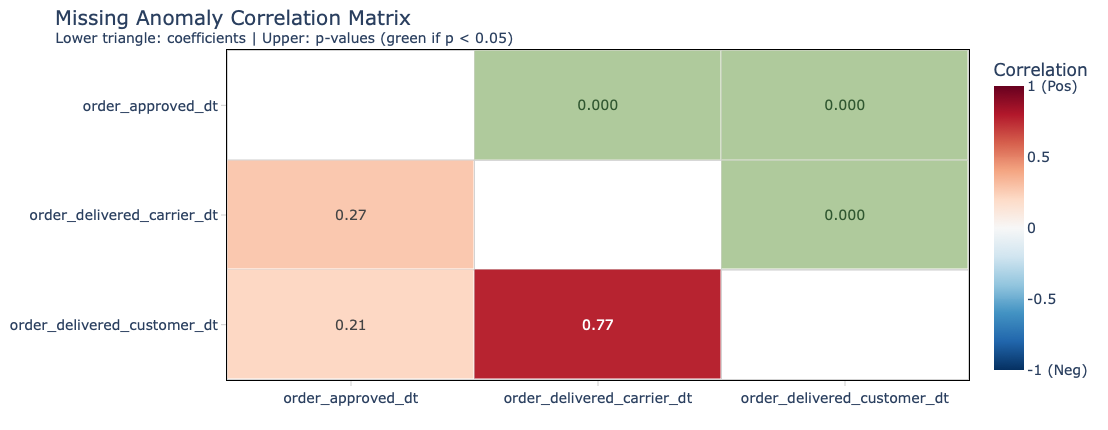

In [7]:
df_orders.explore.anomalies_report()

In [8]:
df["customers"].info()
df["customers"].describe()
df["customers"][df["customers"].isna().any(axis=1)]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state


In [9]:
df["customers"].nunique()
df["customers"]['customer_city'] = df["customers"]['customer_city'].astype('category')
df["customers"]['customer_state'] = df["customers"]['customer_state'].astype('category')

In [10]:
df_customers = fo(df["customers"])
df_customers["customer_id"].explore.info(plot=False)
df_customers["customer_unique_id"].explore.info(plot=False)

In [11]:
df_customers.groupby("customer_unique_id")["customer_id"].nunique().value_counts()
df_customers.groupby("customer_id")["customer_unique_id"].nunique().value_counts()

customer_unique_id
1    99441
Name: count, dtype: int64

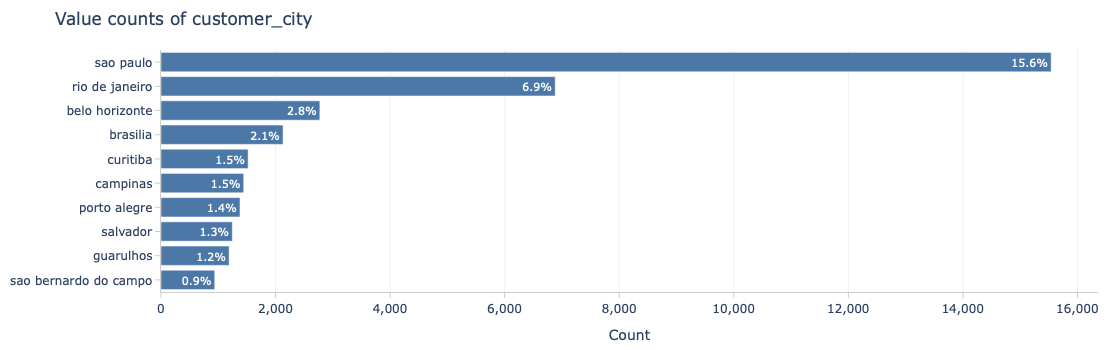

In [12]:
df_customers["customer_city"].explore.info()

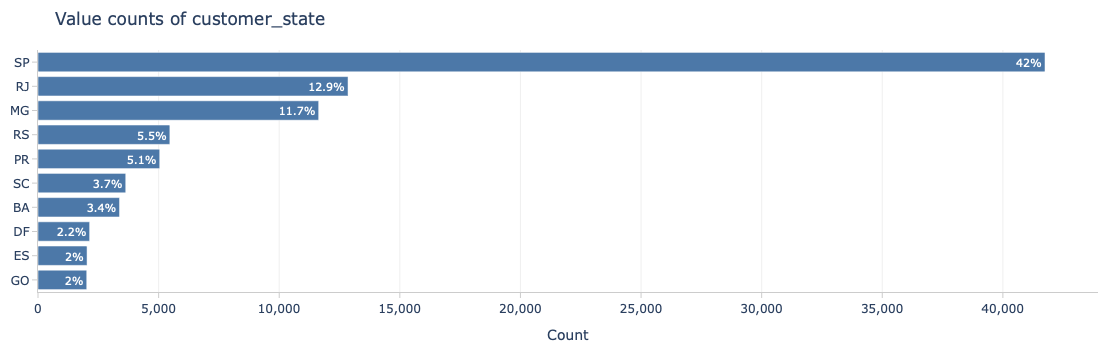

In [13]:
df_customers["customer_state"].explore.info()

In [14]:
df["geolocation"].info()
df["geolocation"][df["geolocation"].isna().any(axis=1)]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state


In [15]:
df["geolocation"].nunique()
df["geolocation"]["geolocation_city"] = df["geolocation"]["geolocation_city"].astype("category")
df["geolocation"]["geolocation_state"] = df["geolocation"]["geolocation_state"].astype("category")

In [16]:
df_geolocation = fo(df["geolocation"])
df_geolocation["geolocation_lat"].explore.info(plot=False)
df_geolocation["geolocation_lng"].explore.info(plot=False)
df_geolocation["geolocation_city"].explore.info(plot=False)
df_geolocation["geolocation_state"].explore.info(plot=False)

In [17]:
df_geo = df_geolocation.drop_duplicates()

df_geo.groupby("geolocation_zip_code_prefix")[["geolocation_city", "geolocation_state"]].nunique().describe()

,geolocation_city,geolocation_state
count,19015.000000,19015.000000
mean,1.467631,1.000421
std,0.538505,0.020508
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,2.000000,1.000000
max,5.000000,2.000000


In [18]:
df["order_payments"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [19]:
df["order_payments"].describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [20]:
df["order_payments"][df["order_payments"].isna().any(axis=1)]

,order_id,payment_sequential,payment_type,payment_installments,payment_value


In [21]:
df["order_payments"].nunique()
df["order_payments"]["payment_type"].astype("category")

0         credit_card
1         credit_card
2         credit_card
3         credit_card
4         credit_card
             ...     
103881         boleto
103882    credit_card
103883    credit_card
103884    credit_card
103885         boleto
Name: payment_type, Length: 103886, dtype: category
Categories (5, object): ['boleto', 'credit_card', 'debit_card', 'not_defined', 'voucher']

In [22]:
df_payments = fo(df["order_payments"])
df_payments["payment_sequential"].explore.info(plot=False)
df_payments["payment_type"].explore.info(plot=False)

In [23]:
df_payments["payment_installments"].explore.info(plot=False)

In [24]:
df_payments["payment_value"].explore.info(plot=False)

,Count,Percent
payment_sequential,4526,4.4%
payment_installments,343,0.3%
payment_value,10390,10.0%


,payment_sequential,payment_installments,payment_value
payment_sequential,,,
payment_installments,< under 1% / ^ under 1%,,
payment_value,< 19.7% / ^ 45.1%,< under 1% / ^ 21.9%,


Column,Category,Total,Anomaly,Anomaly Rate,Total %,Anomaly %,% Diff
payment_type,voucher,5775,4485,77.7%,5.6%,34.1%,28.6%


,order_id,payment_sequential,payment_type,payment_installments,payment_value
39476,2fa0de151b7f1f86d97df7c2a0e11626,1,credit_card,1,18.89
51088,11aa678fe753b76d14deeb477735998f,1,credit_card,1,15.23
64615,958c6a70e60365b576dd696ad29bbca2,5,voucher,1,15.48
89924,4dc5ab28582ada8b30536d03787d2d12,1,credit_card,10,870.69
92286,46a5c63af66fc95c48a6aa738f69049b,1,credit_card,10,618.28


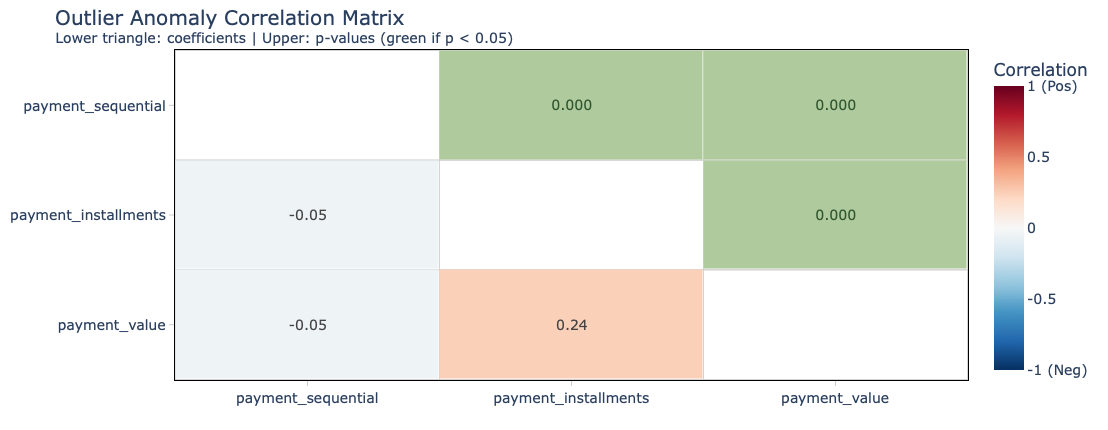

In [25]:
df_payments.explore.anomalies_report(
    anomaly_type = "outlier"
)

In [26]:
temp_outl = df_payments.merge(df["orders"], on='order_id', how='left')
temp_outl['payment_value'].explore.anomalies_over_time(
    time_column='order_purchase_dt'
    , anomaly_type='outlier'
    , freq='D'
)
del temp_outl

In [27]:
df_payments.loc[
    df_payments["payment_installments"] == 0,
    ["payment_type", "payment_installments", "payment_value"]
]

,payment_type,payment_installments,payment_value
46982,credit_card,0,58.69
79014,credit_card,0,129.94


In [28]:
df["order_reviews"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [29]:
df["order_reviews"]["review_creation_date"] = pd.to_datetime(
    df["order_reviews"]["review_creation_date"],
    format = "%Y-%m-%d %H:%M:%S"
)

df["order_reviews"]["review_answer_timestamp"] = pd.to_datetime(
    df["order_reviews"]["review_answer_timestamp"],
    format = "%Y-%m-%d %H:%M:%S"
)

In [30]:
df_reviews = fo(df["order_reviews"])
df_reviews.explore.info()

In [31]:
df_reviews.review_score.explore.info(plot=False)

,Count,Percent
review_comment_title,87656,88.3%
review_comment_message,58247,58.7%


,review_comment_title,review_comment_message
review_comment_title,,
review_comment_message,< 97.0% / ^ 64.5%,


Column,Category,Total,Anomaly,Anomaly Rate,Total %,Anomaly %,% Diff
review_comment_title,nan,87656,87656,100.0%,88.3%,98.1%,9.7%


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
53012,f450753e3d7522b6b9639bc4b69517da,a8f1f10558180d8aebf3fc5550f853a2,4,nan,nan,2017-07-01 00:00:00,2017-07-04 18:25:15
38977,1f60cb446682156869cdd681fef92433,699376e68c8a6abbf01e7160a239c641,5,nan,nan,2017-10-14 00:00:00,2017-10-16 14:46:23
99208,df5fae90e85354241d5d64a8955b2b09,509b86c65fe4e2ad5b96408cfef9755e,5,nan,Entregou dentro do prazo. O produto chegou em condições perfeitas. Estou muito satisfeita!,2018-02-07 00:00:00,2018-02-19 19:47:23
18193,dbd75a6c0e615237083015badd943b46,a6264125a9c50827b115847d47c73a13,5,nan,ADOREI FICOU MUITO LINDO NA MINHA COZINHA!,2017-10-19 00:00:00,2017-10-20 10:17:53
13593,47356da8c38da4cba80737a62826c112,f31100a2f631a83441d0fcd3de9bb098,4,nan,nan,2018-06-30 00:00:00,2018-07-02 12:18:42


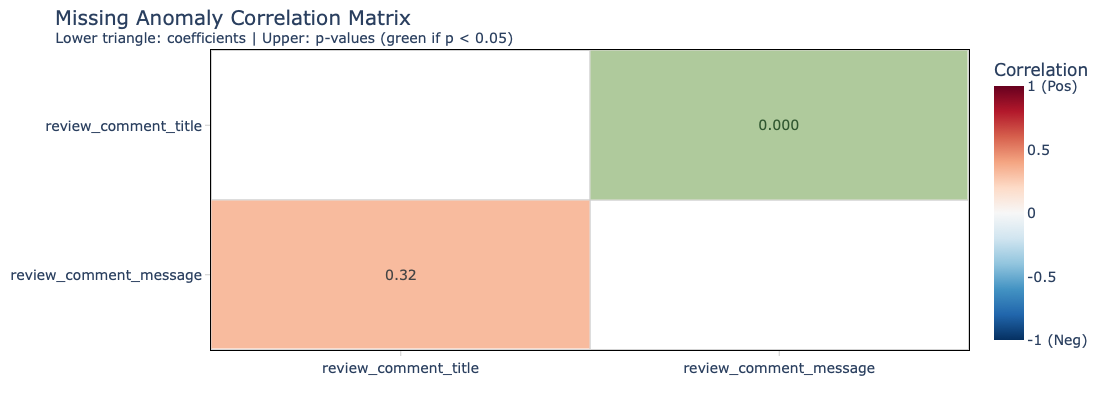

In [32]:
df_reviews.explore.anomalies_report(
    anomaly_type="missing"
)

In [33]:
df_reviews["temp_review_score"] = df_reviews["review_score"].astype("category")
df_reviews.explore.anomalies_by_categories(
    anomaly_type="missing",
    include_columns="temp_review_score"
)
df_reviews = df_reviews.drop(columns=["temp_review_score"])

temp_reviews = df_reviews.merge(df["orders"], on="order_id", how="left")
temp_reviews.explore.anomalies_over_time(
    anomaly_type="missing",
    time_column="order_purchase_dt"
)
del temp_reviews

Column,Category,Total,Anomaly,Anomaly Rate,Total %,Anomaly %,% Diff
temp_review_score,4,19142,17709,92.5%,19.3%,19.8%,0.5%
temp_review_score,5,57328,51906,90.5%,57.8%,58.1%,0.3%
temp_review_score,3,8179,7442,91.0%,8.2%,8.3%,0.1%


In [34]:
df_reviews.review_id.explore.info(plot=False)
df_reviews.order_id.explore.info(plot=False)
df_reviews[['order_id', 'review_id']].duplicated().sum()

np.int64(0)

In [35]:
df_reviews.groupby("review_id")['order_id'].nunique().value_counts()

order_id
1    97621
2      764
3       25
Name: count, dtype: int64

In [36]:
temp_reviews = (
    df_reviews.merge(df["orders"], on="order_id", how="left")
    .merge(df_customers, on="customer_id", how="left")
)
temp_reviews.groupby("review_id")["customer_unique_id"].nunique().value_counts()

customer_unique_id
1    98410
Name: count, dtype: int64

In [37]:
temp = (
    temp_reviews
    .merge(df["order_items"], on="order_id")
)
display(
    temp.groupby("review_id")["product_id"].nunique().value_counts()
)

product_id
1    93880
2     3359
3      357
4       85
5       12
6       10
7        5
8        1
Name: count, dtype: int64

In [38]:
multi_reviews = (
    df_reviews.groupby("review_id")["order_id"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

display(
    temp_reviews[
    temp_reviews["review_id"].isin(multi_reviews)
    ].groupby("review_id")["review_comment_message"].nunique().value_counts()
)

del temp, temp_reviews, multi_reviews

review_comment_message
0    490
1    299
Name: count, dtype: int64

In [39]:
df_reviews.groupby("order_id")["review_score"].nunique().value_counts().sort_index()

review_score
1    98471
2      202
Name: count, dtype: int64

In [40]:
df["order_items"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [41]:
df["order_items"].describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [42]:
df["order_items"]["shipping_limit_date"] = pd.to_datetime(
    df["order_items"]["shipping_limit_date"],
    format = "%Y-%m-%d %H:%M:%S"
)

In [43]:
df_items = fo(df["order_items"])
df_items.price.explore.info(plot=False)
df_items.freight_value.explore.info(plot=False)

In [44]:
df_items.groupby("product_id")["seller_id"].nunique().value_counts()

seller_id
1    31726
2     1030
3      147
4       32
5       10
7        3
8        2
6        1
Name: count, dtype: int64

In [45]:
df_items.groupby("order_id")["seller_id"].nunique().value_counts()

seller_id
1    97388
2     1219
3       54
4        3
5        2
Name: count, dtype: int64

In [46]:
df_items.groupby("order_id")["product_id"].nunique().value_counts()

product_id
1    95430
2     2846
3      298
4       70
6       10
5        8
7        3
8        1
Name: count, dtype: int64

In [47]:
df_items.groupby("product_id")["order_id"].nunique().value_counts()

order_id
1      19564
2       5464
3       2385
4       1349
5        884
       ...  
287        1
306        1
67         1
119        1
150        1
Name: count, Length: 129, dtype: int64

In [48]:
df_items.shipping_limit_date.explore.info()

,Count,Percent
order_item_id,4181,3.7%
price,11076,9.8%
freight_value,10239,9.1%


,order_item_id,price,freight_value
order_item_id,,,
price,< 5.3% / ^ 14.0%,,
freight_value,< 6.5% / ^ 16.0%,< 23.2% / ^ 21.4%,


Column,Category,% Diff


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
80611,b75e81313e6d2e08c716bd845baff9a1,1,ffaaddefb271481c66d4bd79844ecdae,813348c996469b40f2e028d5429d3495,2017-12-15 15:52:46,13.31,8.72
4783,0acd987fec172c76297f6aadad48c67a,1,541fe3a51f05d6f3ee6e730fafa0b8d5,4830e40640734fc1c52cd21127c341d4,2018-07-31 20:35:13,19.99,7.4
62519,8ecc75b89cac1a60578b65339ad6a169,3,8312d7de87652a517f739c42bb4fd3f0,289cdb325fb7e7f891c38608bf9e0962,2018-06-18 15:20:30,29.9,13.55
4870,0b01066982af6f2681ea9b0169f0d987,3,9a442e31dcb07042eca00d73c1933880,e5a3438891c0bfdb9394643f95273d8e,2018-03-23 16:27:19,27.3,18.23
51685,758bed4c2450a7378b75ad480da89662,1,c1ad8ac66c91ad301cefc322ba2adf31,7e93a43ef30c4f03f38b393420bc753a,2017-09-11 22:04:15,719.0,13.85


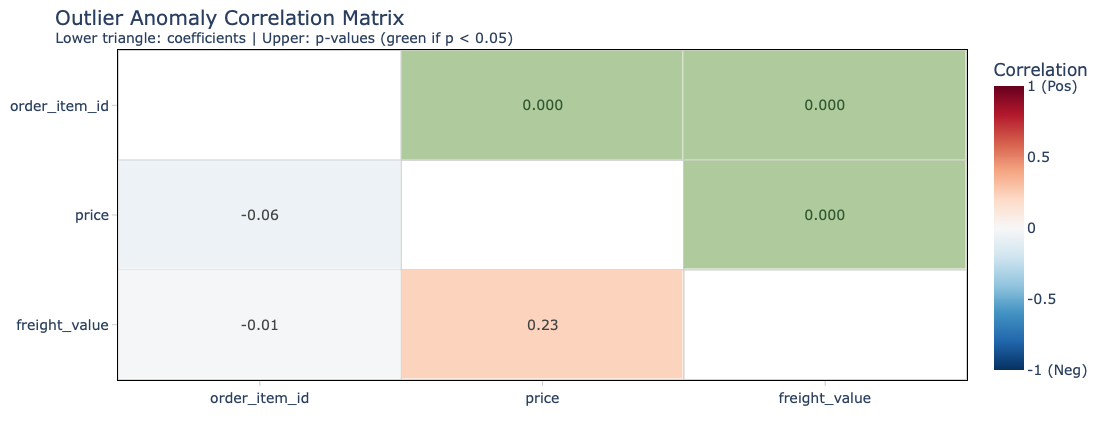

In [49]:
df_items.explore.anomalies_report(
    anomaly_type="outlier"
)

In [50]:
df["products"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [51]:
df["products"].describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [52]:
df["products"].nunique()
df["products"]["product_category_name"] = df["products"]["product_category_name"].astype("category")

In [53]:
df_products = fo(df["products"])
df_products.product_category_name.explore.info(plot=False)

,Count,Percent
product_category_name,610,1.9%
product_name_lenght,610,1.9%
product_description_lenght,610,1.9%
product_photos_qty,610,1.9%
product_weight_g,2,0.0%
product_length_cm,2,0.0%
product_height_cm,2,0.0%
product_width_cm,2,0.0%


,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_category_name,,,,,,,,
product_name_lenght,< 100.0% / ^ 100.0%,,,,,,,
product_description_lenght,< 100.0% / ^ 100.0%,< 100.0% / ^ 100.0%,,,,,,
product_photos_qty,< 100.0% / ^ 100.0%,< 100.0% / ^ 100.0%,< 100.0% / ^ 100.0%,,,,,
product_weight_g,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,,,,
product_length_cm,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 100.0% / ^ 100.0%,,,
product_height_cm,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 100.0% / ^ 100.0%,< 100.0% / ^ 100.0%,,
product_width_cm,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 50.0% / ^ under 1%,< 100.0% / ^ 100.0%,< 100.0% / ^ 100.0%,< 100.0% / ^ 100.0%,


Column,Category,Total,Anomaly,Anomaly Rate,Total %,Anomaly %,% Diff
product_category_name,nan,610,610,100.0%,1.9%,99.8%,98.0%


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
16226,69c2f05e34d543dc71cfe745bfac8499,nan,nan,nan,nan,650.0,30.0,3.0,30.0
7848,83f86eca5473b6d1c7d566223592908d,nan,nan,nan,nan,200.0,16.0,2.0,11.0
5525,db1d1a4569fdbae28a0d3340d907f7af,nan,nan,nan,nan,400.0,16.0,5.0,12.0
15910,e0f33a3329af6716a0bb47fd7a664439,nan,nan,nan,nan,200.0,16.0,13.0,14.0
29135,dfa3272f8e1bad4867677dfca2d061f3,nan,nan,nan,nan,2300.0,34.0,36.0,32.0


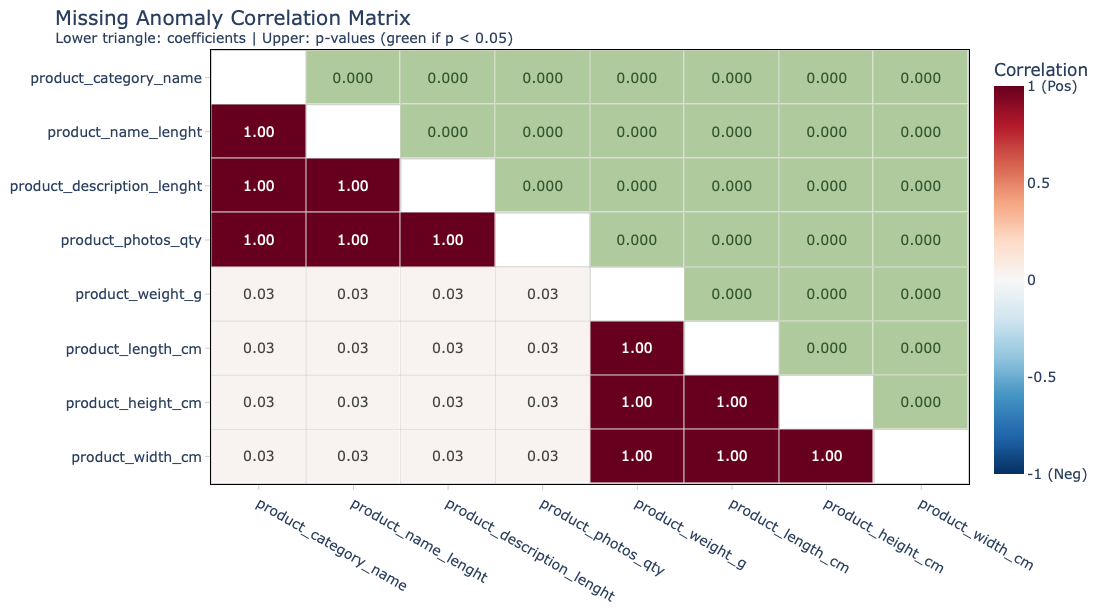

In [54]:
df_products.explore.anomalies_report()

In [55]:
df_products.product_weight_g.explore.info(plot=False)

In [56]:
df_products.sort_values(by="product_weight_g",ascending=False).head(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,59.0,534.0,1.0,40425.0,13.0,65.0,28.0
2417,343c15a347e523f2b6cf38a5db81e179,esporte_lazer,48.0,1232.0,2.0,30000.0,105.0,65.0,20.0
4814,0984eaa8480e41aded35bd7b5131a1c1,beleza_saude,58.0,540.0,1.0,30000.0,55.0,75.0,61.0
15982,c100e5fef1abb5e1c5054d1dac2d83ac,beleza_saude,57.0,534.0,1.0,30000.0,55.0,75.0,61.0
23581,a8baceb529f7e2a5c770cc5b4e3da35d,beleza_saude,55.0,432.0,1.0,30000.0,55.0,75.0,61.0
7234,8d6f2c3454002d3f5aa7479a7fad7794,moveis_sala,52.0,1105.0,1.0,30000.0,80.0,60.0,60.0
31113,ed6e17c5f34a20c7569b6ac2597ee223,automotivo,53.0,611.0,1.0,30000.0,105.0,20.0,50.0
26724,cd1db0c97e4b3644bb52432611e09c58,moveis_decoracao,52.0,583.0,2.0,30000.0,88.0,45.0,41.0
4594,e6574cebbeb21c82802d3a0b682129b6,esporte_lazer,49.0,1263.0,2.0,30000.0,105.0,65.0,25.0
4655,027293c3b6d9e221268d9d6a5ffe5d0b,industria_comercio_e_negocios,57.0,148.0,1.0,30000.0,80.0,50.0,50.0


In [57]:
df["sellers"].info()
df_sellers = fo(df["sellers"])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [58]:
df["sellers"][df["sellers"].isna().any(axis=1)]
df["sellers"]["seller_city"] = df["sellers"]["seller_city"].astype("category")
df["sellers"]["seller_state"] = df["sellers"]["seller_state"].astype("category")

In [59]:
df_sellers.seller_city.explore.info(plot=False)

In [60]:
df_sellers.seller_state.explore.info(plot=False)

In [61]:
df_sellers.explore.anomalies_report()
df_sellers.seller_id.explore.info(plot=False)
df_sellers.seller_zip_code_prefix.explore.info(plot=False)

No missing found in the DataFrame


In [62]:
display(
    df_sellers.groupby("seller_zip_code_prefix")["seller_city"].nunique().value_counts(),
    df_sellers.groupby("seller_id")["seller_zip_code_prefix"].nunique().value_counts()
)

seller_city
1    2212
2      34
Name: count, dtype: int64

seller_zip_code_prefix
1    3095
Name: count, dtype: int64

In [63]:
df["category"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [64]:
df["category"].nunique()

product_category_name            71
product_category_name_english    71
dtype: int64

In [65]:
df["category"]["product_category_name"] = df["category"]["product_category_name"].astype("category")
df["category"]["product_category_name_english"] = df["category"]["product_category_name_english"].astype("category")

In [66]:
order_cost = (
    df_items.groupby("order_id")
    .agg(
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
    .reset_index()
)
order_cost["expected_payment"] = (
    order_cost["total_price"]
    + order_cost["total_freight"]
)

order_payment = (
    df_payments.groupby("order_id")
    .agg(
        actual_payment=("payment_value", "sum")
    )
    .reset_index()
)

payment_check = order_cost.merge(
    order_payment,
    on="order_id",
    how="outer"
)
payment_check["difference"] = (
    payment_check["actual_payment"]
    - payment_check["expected_payment"]
)

display(
    payment_check["difference"].describe(),
    (payment_check["difference"].abs() > 0.01).sum()
)

count    98665.000000
mean         0.029092
std          1.129221
min        -51.620000
25%          0.000000
50%          0.000000
75%          0.000000
max        182.810000
Name: difference, dtype: float64

np.int64(381)

In [67]:
payment_analysis = (
    payment_check.merge(
        df_payments[["order_id", "payment_type"]],
        on="order_id",
        how="left"
    )
)
    
payment_analysis[payment_analysis["difference"].abs() > 0.01].groupby("payment_type").size().sort_values(ascending=False)

payment_type
credit_card    356
boleto          26
voucher         13
debit_card       9
dtype: int64

In [68]:
mismatch = payment_check[
    payment_check["difference"].abs() > 0.01
].copy()

mismatch["difference"].describe()

count    381.000000
mean       7.534961
std       16.564267
min      -51.620000
25%        0.010000
50%        3.090000
75%        9.570000
max      182.810000
Name: difference, dtype: float64

In [69]:
df_orders.groupby(df_orders["order_purchase_dt"].dt.to_period("M")).size()

order_purchase_dt
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

In [70]:
df_orders = df_orders[
    df_orders.order_purchase_dt.between(pd.to_datetime('2017-01-01'), pd.to_datetime('2018-09-01'), inclusive='left')
    | df_orders.order_purchase_dt.isna()
]

In [71]:
df_reviews = df_reviews[
    (df_reviews.review_creation_date >= pd.to_datetime("2017-01-01")) 
    | df_reviews.review_creation_date.isna()
]

In [72]:
df_customers = df_customers.merge(df_orders[["customer_id"]], on="customer_id", how="inner")
df_payments = df_payments.merge(df_orders[["order_id"]], on="order_id", how="inner")
df_reviews = df_reviews.merge(df_orders[["order_id"]], on="order_id", how="inner")
df_items = df_items.merge(df_orders[["order_id"]], on="order_id", how="inner")

In [73]:
mask_carrier_missing = (
    df_orders['order_delivered_carrier_dt'].isna()
    & (
        (df_orders['order_status'] == 'delivered')
        | df_orders['order_delivered_customer_dt'].notna()
    )
)
mask_carrier_missing.value_counts()

False    99090
True         2
Name: count, dtype: int64

In [74]:
median_carrier_time = (
    df_orders['order_delivered_carrier_dt']
    - df_orders['order_approved_dt']
).median()

df_orders.loc[mask_carrier_missing,'order_delivered_carrier_dt'] = (
    df_orders.loc[mask_carrier_missing, 'order_approved_dt']
    + median_carrier_time
)


In [75]:
mask_approved_missing = (
    df_orders['order_approved_dt'].isna()
    & (
        df_orders['order_delivered_carrier_dt'].notna()
        | df_orders['order_delivered_customer_dt'].notna()
        | df_orders['order_status'] == 'delivered'
    )
)
mask_approved_missing.value_counts()

False    99092
Name: count, dtype: int64

In [76]:
mask_customer_missing = (
    df_orders['order_delivered_customer_dt'].isna()
    & (df_orders['order_status'] == 'delivered')
)
mask_customer_missing.value_counts()

False    99084
True         8
Name: count, dtype: int64

In [77]:
valid_customer_delivery = (
    df_orders['order_delivered_carrier_dt'].notna()
    & df_orders['order_delivered_customer_dt'].notna()
    & (
        df_orders['order_delivered_customer_dt']
        >= df_orders['order_delivered_carrier_dt']
    )
)

median_customer_delivery_time = (
    df_orders.loc[
        valid_customer_delivery,
        'order_delivered_customer_dt'
    ]
    - df_orders.loc[
        valid_customer_delivery,
        'order_delivered_carrier_dt'
    ]
).median()

df_orders.loc[
    mask_customer_missing,
    'order_delivered_customer_dt'
] = (
    df_orders.loc[
        mask_customer_missing,
        'order_delivered_carrier_dt'
    ]
    + median_customer_delivery_time
)

In [78]:
df_products['product_category_name'] = df_products['product_category_name'].cat.add_categories(['Missing in Products'])
df_products['product_category_name'] = df_products['product_category_name'].fillna('Missing in Products')

In [79]:
missing_categories = (
    df_products.loc[
        df_products['product_weight_g'].isna(),
        'product_category_name'
    ]
    .dropna()
    .unique()
)

df_products[
    df_products['product_category_name'].isin(missing_categories)
]['product_category_name'].value_counts()

product_category_name
bebes                                 919
Missing in Products                   610
ferramentas_jardim                      0
livros_interesse_geral                  0
moveis_decoracao                        0
                                     ... 
construcao_ferramentas_seguranca        0
construcao_ferramentas_jardim           0
construcao_ferramentas_iluminacao       0
construcao_ferramentas_ferramentas      0
fashion_roupa_infanto_juvenil           0
Name: count, Length: 74, dtype: int64

In [80]:
cols_to_fill = [
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

df_products[cols_to_fill] = (
    df_products[cols_to_fill]
    .fillna(
        df_products
        .groupby('product_category_name')[cols_to_fill]
        .transform('median')
    )
)
df_products[cols_to_fill].isna().sum()

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_2827/1367920584.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('product_category_name')[cols_to_fill]


product_weight_g     0
product_length_cm    0
product_height_cm    0
product_width_cm     0
dtype: int64

In [81]:
# Calculate category median excluding zero values
category_median = (
    df_products["product_weight_g"]
    .where(df_products["product_weight_g"] > 0)
    .groupby(df_products["product_category_name"])
    .transform("median")
)

# Replace zero values
mask = df_products["product_weight_g"].eq(0)

df_products.loc[mask, "product_weight_g"] = category_median[mask]

df_products.loc[mask, ["product_category_name", "product_weight_g"]]

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_2827/1820002203.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(df_products["product_category_name"])


,product_category_name,product_weight_g
9769,cama_mesa_banho,1250.0
13683,cama_mesa_banho,1250.0
14997,cama_mesa_banho,1250.0
32079,cama_mesa_banho,1250.0


In [82]:
df_payments.loc[
    df_payments["payment_installments"] == 0,
    "payment_installments"
] = 1

df_payments.isna().value_counts()

order_id  payment_sequential  payment_type  payment_installments  payment_value
False     False               False         False                 False            103520
Name: count, dtype: int64

In [83]:
df_geolocation.drop_duplicates(inplace=True)

df_geolocation = (
    df_geolocation
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        geolocation_lat=("geolocation_lat", "mean"),
        geolocation_lng=("geolocation_lng", "mean"),
        geolocation_city=("geolocation_city", lambda x: x.mode().iloc[0]),
        geolocation_state=("geolocation_state", lambda x: x.mode().iloc[0])
    )
)

df_geolocation.groupby("geolocation_zip_code_prefix")[["geolocation_city", "geolocation_state"]].nunique().describe()

,geolocation_city,geolocation_state
count,19015.0,19015.0
mean,1.0,1.0
std,0.0,0.0
min,1.0,1.0
25%,1.0,1.0
50%,1.0,1.0
75%,1.0,1.0
max,1.0,1.0


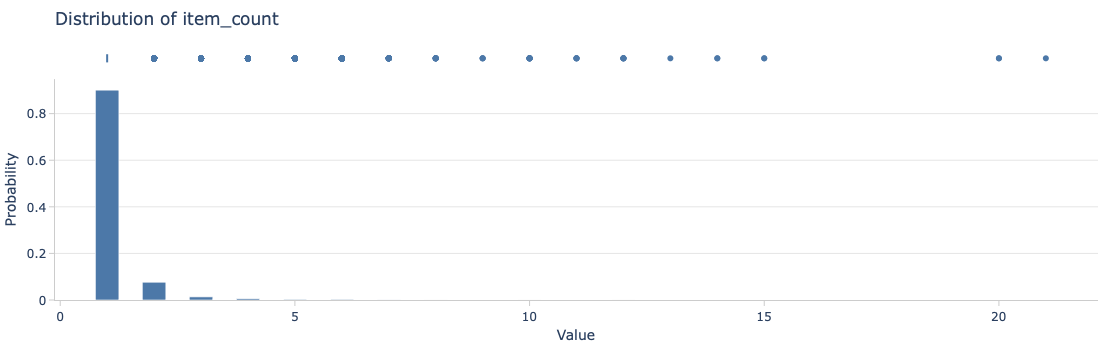

In [84]:
order_value_items = (
    df_items
    .groupby("order_id", as_index=False)
    .agg(
        item_count=("order_item_id", "count"),
        product_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)

order_value_items["order_value_items"] = (
    order_value_items["product_value"]
    + order_value_items["freight_value"]
)

order_value_items.head()
order_value_items["item_count"].explore.info()

In [85]:
order_value_payments = (
    df_payments
    .groupby("order_id", as_index=False)
    .agg(
        order_value_payments=("payment_value", "sum")
    )
)

order_value_payments.head()

,order_id,order_value_payments
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [86]:
product_revenue = (
    df_items
    .groupby("product_id", as_index=False)
    .agg(
        product_revenue=("price", "sum")
    )
)

In [87]:
product_cnt = (
    df_items
    .groupby("product_id", as_index=False)
    .agg(
        product_cnt=("order_item_id", "count")
    )
)

product_cnt.nlargest(10, "product_cnt")

,product_id,product_cnt
22009,aca2eb7d00ea1a7b8ebd4e68314663af,527
19651,99a4788cb24856965c36a24e339b6058,488
8574,422879e10f46682990de24d770e7f83d,484
7333,389d119b48cf3043d311335e499d9c6b,392
7049,368c6c730842d78016ad823897a372db,388
10787,53759a2ecddad2bb87a079a1f1519f73,373
26906,d1c427060a0f73f6b889a5c7c61f2ac4,343
10814,53b36df67ebb7c41585e8d54d6772e08,323
2784,154e7e31ebfa092203795c972e5804a6,281
8013,3dd2a17168ec895c781a9191c1e95ad7,274


In [88]:
category_revenue = (
    df_items
    .merge(
        df_products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name", as_index=False)
    .agg(
        category_revenue=("price", "sum")
    )
)

category_revenue.head()

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_2827/8002667.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("product_category_name", as_index=False)


,product_category_name,category_revenue
0,agro_industria_e_comercio,72530.47
1,alimentos,29313.51
2,alimentos_bebidas,15179.48
3,artes,24202.64
4,artes_e_artesanato,1814.01


In [89]:
df_orders["order_handling_time_days"] = np.ceil(
    (
        df_orders["order_delivered_carrier_dt"] -
        df_orders["order_approved_dt"]
    ).dt.total_seconds() / (24 * 3600)
).astype("Int64")

df_orders["order_handling_time_days"].head()

(df_orders["order_handling_time_days"] < 0).sum()

np.int64(458)

In [90]:
median_handling_time = int(np.ceil(
    df_orders.loc[
        df_orders["order_handling_time_days"] >= 0,
        "order_handling_time_days"
    ].median()
))

df_orders.loc[
    df_orders["order_handling_time_days"] < 0,
    "order_handling_time_days"
] = median_handling_time

(df_orders["order_handling_time_days"] < 0).sum()

np.int64(0)

In [91]:
df_orders["delivery_time_days"] = np.ceil(
    (
    df_orders["order_delivered_customer_dt"] -
    df_orders["order_purchase_dt"]
    ).dt.total_seconds() / (24 * 3600)
).astype("Int64")

(df_orders["delivery_time_days"] < 0).sum()

np.int64(0)

In [92]:
df_orders["carrier_time_days"] = np.ceil(
    (
    df_orders["order_delivered_customer_dt"] -
    df_orders["order_delivered_carrier_dt"]
    ).dt.total_seconds() / (24 * 3600)
).astype("Int64")

(df_orders["carrier_time_days"] < 0).sum()

np.int64(14)

In [93]:
median_handling_time = int(np.ceil(
    df_orders.loc[
        df_orders["carrier_time_days"] >= 0,
        "carrier_time_days"
    ].median()
))

df_orders.loc[
    df_orders["carrier_time_days"] < 0,
    "carrier_time_days"
] = median_handling_time

(df_orders["carrier_time_days"] < 0).sum()

np.int64(0)

In [94]:
df_orders["is_late_delivery"] = pd.NA

delivered = (
    (df_orders["order_status"] == "delivered") &
    df_orders["order_delivered_customer_dt"].notna() &
    df_orders["order_estimated_delivery_dt"].notna()
)

df_orders.loc[
    delivered,
    "is_late_delivery"
] = (
    df_orders.loc[delivered, "order_delivered_customer_dt"]
    >
    df_orders.loc[delivered, "order_estimated_delivery_dt"]
)

df_orders["is_late_delivery"] = (
    df_orders["is_late_delivery"].astype("boolean")
)

In [95]:
df_orders["is_delivered"] = (
    df_orders["order_status"] == "delivered"
)

In [96]:
df_order_customer = (
    df_orders[
        ["order_id", "customer_id", "order_purchase_dt"]
    ]
    .merge(
        df_customers[
            ["customer_id", "customer_unique_id"]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        order_value_items[
            ["order_id", "order_value_items"]
        ],
        on="order_id",
        how="left"
    )
    .merge(
        order_value_payments[
            ["order_id", "order_value_payments"]
        ],
        on="order_id",
        how="left"
    )
)

In [97]:
customer_behavior = (
    df_order_customer
    .groupby("customer_unique_id", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_spending=("order_value_payments", "sum"),
        avg_order_value=("order_value_payments", "mean")
    )
)

customer_behavior["avg_order_value"] = (
    customer_behavior["avg_order_value"]
    .round(2)
)

customer_behavior["total_spending"] = (
    customer_behavior["total_spending"]
    .round(2)
)

In [98]:
temp_order_review_agg = (
    df_reviews
    .groupby("order_id", as_index=False)
    .agg(
        review_score=("review_score", "mean")
    )
)

temp_order_review_agg["review_sentiment"] = pd.cut(
    temp_order_review_agg["review_score"],
    bins=[0, 2, 3, 5],
    labels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

df_order_analysis = (
    df_orders[
        [
            "order_id",
            "customer_id",
            "order_purchase_dt",
            "delivery_time_days",
            "order_handling_time_days",
            "carrier_time_days",
            "is_late_delivery",
            "is_delivered"
        ]
    ]
    .merge(
        order_value_payments,
        on="order_id",
        how="left"
    )
    .merge(
        temp_order_review_agg,
        on="order_id",
        how="left"
    )
)

del temp_order_review_agg

df_order_analysis.head(10)

,order_id,customer_id,order_purchase_dt,delivery_time_days,order_handling_time_days,carrier_time_days,is_late_delivery,is_delivered,order_value_payments,review_score,review_sentiment
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,9,3,7,False,True,38.71,4.0,Positive
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,14,1,13,False,True,141.46,4.0,Positive
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,10,1,10,False,True,179.12,5.0,Positive
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,14,4,10,False,True,72.20,5.0,Positive
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,3,1,2,False,True,28.62,5.0,Positive
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,2017-07-09 21:57:05,17,2,15,False,True,175.26,4.0,Positive
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,2017-04-11 12:22:08,<NA>,<NA>,<NA>,<NA>,False,65.95,2.0,Negative
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,2017-05-16 13:10:30,10,6,5,False,True,75.16,5.0,Positive
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,2017-01-23 18:29:09,10,2,7,False,True,35.95,1.0,Negative
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,2017-07-29 11:55:02,19,13,6,False,True,169.76,5.0,Positive


In [99]:
df_order_analysis.groupby("order_id")["review_score"].nunique().value_counts().sort_index()

review_score
0      762
1    98330
Name: count, dtype: int64

In [100]:
df_order_analysis["review_score"].isna().sum()

np.int64(762)

In [101]:
df_order_analysis.loc[
    df_order_analysis["review_score"].isna(),
    "is_delivered"
].value_counts()

is_delivered
True     643
False    119
Name: count, dtype: int64

In [102]:
df_orders.keys()

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_dt',
       'order_approved_dt', 'order_delivered_carrier_dt',
       'order_delivered_customer_dt', 'order_estimated_delivery_dt',
       'order_handling_time_days', 'delivery_time_days', 'carrier_time_days',
       'is_late_delivery', 'is_delivered'],
      dtype='object')

In [103]:
df_orders_analysis = df_orders.merge(
    order_value_items[
        [
            "order_id",
            "item_count",
            "freight_value",
            "order_value_items"
        ]
    ],
    on="order_id",
    how="left"
)

In [104]:
df_orders_analysis.rename(
    columns={"order_value_items": "order_value"},
    inplace=True
)
df_orders_analysis["item_count"].isna().sum()

np.int64(739)

In [105]:
df_orders_analysis.loc[
    df_orders_analysis["item_count"].isna(),
    "is_delivered"
].value_counts()

is_delivered
False    739
Name: count, dtype: int64

In [106]:
df_payments.keys()

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')

In [107]:
payment_type_count = (
    df_payments
    .groupby("order_id")["payment_type"]
    .nunique()
)
payment_type_count.value_counts()

payment_type
1    96851
2     2241
Name: count, dtype: int64

In [108]:
temp_order_payment_agg = (
    df_payments
    .groupby("order_id", as_index=False)
    .agg(
        payment_installments=("payment_installments", "sum"),
        payment_type=(
            "payment_type",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        )
    )
)
temp_order_payment_agg["order_id"].duplicated().sum()

df_orders_analysis = df_orders_analysis.merge(
    temp_order_payment_agg,
    on="order_id",
    how="left"
)

del temp_order_payment_agg

df_orders_analysis[
    ["payment_installments", "payment_type"]
].isna().sum()

payment_installments    0
payment_type            0
dtype: int64

In [109]:
df_orders_analysis = df_orders_analysis.merge(
    df_customers[
        [
            "customer_id",
            "customer_unique_id",
        ]
    ],
    on="customer_id",
    how="left"
)


df_orders_analysis = df_orders_analysis.merge(
    df_order_analysis[
        [
        "order_id",
        "review_score",
        "review_sentiment"
        ]
    ],
    on="order_id",
    how="left"
)

df_orders_analysis[["order_id","customer_unique_id", "review_score","review_sentiment"]].head()

,order_id,customer_unique_id,review_score,review_sentiment
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,4.0,Positive
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,4.0,Positive
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,5.0,Positive
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,5.0,Positive
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,5.0,Positive


In [110]:
df_orders_analysis[["order_id", "review_score"]].duplicated().sum()

np.int64(0)

In [111]:
df_orders_analysis[
    [
        "item_count",
        "freight_value",
        "order_value",
        "payment_installments",
        "payment_type",
        "customer_unique_id",
        "review_score",
        "review_sentiment"
    ]
].isna().sum()

item_count              739
freight_value           739
order_value             739
payment_installments      0
payment_type              0
customer_unique_id        0
review_score            762
review_sentiment        762
dtype: int64

In [112]:
df_customers.keys()

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [113]:
customer_order_location = (
    df_orders[
        [
            "order_id",
            "customer_id",
            "order_purchase_dt"
        ]
    ]
    .merge(
        df_customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_city",
                "customer_state"
            ]
        ],
        on="customer_id",
        how="left"
    )
)

In [114]:
customer_order_location = (
    customer_order_location
    .sort_values("order_purchase_dt")
)

df_customer_analysis = (
    customer_order_location
    .drop_duplicates(
        subset="customer_unique_id",
        keep="last"
    )
    [
        [
            "customer_unique_id",
            "customer_city",
            "customer_state"
        ]
    ]
    .reset_index(drop=True)
)

del customer_order_location

In [115]:
df_customer_analysis.groupby("customer_unique_id")[["customer_city","customer_state"]].nunique().describe()

,customer_city,customer_state
count,95774.0,95774.0
mean,1.0,1.0
std,0.0,0.0
min,1.0,1.0
25%,1.0,1.0
50%,1.0,1.0
75%,1.0,1.0
max,1.0,1.0


In [116]:
df_orders_analysis.keys()

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_dt',
       'order_approved_dt', 'order_delivered_carrier_dt',
       'order_delivered_customer_dt', 'order_estimated_delivery_dt',
       'order_handling_time_days', 'delivery_time_days', 'carrier_time_days',
       'is_late_delivery', 'is_delivered', 'item_count', 'freight_value',
       'order_value', 'payment_installments', 'payment_type',
       'customer_unique_id', 'review_score', 'review_sentiment'],
      dtype='object')

In [117]:
temp_customer_orders = (
    df_orders_analysis[
        [
            "customer_unique_id",
            "order_id",
            "order_status",
            "order_purchase_dt"
        ]
    ]
    .sort_values(
        ["customer_unique_id", "order_purchase_dt"]
    )
    .copy()
)

In [118]:
temp_customer_orders["purchase_interval_days"] = (
    temp_customer_orders
    .groupby("customer_unique_id")["order_purchase_dt"]
    .diff()
    .dt.total_seconds()
    / (24 * 3600)
)

In [119]:
customer_purchase_agg = (
    temp_customer_orders
    .groupby("customer_unique_id", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        canceled_order_count=(
            "order_status",
            lambda x: (x == "canceled").sum()
        ),
        first_purchase_dt=("order_purchase_dt", "min"),
        last_purchase_dt=("order_purchase_dt", "max"),
        avg_purchase_interval_days=(
            "purchase_interval_days",
            "mean"
        )
    )
)

customer_purchase_agg["avg_purchase_interval_days"] = (
    customer_purchase_agg["avg_purchase_interval_days"]
    .round()
    .astype("Int64")
)

In [120]:
customer_purchase_agg["cancellation_rate"] = (
    customer_purchase_agg["canceled_order_count"]
    / customer_purchase_agg["order_count"]
)

customer_purchase_agg["cancellation_rate"] = (
    customer_purchase_agg["cancellation_rate"]
    .round(2)
) 

In [121]:
customer_purchase_agg = customer_purchase_agg[
    [
        "customer_unique_id",
        "order_count",
        "canceled_order_count",
        "cancellation_rate",
        "first_purchase_dt",
        "last_purchase_dt",
        "avg_purchase_interval_days"
    ]
]

In [122]:
df_customer_analysis = df_customer_analysis.merge(
    customer_purchase_agg,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

In [123]:
df_customer_analysis.keys()

Index(['customer_unique_id', 'customer_city', 'customer_state', 'order_count',
       'canceled_order_count', 'cancellation_rate', 'first_purchase_dt',
       'last_purchase_dt', 'avg_purchase_interval_days'],
      dtype='object')

In [124]:
customer_value_agg = (
    df_orders_analysis
    .groupby("customer_unique_id", as_index=False)
    .agg(
        total_spend=("order_value", "sum"),
        avg_order_value=("order_value", "mean"),
        total_freight=("freight_value", "sum")
    )
)

In [125]:
df_customer_analysis = df_customer_analysis.merge(
    customer_value_agg,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

df_customer_analysis["avg_order_value"] = (
    df_customer_analysis["avg_order_value"]
    .round(2)
)

df_customer_analysis[
    [
        "customer_unique_id",
        "total_spend",
        "avg_order_value",
        "total_freight"
    ]
].head(10)

,customer_unique_id,total_spend,avg_order_value,total_freight
0,f7b981e8a280e455ac3cbe0d5d171bd1,19.62,19.62,8.72
1,728e4a7d0db4845270091ded0923c71f,46.86,15.62,26.16
2,da9c90677b1963eca1cf8a14c338cf6e,19.62,19.62,8.72
3,ef89f6e31311594d74becf9e18c73693,20.62,20.62,8.72
4,29a63a400c3ca9982907ce8de1f19527,19.62,19.62,8.72
5,b6b2c3c8fd76769b478618a3c2505009,19.62,19.62,8.72
6,d753459418d268407f19b64be28e3c5a,38.24,19.12,17.44
7,6222ef69df52b4ed71be551725551cc0,56.86,18.95,26.16
8,83e7958a94bd7f74a9414d8782f87628,73.48,18.37,34.88
9,f7be9bec658c62ab6240b44cd26c0b84,38.24,19.12,17.44


In [126]:
customer_payment_agg = (
    df_orders_analysis
    .groupby("customer_unique_id", as_index=False)
    .agg(
        usual_payment_type=(
            "payment_type",
            lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA
        ),
        usual_payment_installments=(
            "payment_installments",
            lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA
        )
    )
)

In [127]:
df_customer_analysis = df_customer_analysis.merge(
    customer_payment_agg,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

In [128]:
df_customer_analysis[
    [
        "customer_unique_id",
        "usual_payment_type",
        "usual_payment_installments"
    ]
].info()

<class 'frameon.core.base.FrameOn'>
RangeIndex: 95774 entries, 0 to 95773
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   customer_unique_id          95774 non-null  object
 1   usual_payment_type          95774 non-null  object
 2   usual_payment_installments  95774 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 2.2+ MB


In [129]:
customer_experience_agg = (
    df_orders_analysis
    .groupby("customer_unique_id", as_index=False)
    .agg(
        avg_review_score=("review_score", "mean"),
        late_delivery_rate=("is_late_delivery", "mean")
    )
)

customer_experience_agg["avg_review_score"] = (
    customer_experience_agg["avg_review_score"]
    .round(1)
)

customer_experience_agg["late_delivery_rate"] = (
    customer_experience_agg["late_delivery_rate"]
    .round(2)
)

customer_experience_agg["avg_review_sentiment"] = pd.cut(
    customer_experience_agg["avg_review_score"],
    bins=[0, 2, 3, 5],
    labels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

df_customer_analysis = df_customer_analysis.merge(
    customer_experience_agg,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

df_customer_analysis.head(5)

,customer_unique_id,customer_city,customer_state,order_count,canceled_order_count,cancellation_rate,first_purchase_dt,last_purchase_dt,avg_purchase_interval_days,total_spend,avg_order_value,total_freight,usual_payment_type,usual_payment_installments,avg_review_score,late_delivery_rate,avg_review_sentiment
0,f7b981e8a280e455ac3cbe0d5d171bd1,curitiba,PR,1,0,0.0,2017-01-05 11:56:06,2017-01-05 11:56:06,<NA>,19.62,19.62,8.72,credit_card,1,5.0,0.0,Positive
1,728e4a7d0db4845270091ded0923c71f,curitiba,PR,3,0,0.0,2017-01-05 12:06:36,2017-01-05 12:11:23,0,46.86,15.62,26.16,boleto,1,5.0,0.0,Positive
2,da9c90677b1963eca1cf8a14c338cf6e,curitiba,PR,1,0,0.0,2017-01-05 12:14:58,2017-01-05 12:14:58,<NA>,19.62,19.62,8.72,boleto,1,5.0,0.0,Positive
3,ef89f6e31311594d74becf9e18c73693,curitiba,PR,1,0,0.0,2017-01-05 13:01:48,2017-01-05 13:01:48,<NA>,20.62,20.62,8.72,boleto,1,5.0,0.0,Positive
4,29a63a400c3ca9982907ce8de1f19527,curitiba,PR,1,0,0.0,2017-01-05 13:31:22,2017-01-05 13:31:22,<NA>,19.62,19.62,8.72,boleto,1,5.0,0.0,Positive


In [130]:
df_items.groupby("product_id")["order_id"].nunique().describe()

count    32787.000000
mean         3.113795
std          9.475835
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        467.000000
Name: order_id, dtype: float64

In [131]:
df_items.groupby(
    ["order_id", "product_id"]
).size().value_counts().sort_index()

1     95030
2      5364
3       947
4       389
5       168
6       171
7         4
8         2
9         2
10        5
11        1
12        2
13        1
14        2
15        2
20        2
Name: count, dtype: int64

In [132]:
df_product_analysis = df_products[
    [
        "product_id",
        "product_category_name",
        "product_weight_g",
        "product_photos_qty",
        "product_name_lenght",
        "product_description_lenght",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
].copy()

df_product_analysis = df_product_analysis.rename(
    columns={
        "product_name_lenght": "product_name_length",
        "product_description_lenght": "product_description_length"
    }
)

df_product_analysis["product_volume_cm3"] = (
    df_product_analysis["product_length_cm"]
    * df_product_analysis["product_height_cm"]
    * df_product_analysis["product_width_cm"]
)

df_product_analysis = df_product_analysis.drop(
    columns=[
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
)

In [133]:
df_items.merge(
    df_orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)["order_status"].value_counts(dropna=False)

order_status
delivered     109880
shipped         1174
canceled         527
processing       355
invoiced         340
approved           3
Name: count, dtype: int64

In [134]:
df_items_sales = (
    df_items
    .merge(
        df_orders[
            ["order_id", "order_status", "order_purchase_dt"]
        ],
        on="order_id",
        how="left",
        validate="many_to_one"
    )
    .loc[lambda x: x["order_status"] == "delivered"]
)

product_sales_agg = (
    df_items_sales
    .groupby("product_id", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        units_sold=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        avg_selling_price=("price", "mean"),
        first_sale_dt=("order_purchase_dt", "min"),
        last_sale_dt=("order_purchase_dt", "max")
    )
)

product_sales_agg[
    ["total_revenue", "avg_selling_price"]
] = (
    product_sales_agg[
        ["total_revenue", "avg_selling_price"]
    ]
    .round(2)
)

In [135]:
df_product_analysis = df_product_analysis.merge(
    product_sales_agg,
    on="product_id",
    how="left",
    validate="one_to_one"
)

del product_sales_agg, df_items_sales

In [136]:
temp_product_review = (
    df_items[
        ["order_id", "product_id"]
    ]
    .drop_duplicates(
        subset=["order_id", "product_id"]
    )
    .merge(
        df_order_analysis[
            ["order_id", "review_score", "review_sentiment"]
        ],
        on="order_id",
        how="left",
        validate="many_to_one"
    )
)

In [137]:
sentiment_map = {
    "Negative": -1,
    "Neutral": 0,
    "Positive": 1
}

temp_product_review["review_sentiment_score"] = (
    temp_product_review["review_sentiment"]
    .map(sentiment_map)
    .astype("float")
)

In [138]:
product_experience_agg = (
    temp_product_review
    .groupby("product_id", as_index=False)
    .agg(
        avg_review_score=("review_score", "mean"),
        review_count=("review_score", "count"),
        avg_review_sentiment=("review_sentiment_score", "mean")
    )
)

product_experience_agg[
    ["avg_review_score","avg_review_sentiment"]
] = (
    product_experience_agg[
        ["avg_review_score","avg_review_sentiment"]
    ]
    .round(2)
)

In [139]:
df_orders_analysis.keys()

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_dt',
       'order_approved_dt', 'order_delivered_carrier_dt',
       'order_delivered_customer_dt', 'order_estimated_delivery_dt',
       'order_handling_time_days', 'delivery_time_days', 'carrier_time_days',
       'is_late_delivery', 'is_delivered', 'item_count', 'freight_value',
       'order_value', 'payment_installments', 'payment_type',
       'customer_unique_id', 'review_score', 'review_sentiment'],
      dtype='object')

In [140]:
df_customer_analysis.keys()

Index(['customer_unique_id', 'customer_city', 'customer_state', 'order_count',
       'canceled_order_count', 'cancellation_rate', 'first_purchase_dt',
       'last_purchase_dt', 'avg_purchase_interval_days', 'total_spend',
       'avg_order_value', 'total_freight', 'usual_payment_type',
       'usual_payment_installments', 'avg_review_score', 'late_delivery_rate',
       'avg_review_sentiment'],
      dtype='object')

In [141]:
df_product_analysis.keys()

Index(['product_id', 'product_category_name', 'product_weight_g',
       'product_photos_qty', 'product_name_length',
       'product_description_length', 'product_volume_cm3', 'order_count',
       'units_sold', 'total_revenue', 'avg_selling_price', 'first_sale_dt',
       'last_sale_dt'],
      dtype='object')

## 4.1 Daily Commercial and Business KPI Mart

### 1. Primary and Reference GMV Definitions

**Output:** `mart_daily_business_kpi`  
**Grain:** one row per calendar purchase date (`order_date`).

The primary operational KPI is **Placed GMV**: the item price plus item-level freight value of orders placed on date *t*, provided that item-based order value is available. It does not condition on final order status and does not use `payment_value`.

The previous metric is retained explicitly as **Delivered GMV**: the same item-plus-freight order value, restricted to orders whose final status is `delivered`. Delivered GMV is a retrospective matured outcome because final delivery status is only known after purchase.

| KPI | Definition | Population / denominator |
|---|---|---|
| `placed_gmv` | Gross item-plus-freight value generated at order placement | All orders with non-null item-based `order_value`; no status filter |
| `placed_order_count` | Orders contributing to Placed GMV | Distinct valid-value orders |
| `placed_aov` | Average placed order value | `placed_gmv / placed_order_count` |
| `delivered_gmv` | Retrospective item-plus-freight value of delivered orders | Delivered orders with non-null `order_value` |
| `revenue_order_count` | Orders contributing to Delivered GMV | Delivered valid-value orders |
| `delivered_aov` | Average delivered order value | `delivered_gmv / revenue_order_count` |

Other existing daily KPIs are preserved. `order_count` and customer metrics continue to describe all placed orders, while delivered item metrics retain the retrospective Delivered-GMV population.

### 2. Order-Level Item Aggregation

Check data quality before start

In [142]:
# Guardrails: use existing analytical tables and fail early if their contracts change.
mart_required_columns = {
    "order_id", "customer_unique_id", "order_purchase_dt",
    "order_status", "order_value", "is_late_delivery",
    "review_score", "order_handling_time_days",
    "carrier_time_days", "delivery_time_days"
}
mart_missing_columns = mart_required_columns.difference(df_orders_analysis.columns)
assert not mart_missing_columns, f"Missing required columns: {sorted(mart_missing_columns)}"
assert df_orders_analysis["order_id"].is_unique, (
    "df_orders_analysis must remain one row per order before daily aggregation."
)
assert df_orders_analysis["order_purchase_dt"].notna().all(), (
    "order_purchase_dt cannot be null because it defines the mart grain."
)
assert df_orders_analysis["customer_unique_id"].notna().all(), (
    "customer_unique_id cannot be null for customer KPIs."
)

mart_item_required_columns = {
    "order_id", "order_item_id", "price", "freight_value"
}
mart_item_missing_columns = mart_item_required_columns.difference(df_items.columns)
assert not mart_item_missing_columns, (
    f"Missing required item columns: {sorted(mart_item_missing_columns)}"
)

# Aggregate raw item rows before joining, preserving one row per order.
mart_order_item_agg = (
    df_items
    .groupby("order_id", as_index=False)
    .agg(
        mart_item_count=("order_item_id", "count"),
        mart_item_revenue=("price", "sum"),
        mart_item_freight_value=("freight_value", "sum")
    )
)
assert mart_order_item_agg["order_id"].is_unique

### 3. Customer Classification

First-purchase classification is calculated inside an auditable order-level working copy. The preceding item aggregation is joined one-to-one before classification, so the order grain remains unchanged.

In [143]:
# Merge the one-row-per-order item aggregation into an auditable order table.
mart_order_base = df_orders_analysis[list(mart_required_columns)].copy()
mart_order_row_count_before_merge = len(mart_order_base)
mart_order_base = mart_order_base.merge(
    mart_order_item_agg,
    on="order_id",
    how="left",
    validate="one_to_one"
)
assert len(mart_order_base) == mart_order_row_count_before_merge
assert mart_order_base["order_id"].is_unique

# Missing item rows remain unavailable monetary values; they are not imputed.
mart_order_base["order_date"] = mart_order_base["order_purchase_dt"].dt.normalize()
mart_order_base["is_placed_value_order"] = mart_order_base["order_value"].notna()
mart_order_base["placed_order_value"] = mart_order_base["order_value"].where(
    mart_order_base["is_placed_value_order"], 0.0
)

# Retain the previous delivered-order metric under explicit retrospective names.
mart_order_base["is_revenue_order"] = (
    mart_order_base["order_status"].eq("delivered")
    & mart_order_base["order_value"].notna()
)
mart_order_base["delivered_order_value"] = mart_order_base["order_value"].where(
    mart_order_base["is_revenue_order"], 0.0
)

# Item counts/values use zero only to represent the absence of observed item rows.
mart_item_value_columns = [
    "mart_item_count", "mart_item_revenue", "mart_item_freight_value"
]
mart_order_base[mart_item_value_columns] = (
    mart_order_base[mart_item_value_columns].fillna(0)
)
mart_order_base["mart_item_count"] = mart_order_base["mart_item_count"].astype("int64")
mart_first_purchase = (
    mart_order_base.groupby("customer_unique_id")["order_date"]
    .min()
    .rename("first_purchase_date")
)
mart_order_base = mart_order_base.merge(
    mart_first_purchase,
    on="customer_unique_id",
    how="left",
    validate="many_to_one"
)

mart_order_base["is_canceled_order"] = mart_order_base["order_status"].eq("canceled")
mart_order_base["is_late_delivery_eligible"] = (
    mart_order_base["order_status"].eq("delivered")
    & mart_order_base["is_late_delivery"].notna()
)
mart_order_base["is_late_delivered_order"] = (
    mart_order_base["is_late_delivery_eligible"]
    & mart_order_base["is_late_delivery"].fillna(False).astype(bool)
)
mart_order_base["delivered_items"] = mart_order_base["mart_item_count"].where(
    mart_order_base["is_revenue_order"], 0
)
mart_order_base["delivered_item_revenue"] = mart_order_base["mart_item_revenue"].where(
    mart_order_base["is_revenue_order"], 0.0
)
mart_order_base["delivered_freight_value"] = mart_order_base[
    "mart_item_freight_value"
].where(mart_order_base["is_revenue_order"], 0.0)
mart_order_base["is_reviewed_order"] = mart_order_base["review_score"].notna()
mart_order_base["is_new_customer"] = mart_order_base["order_date"].eq(
    mart_order_base["first_purchase_date"]
)
mart_order_base["is_returning_customer"] = mart_order_base["order_date"].gt(
    mart_order_base["first_purchase_date"]
)

### 4. Business Performance KPIs

Primary commercial monitoring uses purchase-time Placed GMV, Placed Orders, and Placed AOV. Delivered GMV and Delivered AOV remain available as retrospective outcome metrics.

### 5. Operational Health KPIs

Cancellation, fulfillment, delivery, and customer-satisfaction fields remain unchanged and are not redesigned in this task.

In [144]:
# Daily additive measures at purchase-date grain.
mart_daily_additive = (
    mart_order_base
    .groupby("order_date", as_index=False)
    .agg(
        placed_gmv=("placed_order_value", "sum"),
        placed_order_count=("is_placed_value_order", "sum"),
        delivered_gmv=("delivered_order_value", "sum"),
        revenue_order_count=("is_revenue_order", "sum"),
        order_count=("order_id", "nunique"),
        active_customers=("customer_unique_id", "nunique"),
        total_items=("mart_item_count", "sum"),
        delivered_items=("delivered_items", "sum"),
        delivered_item_revenue=("delivered_item_revenue", "sum"),
        delivered_freight_value=("delivered_freight_value", "sum"),
        canceled_order_count=("is_canceled_order", "sum"),
        late_delivery_count=("is_late_delivered_order", "sum"),
        late_delivery_eligible_order_count=("is_late_delivery_eligible", "sum"),
        reviewed_order_count=("is_reviewed_order", "sum"),
        review_score_sum=("review_score", "sum"),
        avg_handling_time_days=("order_handling_time_days", "mean"),
        avg_carrier_time_days=("carrier_time_days", "mean"),
        avg_delivery_time_days=("delivery_time_days", "mean")
    )
)

# Daily-customer grain prevents multi-order double counting.
mart_daily_customer_type = (
    mart_order_base[[
        "order_date", "customer_unique_id", "is_new_customer", "is_returning_customer"
    ]]
    .drop_duplicates(["order_date", "customer_unique_id"])
    .groupby("order_date", as_index=False)
    .agg(
        new_customers=("is_new_customer", "sum"),
        returning_customers=("is_returning_customer", "sum")
    )
)

mart_date_spine = pd.DataFrame({
    "order_date": pd.date_range(
        mart_order_base["order_date"].min(),
        mart_order_base["order_date"].max(),
        freq="D"
    )
})
mart_daily_business_kpi = (
    mart_date_spine
    .merge(mart_daily_additive, on="order_date", how="left", validate="one_to_one")
    .merge(mart_daily_customer_type, on="order_date", how="left", validate="one_to_one")
)

mart_count_columns = [
    "placed_order_count", "revenue_order_count", "order_count", "active_customers",
    "new_customers", "returning_customers", "total_items", "delivered_items",
    "canceled_order_count", "late_delivery_count",
    "late_delivery_eligible_order_count", "reviewed_order_count"
]
mart_daily_business_kpi[mart_count_columns] = (
    mart_daily_business_kpi[mart_count_columns].fillna(0).astype("int64")
)
mart_daily_value_columns = [
    "placed_gmv", "delivered_gmv", "delivered_item_revenue",
    "delivered_freight_value", "review_score_sum"
]
mart_daily_business_kpi[mart_daily_value_columns] = (
    mart_daily_business_kpi[mart_daily_value_columns].fillna(0.0)
)

### 6. Build Daily KPI Mart

Additive measures are combined first; ratios are calculated only after their explicit numerators and denominators are available.

### 7. Continuous Date Spine

The date spine spans the minimum through maximum purchase date. Counts and additive values are zero on inactive dates; undefined ratios and averages remain `NaN`.

In [145]:
# Ratios are calculated only after their explicit numerators and denominators exist.
mart_daily_business_kpi["placed_aov"] = (
    mart_daily_business_kpi["placed_gmv"].div(
        mart_daily_business_kpi["placed_order_count"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["delivered_aov"] = (
    mart_daily_business_kpi["delivered_gmv"].div(
        mart_daily_business_kpi["revenue_order_count"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["new_customer_rate"] = (
    mart_daily_business_kpi["new_customers"].div(
        mart_daily_business_kpi["active_customers"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["returning_customer_rate"] = (
    mart_daily_business_kpi["returning_customers"].div(
        mart_daily_business_kpi["active_customers"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["purchase_frequency"] = (
    mart_daily_business_kpi["order_count"].div(
        mart_daily_business_kpi["active_customers"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["items_per_order"] = (
    mart_daily_business_kpi["delivered_items"].div(
        mart_daily_business_kpi["revenue_order_count"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["avg_item_price"] = (
    mart_daily_business_kpi["delivered_item_revenue"].div(
        mart_daily_business_kpi["delivered_items"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["cancellation_rate"] = (
    mart_daily_business_kpi["canceled_order_count"].div(
        mart_daily_business_kpi["order_count"].where(lambda x: x.ne(0))
    )
)
mart_daily_business_kpi["late_delivery_rate"] = (
    mart_daily_business_kpi["late_delivery_count"].div(
        mart_daily_business_kpi["late_delivery_eligible_order_count"].where(
            lambda x: x.ne(0)
        )
    )
)
mart_daily_business_kpi["avg_review_score"] = (
    mart_daily_business_kpi["review_score_sum"].div(
        mart_daily_business_kpi["reviewed_order_count"].where(lambda x: x.ne(0))
    )
)

mart_daily_business_kpi = mart_daily_business_kpi[[
    "order_date", "placed_gmv", "placed_order_count", "placed_aov",
    "delivered_gmv", "revenue_order_count", "delivered_aov",
    "order_count", "active_customers", "new_customers", "returning_customers",
    "new_customer_rate", "returning_customer_rate", "purchase_frequency",
    "total_items", "delivered_items", "items_per_order", "avg_item_price",
    "delivered_item_revenue", "delivered_freight_value",
    "canceled_order_count", "cancellation_rate",
    "avg_handling_time_days", "avg_carrier_time_days", "avg_delivery_time_days",
    "late_delivery_eligible_order_count", "late_delivery_count", "late_delivery_rate",
    "reviewed_order_count", "avg_review_score"
]].sort_values("order_date").reset_index(drop=True)

placed_value_missing_order_count = int(mart_order_base["order_value"].isna().sum())
placed_order_status_composition = (
    mart_order_base.loc[mart_order_base["is_placed_value_order"]]
    .groupby("order_status", observed=False)
    .agg(
        placed_order_count=("order_id", "nunique"),
        placed_gmv=("placed_order_value", "sum")
    )
    .reset_index()
)
commercial_kpi_summary = pd.DataFrame({
    "daily_rows": [len(mart_daily_business_kpi)],
    "total_placed_gmv": [mart_daily_business_kpi["placed_gmv"].sum()],
    "total_delivered_gmv": [mart_daily_business_kpi["delivered_gmv"].sum()],
    "total_placed_orders": [mart_daily_business_kpi["placed_order_count"].sum()],
    "total_revenue_orders": [mart_daily_business_kpi["revenue_order_count"].sum()],
    "delivered_to_placed_gmv_ratio": [
        mart_daily_business_kpi["delivered_gmv"].sum()
        / mart_daily_business_kpi["placed_gmv"].sum()
    ],
    "placed_minus_delivered_gmv": [
        mart_daily_business_kpi["placed_gmv"].sum()
        - mart_daily_business_kpi["delivered_gmv"].sum()
    ],
    "orders_excluded_for_missing_item_value": [placed_value_missing_order_count]
})

### 8. Validation Checks

The checks below validate the mart grain, continuous date spine, count reconciliation, KPI identities, valid ranges, and reconciliation back to `df_orders_analysis`. They intentionally raise an error if an upstream definition or grain changes.

In [146]:
# Grain and date-spine checks.
assert mart_daily_business_kpi["order_date"].is_unique
assert mart_daily_business_kpi["order_date"].is_monotonic_increasing
assert mart_daily_business_kpi["order_date"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all()

# Placed GMV uses value availability only and never final order status.
assert mart_order_base["is_placed_value_order"].equals(
    mart_order_base["order_value"].notna()
)
assert np.allclose(
    mart_order_base["placed_order_value"],
    mart_order_base["order_value"].fillna(0.0)
)
assert mart_order_base.loc[
    mart_order_base["is_placed_value_order"], "order_status"
].ne("delivered").any(), "Placed GMV unexpectedly contains only delivered orders."

# Primary and retrospective monetary identities.
placed_valid_days = mart_daily_business_kpi["placed_order_count"].gt(0)
delivered_valid_days = mart_daily_business_kpi["revenue_order_count"].gt(0)
assert np.allclose(
    mart_daily_business_kpi.loc[placed_valid_days, "placed_gmv"],
    mart_daily_business_kpi.loc[placed_valid_days, "placed_order_count"]
    * mart_daily_business_kpi.loc[placed_valid_days, "placed_aov"]
)
assert np.allclose(
    mart_daily_business_kpi.loc[delivered_valid_days, "delivered_gmv"],
    mart_daily_business_kpi.loc[delivered_valid_days, "revenue_order_count"]
    * mart_daily_business_kpi.loc[delivered_valid_days, "delivered_aov"]
)
assert np.allclose(
    mart_daily_business_kpi["delivered_gmv"],
    mart_daily_business_kpi["delivered_item_revenue"]
    + mart_daily_business_kpi["delivered_freight_value"]
)

# Population and existing KPI checks.
assert mart_daily_business_kpi["placed_order_count"].sum() >= (
    mart_daily_business_kpi["revenue_order_count"].sum()
)
assert mart_daily_business_kpi["revenue_order_count"].le(
    mart_daily_business_kpi["placed_order_count"]
).all()
assert (
    mart_daily_business_kpi["new_customers"]
    + mart_daily_business_kpi["returning_customers"]
    == mart_daily_business_kpi["active_customers"]
).all()
assert mart_daily_business_kpi["active_customers"].le(
    mart_daily_business_kpi["order_count"]
).all()
assert mart_daily_business_kpi["late_delivery_count"].le(
    mart_daily_business_kpi["late_delivery_eligible_order_count"]
).all()

mart_rate_columns = [
    "new_customer_rate", "returning_customer_rate", "cancellation_rate",
    "late_delivery_rate"
]
for mart_rate_column in mart_rate_columns:
    assert mart_daily_business_kpi[mart_rate_column].dropna().between(0, 1).all()
assert mart_daily_business_kpi["avg_review_score"].dropna().between(1, 5).all()

# Reconcile totals to the one-row-per-order source.
assert mart_daily_business_kpi["order_count"].sum() == mart_order_base["order_id"].nunique()
assert mart_daily_business_kpi["placed_order_count"].sum() == (
    mart_order_base["is_placed_value_order"].sum()
)
assert np.isclose(
    mart_daily_business_kpi["placed_gmv"].sum(),
    mart_order_base["placed_order_value"].sum()
)
assert np.isclose(
    mart_daily_business_kpi["delivered_gmv"].sum(),
    mart_order_base["delivered_order_value"].sum()
)
print("All commercial mart validation checks passed.")

All commercial mart validation checks passed.


### 9. KPI Dictionary

`daily_kpi_dictionary` provides a machine-readable definition, numerator, denominator, population, and interpretation note for every KPI column in the mart. 

In [147]:
daily_kpi_dictionary = pd.DataFrame(
    [
        ("placed_gmv", "Commercial", "Purchase-time item-plus-freight value", "sum(placed_order_value)", "N/A", "All valid-value placed orders", "Primary monitoring KPI; no status filter"),
        ("placed_order_count", "Commercial", "Orders included in Placed GMV", "count(valid order_value)", "N/A", "All valid-value placed orders", "Placed AOV denominator"),
        ("placed_aov", "Commercial", "Average placed order value", "placed_gmv", "placed_order_count", "Placed-GMV population", "Purchase-time metric"),
        ("delivered_gmv", "Retrospective Outcome", "Delivered item-plus-freight value", "sum(delivered_order_value)", "N/A", "Delivered valid-value orders", "Previous monitoring GMV under an explicit name"),
        ("revenue_order_count", "Retrospective Outcome", "Orders included in Delivered GMV", "count(delivered valid-value orders)", "N/A", "Delivered-GMV population", "Delivered AOV denominator"),
        ("delivered_aov", "Retrospective Outcome", "Average delivered order value", "delivered_gmv", "revenue_order_count", "Delivered-GMV population", "Known only after outcome matures"),
        ("order_count", "Business Performance", "Distinct orders placed", "nunique(order_id)", "N/A", "All order statuses", "Includes orders without item value"),
        ("active_customers", "Customer", "Distinct customers placing an order", "nunique(customer_unique_id)", "N/A", "All placed orders", "Daily customer grain"),
        ("new_customers", "Customer", "Customers active on first observed order date", "distinct first-day customers", "N/A", "All daily active customers", "Same-day repeats count once"),
        ("returning_customers", "Customer", "Customers active after first order date", "distinct returning customers", "N/A", "All daily active customers", "First date strictly earlier"),
        ("new_customer_rate", "Customer", "Share of active customers who are new", "new_customers", "active_customers", "Daily active customers", "NaN if denominator is zero"),
        ("returning_customer_rate", "Customer", "Share of active customers who are returning", "returning_customers", "active_customers", "Daily active customers", "NaN if denominator is zero"),
        ("purchase_frequency", "Customer", "Orders per active customer", "order_count", "active_customers", "All placed orders", "Daily frequency"),
        ("total_items", "Basket / Item", "Items attached to all orders", "sum(item_count)", "N/A", "All placed orders", "Missing item rows contribute zero"),
        ("delivered_items", "Basket / Item", "Items in Delivered-GMV orders", "sum(item_count)", "N/A", "Delivered-GMV population", "Retrospective"),
        ("items_per_order", "Basket / Item", "Delivered items per revenue order", "delivered_items", "revenue_order_count", "Delivered-GMV population", "Retrospective"),
        ("avg_item_price", "Basket / Item", "Average delivered merchandise price", "delivered_item_revenue", "delivered_items", "Delivered-GMV population", "Excludes freight"),
        ("delivered_item_revenue", "Basket / Item", "Delivered merchandise value", "sum(price)", "N/A", "Delivered-GMV population", "Reconciliation field"),
        ("delivered_freight_value", "Basket / Item", "Delivered freight value", "sum(freight_value)", "N/A", "Delivered-GMV population", "Reconciliation field"),
        ("canceled_order_count", "Operational Health", "Canceled orders", "count(canceled)", "N/A", "All orders", "Existing outcome metric"),
        ("cancellation_rate", "Operational Health", "Share of orders canceled", "canceled_order_count", "order_count", "All orders", "Not redesigned here"),
        ("avg_handling_time_days", "Operational Health", "Average handling time", "mean(order_handling_time_days)", "N/A", "Non-null observations", "Not redesigned here"),
        ("avg_carrier_time_days", "Operational Health", "Average carrier time", "mean(carrier_time_days)", "N/A", "Non-null observations", "Not redesigned here"),
        ("avg_delivery_time_days", "Operational Health", "Average delivery time", "mean(delivery_time_days)", "N/A", "Non-null observations", "Not redesigned here"),
        ("late_delivery_eligible_order_count", "Operational Health", "Orders with late determination", "count(eligible)", "N/A", "Eligible delivered orders", "Retrospective"),
        ("late_delivery_count", "Operational Health", "Orders delivered late", "count(late)", "N/A", "Eligible delivered orders", "Rate numerator"),
        ("late_delivery_rate", "Operational Health", "Share delivered late", "late_delivery_count", "late_delivery_eligible_order_count", "Eligible delivered orders", "Not redesigned here"),
        ("reviewed_order_count", "Customer Satisfaction", "Orders with review", "count(non-null review_score)", "N/A", "Reviewed orders", "Missing reviews excluded"),
        ("avg_review_score", "Customer Satisfaction", "Average order review score", "sum(review_score)", "reviewed_order_count", "Reviewed orders", "Not redesigned here")
    ],
    columns=["metric", "category", "definition", "numerator", "denominator", "population", "notes"]
)
assert set(mart_daily_business_kpi.columns).difference({"order_date"}) == set(
    daily_kpi_dictionary["metric"]
)
display(daily_kpi_dictionary)

,metric,category,definition,numerator,denominator,population,notes
0,placed_gmv,Commercial,Purchase-time item-plus-freight value,sum(placed_order_value),N/A,All valid-value placed orders,Primary monitoring KPI; no status filter
1,placed_order_count,Commercial,Orders included in Placed GMV,count(valid order_value),N/A,All valid-value placed orders,Placed AOV denominator
2,placed_aov,Commercial,Average placed order value,placed_gmv,placed_order_count,Placed-GMV population,Purchase-time metric
3,delivered_gmv,Retrospective Outcome,Delivered item-plus-freight value,sum(delivered_order_value),N/A,Delivered valid-value orders,Previous monitoring GMV under an explicit name
4,revenue_order_count,Retrospective Outcome,Orders included in Delivered GMV,count(delivered valid-value orders),N/A,Delivered-GMV population,Delivered AOV denominator
5,delivered_aov,Retrospective Outcome,Average delivered order value,delivered_gmv,revenue_order_count,Delivered-GMV population,Known only after outcome matures
6,order_count,Business Performance,Distinct orders placed,nunique(order_id),N/A,All order statuses,Includes orders without item value
7,active_customers,Customer,Distinct customers placing an order,nunique(customer_unique_id),N/A,All placed orders,Daily customer grain
8,new_customers,Customer,Customers active on first observed order date,distinct first-day customers,N/A,All daily active customers,Same-day repeats count once
9,returning_customers,Customer,Customers active after first order date,distinct returning customers,N/A,All daily active customers,First date strictly earlier


### 10. Preview / Sanity Check

Preview the final schema and representative rows after all validations pass. The helper cleanup does not remove either final deliverable.

In [148]:
print(f"Mart grain: {len(mart_daily_business_kpi):,} calendar dates")
display(commercial_kpi_summary)
display(placed_order_status_composition)
display(mart_daily_business_kpi.head())

Mart grain: 604 calendar dates


,daily_rows,total_placed_gmv,total_delivered_gmv,total_placed_orders,total_revenue_orders,delivered_to_placed_gmv_ratio,placed_minus_delivered_gmv,orders_excluded_for_missing_item_value
0,604,15786203.57,15373120.01,98353,96211,0.973833,413083.56,739


,order_status,placed_order_count,placed_gmv
0,approved,2,241.08
1,canceled,448,102496.83
2,delivered,96211,15373120.01
3,invoiced,296,65706.53
4,processing,299,68981.49
5,shipped,1097,175657.63


,order_date,placed_gmv,placed_order_count,placed_aov,delivered_gmv,revenue_order_count,delivered_aov,order_count,active_customers,new_customers,...,canceled_order_count,cancellation_rate,avg_handling_time_days,avg_carrier_time_days,avg_delivery_time_days,late_delivery_eligible_order_count,late_delivery_count,late_delivery_rate,reviewed_order_count,avg_review_score
0,2017-01-05,707.27,32,22.102187,707.27,32,22.102187,32,18,18,...,0,0.0,4.59375,5.90625,11.59375,32,0,0.00,32,4.906250
1,2017-01-06,988.28,4,247.070000,988.28,4,247.070000,4,4,4,...,0,0.0,2.75,5.0,7.75,4,0,0.00,4,4.750000
2,2017-01-07,1447.99,4,361.997500,1447.99,4,361.997500,4,4,4,...,0,0.0,3.5,21.25,24.5,4,1,0.25,4,3.000000
3,2017-01-08,809.63,6,134.938333,507.85,4,126.962500,6,5,5,...,0,0.0,2.833333,5.5,8.5,4,0,0.00,6,3.333333
4,2017-01-09,774.51,5,154.902000,774.51,5,154.902000,5,5,5,...,0,0.0,2.2,21.8,24.0,5,2,0.40,5,3.400000


In [149]:
del (
    mart_required_columns, mart_missing_columns,
    mart_item_required_columns, mart_item_missing_columns,
    mart_order_item_agg, mart_order_row_count_before_merge,
    mart_item_value_columns, mart_first_purchase, mart_daily_additive,
    mart_daily_customer_type, mart_date_spine, mart_count_columns,
    mart_daily_value_columns, mart_rate_columns, mart_rate_column,
    mart_order_base
)

## 4.2 Time-Series Diagnostics

This section examines temporal behavior before monitoring design. It does **not** create anomaly flags, forecasting models, or STL decomposition. Diagnostics are limited to `placed_gmv`, `order_count`, `placed_aov`, and `active_customers`, with the deepest review focused on Placed GMV.

### 4.2.1 Input Validation

Missing KPI values are reported but not filled. In particular, Placed AOV is expected to remain undefined on dates with no revenue-recognized orders.

In [150]:
ts_core_kpis = ["placed_gmv", "order_count", "placed_aov", "active_customers"]
ts_required_columns = {
    "order_date", *ts_core_kpis,
    "delivered_gmv", "revenue_order_count", "delivered_aov"
}
ts_missing_columns = ts_required_columns.difference(mart_daily_business_kpi.columns)
assert not ts_missing_columns, f"Missing time-series columns: {sorted(ts_missing_columns)}"

ts_daily = mart_daily_business_kpi[[
    "order_date", *ts_core_kpis,
    "delivered_gmv", "revenue_order_count", "delivered_aov"
]].copy()
ts_daily["order_date"] = pd.to_datetime(ts_daily["order_date"])
assert ts_daily["order_date"].is_unique
assert ts_daily["order_date"].is_monotonic_increasing
assert ts_daily["order_date"].diff().dropna().eq(pd.Timedelta(days=1)).all()

ts_input_summary = pd.DataFrame({
    "min_date": [ts_daily["order_date"].min()],
    "max_date": [ts_daily["order_date"].max()],
    "daily_observations": [len(ts_daily)],
    **{f"{kpi}_missing": [ts_daily[kpi].isna().sum()] for kpi in ts_required_columns if kpi != "order_date"}
})
display(ts_input_summary)

,min_date,max_date,daily_observations,placed_gmv_missing,delivered_aov_missing,placed_aov_missing,order_count_missing,delivered_gmv_missing,revenue_order_count_missing,active_customers_missing
0,2017-01-05,2018-08-31,604,0,2,2,0,0,0,0


### 4.2.2 Daily Trends

Raw observations are retained so genuine spikes, drops, and changes in volatility remain visible.

In [151]:
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(ts_daily["order_date"], ts_daily["placed_gmv"], linewidth=0.9, color="tab:blue")
ax.set(title="Daily Placed GMV — Raw Series", xlabel="Order date", ylabel="Placed GMV")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
for ax, kpi, title in zip(
    axes,
    ["order_count", "placed_aov", "active_customers"],
    ["Daily Order Count", "Daily Placed AOV", "Daily Active Customers"]
):
    ax.plot(ts_daily["order_date"], ts_daily[kpi], linewidth=0.9)
    ax.set_title(title)
    ax.set_ylabel(kpi)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Order date")
plt.tight_layout()
plt.show()

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/2084534978.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/2084534978.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 4.2.3 Weekday Patterns

Weekday differences are descriptive evidence only. Differences in means do not by themselves prove weekly seasonality.

In [152]:
ts_weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
ts_daily["day_of_week"] = pd.Categorical(
    ts_daily["order_date"].dt.day_name(),
    categories=ts_weekday_order,
    ordered=True
)

ts_weekday_summary = pd.concat(
    [
        (
            ts_daily.groupby("day_of_week", observed=False)[kpi]
            .agg(["mean", "median", "std", "count"])
            .reset_index()
            .assign(metric=kpi)
        )
        for kpi in ts_core_kpis
    ],
    ignore_index=True
)[["metric", "day_of_week", "mean", "median", "std", "count"]]

ts_overall_daily_gmv_mean = ts_daily["placed_gmv"].mean()
ts_placed_gmv_weekday_summary = (
    ts_weekday_summary.loc[ts_weekday_summary["metric"].eq("placed_gmv")].copy()
)
ts_placed_gmv_weekday_summary["pct_difference_from_overall_mean"] = (
    ts_placed_gmv_weekday_summary["mean"] / ts_overall_daily_gmv_mean - 1
)
display(ts_weekday_summary)
display(ts_placed_gmv_weekday_summary)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, kpi in zip(axes.flat, ts_core_kpis):
    ts_plot_data = ts_weekday_summary.loc[ts_weekday_summary["metric"].eq(kpi)]
    ax.bar(ts_plot_data["day_of_week"].astype(str), ts_plot_data["mean"])
    ax.set_title(f"Average {kpi.replace('_', ' ').title()} by Weekday")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

,metric,day_of_week,mean,median,std,count
0,placed_gmv,Monday,30176.788023,27997.375000,15276.732790,86
1,placed_gmv,Tuesday,29313.170116,28767.810000,13341.334143,86
2,placed_gmv,Wednesday,28570.188256,25974.275000,13842.303705,86
3,placed_gmv,Thursday,26923.097816,25716.310000,12985.518385,87
4,placed_gmv,Friday,26135.349770,23152.450000,20027.148656,87
5,placed_gmv,Saturday,20263.861860,18482.355000,10403.146441,86
6,placed_gmv,Sunday,21561.092093,20786.260000,10845.279552,86
7,order_count,Monday,187.686047,172.500000,90.299145,86
8,order_count,Tuesday,184.837209,182.500000,83.731063,86
9,order_count,Wednesday,180.244186,165.000000,84.238588,86


,metric,day_of_week,mean,median,std,count,pct_difference_from_overall_mean
0,placed_gmv,Monday,30176.788023,27997.375,15276.732790,86,0.154602
1,placed_gmv,Tuesday,29313.170116,28767.810,13341.334143,86,0.121559
2,placed_gmv,Wednesday,28570.188256,25974.275,13842.303705,86,0.093131
3,placed_gmv,Thursday,26923.097816,25716.310,12985.518385,87,0.030112
4,placed_gmv,Friday,26135.349770,23152.450,20027.148656,87,-0.000029
5,placed_gmv,Saturday,20263.861860,18482.355,10403.146441,86,-0.224679
6,placed_gmv,Sunday,21561.092093,20786.260,10845.279552,86,-0.175046


/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/126523965.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 4.2.4 Monthly Patterns

The table compares the distribution of **daily KPI levels within each month**. This avoids summing daily active customers and incorrectly presenting customer-days as monthly distinct customers. The plots show observed monthly variation only; the Olist period does not provide enough repeated annual cycles to confirm annual seasonality.

In [153]:
ts_daily["order_month"] = ts_daily["order_date"].dt.to_period("M").dt.to_timestamp()
ts_monthly_summary = (
    ts_daily
    .groupby("order_month")[ts_core_kpis]
    .agg(["mean", "median", "std", "count"])
)
ts_monthly_daily_means = (
    ts_daily.groupby("order_month", as_index=False)[ts_core_kpis].mean()
)
display(ts_monthly_summary)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
for ax, kpi in zip(axes.flat, ts_core_kpis):
    ax.plot(ts_monthly_daily_means["order_month"], ts_monthly_daily_means[kpi], marker="o")
    ax.set_title(f"Monthly Mean Daily {kpi.replace('_', ' ').title()}")
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

placed_gmv                                order_count         \
                     mean     median           std count        mean median   
order_month                                                                   
2017-01-01    5081.055185   3893.610   4152.238267    27   29.629630   29.0   
2017-02-01   10224.307857   9451.975   3493.537262    28   63.571429   63.0   
2017-03-01   13937.051290  13804.610   3407.607559    31   86.516129   80.0   
2017-04-01   13747.408000  12941.495   4573.612973    30   80.133333   76.0   
2017-05-01   18909.385484  19724.420   4545.207601    31  119.354839  117.0   
2017-06-01   16765.434667  16238.965   4682.074706    30  108.166667  108.0   
2017-07-01   18870.052258  18729.080   4911.735015    31  129.870968  125.0   
2017-08-01   21554.987097  21588.200   5807.248073    31  139.709677  144.0   
2017-09-01   24013.297000  24061.770   5857.758614    30  142.833333  141.5   
2017-10-01   24816.528065  24787.580   5219.779124    31  149.387097  149.0   
2017-11-01   39304.792333  29642.700  29304.250714    30  251.466667  192.5   
2017-12-01   27856.362258  28617.280  11239.290679    31  183.000000  176.0   
2018-01-01   35719.415806  35401.330   7991.839882    31  234.483871  241.0   
2018-02-01   35246.748571  34322.540   7326.607547    28  240.285714  233.5   
2018-03-01   37262.155484  36618.350   7253.297463    31  232.612903  232.0   
2018-04-01   38656.601333  40491.000   9079.763851    30  231.300000  244.5   
2018-05-01   37089.736129  34712.370  14215.963538    31  221.709677  207.0   
2018-06-01   34089.237000  33085.945   7933.695764    30  205.566667  206.0   
2018-07-01   34152.517097  33331.130  10218.036243    31  202.967742  195.0   
2018-08-01   32364.789355  37638.990  18831.278984    31  210.064516  245.0   

                               placed_aov                               \
                    std count        mean      median        std count   
order_month                                                              
2017-01-01    21.683294    27  182.623365  182.238571  64.627202    27   
2017-02-01    16.798211    28  165.121051  150.926903  41.267327    28   
2017-03-01    17.693447    31  163.911135  161.648058  28.979934    31   
2017-04-01    18.973181    30  173.110802  155.964159  46.165139    30   
2017-05-01    23.499714    31  160.251412  161.355629  22.783767    31   
2017-06-01    26.398907    30  157.771780  152.639638  27.040949    30   
2017-07-01    27.068730    31  146.622461  145.695286  16.799711    31   
2017-08-01    26.619784    31  155.006534  150.472323  26.264127    31   
2017-09-01    29.839898    30  171.089481  159.466350  34.695117    30   
2017-10-01    28.564170    31  168.880696  170.997006  17.553627    31   
2017-11-01   198.274406    30  163.172558  153.357329  23.066641    30   
2017-12-01    68.238308    31  151.649172  150.580070  15.135100    31   
2018-01-01    49.554597    31  152.921335  151.849218  13.070348    31   
2018-02-01    40.370375    28  146.951360  147.399898  10.763747    28   
2018-03-01    40.058855    31  160.552714  160.422604  12.289882    31   
2018-04-01    45.010459    30  166.330357  166.003804  15.747744    30   
2018-05-01    86.897332    31  169.730426  167.339725  20.702347    31   
2018-06-01    38.594875    30  165.656133  160.579029  19.504326    30   
2018-07-01    63.114438    31  170.416737  168.536136  26.613986    31   
2018-08-01   112.143341    31  150.585011  156.463597  21.925477    29   

            active_customers                           
                        mean median         std count  
order_month                                            
2017-01-01         28.407407   28.0   21.365427    27  
2017-02-01         62.928571   62.5   16.293440    28  
2017-03-01         85.387097   79.0   17.534114    31  
2017-04-01         79.333333   76.0   18.914204    30  
2017-05-01        117.677419  114.0   23.026633    31  
2017-06-01        106.433333  106.0   25.87860

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/1369634167.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 4.2.5 Rolling Level and Volatility

A rolling mean represents the recent local level; a rolling standard deviation represents recent volatility. Every baseline below is calculated from a one-day-shifted series, so the value on date *t* is evaluated only against observations available before *t*. These diagnostics are not anomaly rules.

In [154]:
ts_rolling_diagnostics = ts_daily[["order_date", *ts_core_kpis]].copy()
ts_placed_gmv_history = ts_rolling_diagnostics["placed_gmv"].shift(1)
for window, min_periods in [(7, 4), (28, 14)]:
    ts_rolling_diagnostics[f"gmv_rolling_{window}d_mean"] = (
        ts_placed_gmv_history.rolling(window, min_periods=min_periods).mean()
    )
    ts_rolling_diagnostics[f"gmv_rolling_{window}d_std"] = (
        ts_placed_gmv_history.rolling(window, min_periods=min_periods).std()
    )

for kpi in ["order_count", "placed_aov", "active_customers"]:
    ts_kpi_history = ts_rolling_diagnostics[kpi].shift(1)
    ts_rolling_diagnostics[f"{kpi}_rolling_28d_mean"] = (
        ts_kpi_history.rolling(28, min_periods=14).mean()
    )
    ts_rolling_diagnostics[f"{kpi}_rolling_28d_std"] = (
        ts_kpi_history.rolling(28, min_periods=14).std()
    )

fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(ts_rolling_diagnostics["order_date"], ts_rolling_diagnostics["placed_gmv"], alpha=0.45, linewidth=0.8, label="Daily Placed GMV")
ax.plot(ts_rolling_diagnostics["order_date"], ts_rolling_diagnostics["gmv_rolling_7d_mean"], linewidth=1.4, label="Prior 7-day mean")
ax.plot(ts_rolling_diagnostics["order_date"], ts_rolling_diagnostics["gmv_rolling_28d_mean"], linewidth=2.0, label="Prior 28-day mean")
ax.set(title="Daily Placed GMV and Historical Rolling Levels", xlabel="Order date", ylabel="Placed GMV")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(ts_rolling_diagnostics["order_date"], ts_rolling_diagnostics["gmv_rolling_7d_std"], label="Prior 7-day std")
ax.plot(ts_rolling_diagnostics["order_date"], ts_rolling_diagnostics["gmv_rolling_28d_std"], label="Prior 28-day std")
ax.set(title="Historical Placed GMV Rolling Volatility", xlabel="Order date", ylabel="Rolling standard deviation")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

ts_other_kpi_rolling_summary = ts_rolling_diagnostics[[
    "order_date",
    *[column for column in ts_rolling_diagnostics.columns if column.endswith("rolling_28d_mean") or column.endswith("rolling_28d_std")]
]]
display(ts_other_kpi_rolling_summary.tail())

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/2732882713.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/2732882713.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,order_date,gmv_rolling_28d_mean,gmv_rolling_28d_std,order_count_rolling_28d_mean,order_count_rolling_28d_std,placed_aov_rolling_28d_mean,placed_aov_rolling_28d_std,active_customers_rolling_28d_mean,active_customers_rolling_28d_std
599,2018-08-27,38947.471429,14311.747051,249.714286,81.470675,154.880228,17.053100,249.214286,81.246929
600,2018-08-28,37529.528214,15521.852389,241.821429,88.062711,152.426055,20.656409,241.321429,87.809159
601,2018-08-29,35769.491786,16423.209672,231.892857,94.149345,150.239995,22.247502,231.392857,93.857394
602,2018-08-30,34102.765714,17428.003270,221.285714,101.361055,150.383435,22.300431,220.821429,101.068387
603,2018-08-31,32473.277857,18415.701959,210.642857,107.999731,150.301556,22.720950,210.178571,107.677520


### 4.2.6 Autocorrelation Analysis

Autocorrelation is evaluated through 42 daily lags. Weekly-related lags are reported separately, but high autocorrelation is not treated as definitive seasonality because trend can also create persistent dependence.

In [155]:
ts_acf_max_lag = min(42, len(ts_daily) - 2)
assert ts_acf_max_lag >= 28, "At least 30 daily observations are required for the requested ACF diagnostics."
ts_placed_gmv_acf = pd.DataFrame({
    "lag": range(ts_acf_max_lag + 1),
    "autocorrelation": [
        1.0 if lag == 0 else ts_daily["placed_gmv"].autocorr(lag=lag)
        for lag in range(ts_acf_max_lag + 1)
    ]
})
ts_placed_gmv_key_lag_acf = (
    ts_placed_gmv_acf.loc[ts_placed_gmv_acf["lag"].isin([1, 7, 14, 21, 28])]
    .reset_index(drop=True)
)
display(ts_placed_gmv_key_lag_acf)

fig, ax = plt.subplots(figsize=(14, 5))
ax.stem(ts_placed_gmv_acf["lag"], ts_placed_gmv_acf["autocorrelation"], basefmt=" ")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Placed GMV Autocorrelation by Daily Lag", xlabel="Lag (days)", ylabel="Autocorrelation")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

ts_comparison_lag7_acf = pd.DataFrame({
    "metric": ts_core_kpis,
    "lag_7_autocorrelation": [ts_daily[kpi].autocorr(lag=7) for kpi in ts_core_kpis]
})
display(ts_comparison_lag7_acf)

,lag,autocorrelation
0,1,0.760292
1,7,0.647450
2,14,0.511460
3,21,0.442311
4,28,0.412430


/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/3984592080.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,metric,lag_7_autocorrelation
0,placed_gmv,0.647450
1,order_count,0.649411
2,placed_aov,0.000707
3,active_customers,0.651966


### 4.2.7 Preliminary Time-Series Findings

The following narrative is generated from the diagnostic tables above. Thresholds are deliberately simple evidence labels for manual review, not statistical tests or production decisions.

In [156]:
from IPython.display import Markdown

ts_placed_gmv_lag7_acf = ts_placed_gmv_key_lag_acf.set_index("lag").loc[7, "autocorrelation"]
ts_placed_gmv_weekday_spread = (
    ts_placed_gmv_weekday_summary["mean"].max()
    / ts_placed_gmv_weekday_summary["mean"].min() - 1
)
ts_placed_gmv_monthly_cv = (
    ts_monthly_daily_means["placed_gmv"].std() / ts_monthly_daily_means["placed_gmv"].mean()
)
ts_placed_gmv_rolling_level = ts_rolling_diagnostics["gmv_rolling_28d_mean"].dropna()
ts_placed_gmv_level_change = ts_placed_gmv_rolling_level.iloc[-1] / ts_placed_gmv_rolling_level.iloc[0] - 1
ts_placed_gmv_coefficient_of_variation = ts_daily["placed_gmv"].std() / ts_daily["placed_gmv"].mean()
ts_placed_gmv_peak_to_median = ts_daily["placed_gmv"].max() / ts_daily["placed_gmv"].median()
ts_placed_gmv_recent_volatility = ts_rolling_diagnostics["gmv_rolling_28d_std"].dropna().tail(28).mean()
ts_placed_gmv_typical_volatility = ts_rolling_diagnostics["gmv_rolling_28d_std"].dropna().median()
ts_placed_gmv_volatility_ratio = ts_placed_gmv_recent_volatility / ts_placed_gmv_typical_volatility

if ts_placed_gmv_lag7_acf >= 0.30 and ts_placed_gmv_weekday_spread >= 0.10:
    ts_weekly_evidence = "Evidence supports a weekly seasonal structure."
    ts_period_note = "**Candidate seasonal period — requires manual review before implementation: `period = 7`.**"
elif ts_placed_gmv_lag7_acf < 0.15 and ts_placed_gmv_weekday_spread < 0.10:
    ts_weekly_evidence = "Evidence for weekly seasonality is weak."
    ts_period_note = "No STL period should be selected without further review."
else:
    ts_weekly_evidence = "Evidence is mixed and further testing is needed."
    ts_period_note = "`period = 7` may be inspected later, but is not yet approved."

ts_other_findings = []
for kpi in ["order_count", "placed_aov", "active_customers"]:
    ts_kpi_weekday_means = ts_weekday_summary.loc[
        ts_weekday_summary["metric"].eq(kpi), "mean"
    ]
    ts_kpi_weekday_spread = ts_kpi_weekday_means.max() / ts_kpi_weekday_means.min() - 1
    ts_kpi_lag7 = ts_daily[kpi].autocorr(lag=7)
    ts_similarity = "similar to" if abs(ts_kpi_lag7 - ts_placed_gmv_lag7_acf) < 0.15 else "different from"
    ts_other_findings.append(
        f"- **{kpi}**: weekday mean spread {ts_kpi_weekday_spread:.1%}; "
        f"lag-7 autocorrelation {ts_kpi_lag7:.2f}. Its weekly dependence appears {ts_similarity} Placed GMV."
    )

display(Markdown(
    f"""
#### Placed GMV

- The final historical 28-day rolling mean is **{ts_placed_gmv_level_change:+.1%}** relative to the first available historical 28-day rolling mean, describing the change in local level.
- Raw daily Placed GMV has a coefficient of variation of **{ts_placed_gmv_coefficient_of_variation:.2f}**; its maximum is **{ts_placed_gmv_peak_to_median:.1f}×** the daily median, so visible extremes are retained for review.
- The highest weekday mean is **{ts_placed_gmv_weekday_spread:.1%}** above the lowest weekday mean.
- Variation across monthly mean daily Placed GMV has a coefficient of variation of **{ts_placed_gmv_monthly_cv:.2f}**. This is observed monthly variation, not confirmed annual seasonality.
- Recent historical 28-day rolling standard deviation is **{ts_placed_gmv_volatility_ratio:.2f}×** its typical historical level, describing how local volatility has changed.
- Lag-7 Placed GMV autocorrelation is **{ts_placed_gmv_lag7_acf:.2f}**; weekly-related lags should be reviewed together with the ACF plot because trend can inflate autocorrelation.
- **{ts_weekly_evidence}**
- {ts_period_note}

#### Other KPIs

{chr(10).join(ts_other_findings)}

These statements are preliminary diagnostics and require visual and business review before any monitoring rule is implemented.
"""
))


#### Placed GMV

- The final historical 28-day rolling mean is **+1367.4%** relative to the first available historical 28-day rolling mean, describing the change in local level.
- Raw daily Placed GMV has a coefficient of variation of **0.56**; its maximum is **7.4×** the daily median, so visible extremes are retained for review.
- The highest weekday mean is **48.9%** above the lowest weekday mean.
- Variation across monthly mean daily Placed GMV has a coefficient of variation of **0.41**. This is observed monthly variation, not confirmed annual seasonality.
- Recent historical 28-day rolling standard deviation is **1.74×** its typical historical level, describing how local volatility has changed.
- Lag-7 Placed GMV autocorrelation is **0.65**; weekly-related lags should be reviewed together with the ACF plot because trend can inflate autocorrelation.
- **Evidence supports a weekly seasonal structure.**
- **Candidate seasonal period — requires manual review before implementation: `period = 7`.**

#### Other KPIs

- **order_count**: weekday mean spread 48.9%; lag-7 autocorrelation 0.65. Its weekly dependence appears similar to Placed GMV.
- **placed_aov**: weekday mean spread 8.1%; lag-7 autocorrelation 0.00. Its weekly dependence appears different from Placed GMV.
- **active_customers**: weekday mean spread 49.1%; lag-7 autocorrelation 0.65. Its weekly dependence appears similar to Placed GMV.

These statements are preliminary diagnostics and require visual and business review before any monitoring rule is implemented.


### 4.2.8 Placed-GMV Monitoring Redesign and Temporal Split

Earlier monitoring attributed item-plus-freight GMV to purchase date only after observing final delivered status. That is a retrospective matured-order measure. The primary monitoring layer is therefore redesigned around **Daily Placed GMV**: the item-plus-freight value of valid-value orders when placed, independent of future delivery outcome.

Placed GMV measures gross commercial demand, not recognized accounting revenue. It intentionally includes orders that may later cancel or fail to deliver. Delivered GMV remains available as a retrospective outcome reference and may support a future maturation model, provided such a model uses only information available before prediction date *t*. No maturation model is implemented here.

In [157]:
from statsmodels.tsa.seasonal import STL

placed_gmv_daily = ts_daily[["order_date", "placed_gmv"]].copy()
placed_gmv_daily = placed_gmv_daily.sort_values("order_date").reset_index(drop=True)
assert placed_gmv_daily["order_date"].is_unique
assert placed_gmv_daily["order_date"].diff().dropna().eq(pd.Timedelta(days=1)).all()
assert placed_gmv_daily["placed_gmv"].notna().all()

placed_gmv_full_start_date = placed_gmv_daily["order_date"].min()
placed_gmv_full_end_date = placed_gmv_daily["order_date"].max()
placed_gmv_calibration_days = 365
placed_gmv_calibration = placed_gmv_daily.iloc[:placed_gmv_calibration_days].copy()
placed_gmv_monitoring_source = placed_gmv_daily.iloc[placed_gmv_calibration_days:].copy()

assert len(placed_gmv_calibration) == 365
assert not placed_gmv_monitoring_source.empty
assert placed_gmv_calibration["order_date"].max() < (
    placed_gmv_monitoring_source["order_date"].min()
)

placed_gmv_period_split_summary = pd.DataFrame({
    "full_start_date": [placed_gmv_full_start_date],
    "full_end_date": [placed_gmv_full_end_date],
    "calibration_start_date": [placed_gmv_calibration["order_date"].min()],
    "calibration_end_date": [placed_gmv_calibration["order_date"].max()],
    "monitoring_start_date": [placed_gmv_monitoring_source["order_date"].min()],
    "monitoring_end_date": [placed_gmv_monitoring_source["order_date"].max()],
    "calibration_days": [len(placed_gmv_calibration)],
    "monitoring_days": [len(placed_gmv_monitoring_source)]
})
display(placed_gmv_period_split_summary)

,full_start_date,full_end_date,calibration_start_date,calibration_end_date,monitoring_start_date,monitoring_end_date,calibration_days,monitoring_days
0,2017-01-05,2018-08-31,2017-01-05,2018-01-04,2018-01-05,2018-08-31,365,239


#### Calibration-Only Evidence for `period=7`

The weekly specification remains configured as `STL(period=7, robust=True)`. It is reassessed using only calibration-period Placed GMV; monitoring-period performance is not used to choose the period.

In [158]:
placed_gmv_calibration_series = (
    placed_gmv_calibration.set_index("order_date")["placed_gmv"]
    .astype(float)
    .rename("actual_placed_gmv")
)
placed_gmv_calibration_series.index.freq = "D"
placed_gmv_stl_period = 7
placed_gmv_stl_robust = True
placed_gmv_stl_min_history = 8 * placed_gmv_stl_period

placed_gmv_calibration_stl = STL(
    placed_gmv_calibration_series,
    period=placed_gmv_stl_period,
    robust=placed_gmv_stl_robust
).fit()
placed_gmv_calibration_stl_residual = pd.Series(
    placed_gmv_calibration_stl.resid,
    index=placed_gmv_calibration_series.index
)
placed_gmv_weekly_lags = [7, 14, 21, 28]
placed_gmv_period_7_evidence = pd.DataFrame({
    "lag": placed_gmv_weekly_lags,
    "raw_placed_gmv_autocorrelation": [
        placed_gmv_calibration_series.autocorr(lag=lag)
        for lag in placed_gmv_weekly_lags
    ],
    "stl_residual_autocorrelation": [
        placed_gmv_calibration_stl_residual.autocorr(lag=lag)
        for lag in placed_gmv_weekly_lags
    ]
})
display(placed_gmv_period_7_evidence)
display(Markdown(
    "Calibration-period Placed GMV exhibits weekly dependence, while residual "
    "autocorrelation at weekly multiples is substantially reduced after "
    "`STL(period=7)`, supporting—but not proving—the weekly specification."
))

,lag,raw_placed_gmv_autocorrelation,stl_residual_autocorrelation
0,7,0.517070,-0.039556
1,14,0.410876,0.000340
2,21,0.314549,0.002836
3,28,0.241058,0.010409


Calibration-period Placed GMV exhibits weekly dependence, while residual autocorrelation at weekly multiples is substantially reduced after `STL(period=7)`, supporting—but not proving—the weekly specification.

#### STL Expected Value and Compatible Residuals

STL decomposes observed Placed GMV into trend, seasonality, and residual. Expected Placed GMV contains only the systematic trend and weekly seasonal components. For each walk-forward date, STL is fitted strictly to earlier observations; the final historical trend is carried forward one day and combined with the fitted seasonal value from the corresponding weekly position. The actual target-day value is introduced only afterward.

In [159]:
def stl_one_step_expected(value_history, period=7):
    assert len(value_history) >= 8 * period
    fitted_stl = STL(value_history, period=period, robust=True).fit()
    expected_trend = float(fitted_stl.trend.iloc[-1])
    expected_seasonal = float(fitted_stl.seasonal.iloc[-period])
    return expected_trend + expected_seasonal


def build_compatible_calibration_residuals(calibration_series, period=7):
    rows = []
    minimum_history = 8 * period
    for position in range(minimum_history, len(calibration_series)):
        score_date = calibration_series.index[position]
        history_before_t = calibration_series.iloc[:position].copy()
        expected_value_t = stl_one_step_expected(history_before_t, period=period)
        actual_value_t = float(calibration_series.iloc[position])
        rows.append({
            "order_date": score_date,
            "actual_value": actual_value_t,
            "expected_value": expected_value_t,
            "residual": actual_value_t - expected_value_t,
            "history_end_date": history_before_t.index.max()
        })
    result = pd.DataFrame(rows)
    assert result["history_end_date"].lt(result["order_date"]).all()
    return result


def calibration_robust_scores(calibration_residuals):
    result = calibration_residuals.copy()
    residual_median = result["residual"].median()
    residual_mad = result["residual"].sub(residual_median).abs().median()
    robust_sigma = 1.4826 * residual_mad
    if not np.isfinite(robust_sigma) or robust_sigma <= 0:
        raise ValueError("Calibration MAD is zero or non-finite.")
    result["robust_z"] = result["residual"].sub(residual_median).div(robust_sigma)
    result["abs_robust_z"] = result["robust_z"].abs()
    return result, residual_median, residual_mad, robust_sigma


placed_gmv_calibration_walk_forward = build_compatible_calibration_residuals(
    placed_gmv_calibration_series,
    period=placed_gmv_stl_period
).rename(columns={
    "actual_value": "actual_placed_gmv",
    "expected_value": "expected_placed_gmv",
    "residual": "placed_gmv_residual"
})
placed_gmv_calibration_scores_input = placed_gmv_calibration_walk_forward.rename(
    columns={"placed_gmv_residual": "residual"}
)
(
    placed_gmv_calibration_scores,
    placed_gmv_calibration_residual_median,
    placed_gmv_calibration_residual_mad,
    placed_gmv_calibration_robust_sigma
) = calibration_robust_scores(placed_gmv_calibration_scores_input)

## 4.3 Placed-GMV Robust-Z Calibration and Percentile Policy

The percentile policy is unchanged: Q95 is Warning, Q97.5 is Critical, and Q99 is an extreme-event reference only. Numerical cutoffs are recomputed from the compatible Placed-GMV calibration scores and do not reuse Delivered-GMV values.

In [160]:
placed_gmv_warning_percentile_policy = 0.95
placed_gmv_critical_percentile_policy = 0.975
placed_gmv_extreme_reference_percentile_policy = 0.99

placed_gmv_initial_warning_cutoff = placed_gmv_calibration_scores[
    "abs_robust_z"
].quantile(placed_gmv_warning_percentile_policy)
placed_gmv_initial_critical_cutoff = placed_gmv_calibration_scores[
    "abs_robust_z"
].quantile(placed_gmv_critical_percentile_policy)
placed_gmv_initial_extreme_reference_cutoff = placed_gmv_calibration_scores[
    "abs_robust_z"
].quantile(placed_gmv_extreme_reference_percentile_policy)

placed_gmv_calibration_summary = pd.DataFrame({
    "calibration_start_date": [placed_gmv_calibration["order_date"].min()],
    "calibration_end_date": [placed_gmv_calibration["order_date"].max()],
    "compatible_residual_days": [len(placed_gmv_calibration_scores)],
    "Q95_warning": [placed_gmv_initial_warning_cutoff],
    "Q97_5_critical": [placed_gmv_initial_critical_cutoff],
    "Q99_extreme_reference": [placed_gmv_initial_extreme_reference_cutoff]
})
display(placed_gmv_calibration_summary)

,calibration_start_date,calibration_end_date,compatible_residual_days,Q95_warning,Q97_5_critical,Q99_extreme_reference
0,2017-01-05,2018-01-04,309,2.528616,3.242661,3.999893


### 4.3.1 Calibration-Fraction Threshold Stability

Expanding calibration fractions recompute their own median, MAD, Robust Z-scores, and empirical cutoffs. This is a stability diagnostic only and does not change the percentile policy.

In [161]:
placed_gmv_calibration_stability_rows = []
for calibration_fraction in [0.60, 0.70, 0.80, 0.90, 1.00]:
    observation_count = int(np.floor(
        len(placed_gmv_calibration_scores) * calibration_fraction
    ))
    subset = placed_gmv_calibration_scores.iloc[:observation_count].copy()
    subset_median = subset["residual"].median()
    subset_mad = subset["residual"].sub(subset_median).abs().median()
    subset_sigma = 1.4826 * subset_mad
    if not np.isfinite(subset_sigma) or subset_sigma <= 0:
        raise ValueError(f"Invalid robust scale at fraction {calibration_fraction:.0%}.")
    subset_abs_z = subset["residual"].sub(subset_median).div(subset_sigma).abs()
    placed_gmv_calibration_stability_rows.append({
        "calibration_fraction": calibration_fraction,
        "number_of_residuals": observation_count,
        "end_date": subset["order_date"].max(),
        "Q95_warning": subset_abs_z.quantile(0.95),
        "Q97_5_critical": subset_abs_z.quantile(0.975),
        "Q99_extreme_reference": subset_abs_z.quantile(0.99)
    })
placed_gmv_calibration_threshold_stability = pd.DataFrame(
    placed_gmv_calibration_stability_rows
)
display(placed_gmv_calibration_threshold_stability)

,calibration_fraction,number_of_residuals,end_date,Q95_warning,Q97_5_critical,Q99_extreme_reference
0,0.6,185,2017-09-02,2.031763,2.495730,2.980310
1,0.7,216,2017-10-03,2.126692,2.630937,2.971846
2,0.8,247,2017-11-03,2.068440,2.593951,2.892176
3,0.9,278,2017-12-04,2.581400,3.198461,4.390289
4,1.0,309,2018-01-04,2.528616,3.242661,3.999893


## 4.4 Dynamic Daily Placed-GMV Anomaly Monitoring

This historical simulation retains the existing expanding-history STL and MAD Robust-Z methodology. It changes only the monitored business KPI—from retrospective Delivered GMV to operational Daily Placed GMV.

In [162]:
def run_dynamic_gmv_monitoring(
    full_series,
    monitoring_dates,
    calibration_residuals,
    warning_percentile=0.95,
    critical_percentile=0.975,
    extreme_percentile=0.99,
    period=7
):
    rows = []
    expanding_residuals = list(pd.Series(calibration_residuals, dtype=float))
    initial_history_count = len(expanding_residuals)

    for row_number, monitoring_date in enumerate(pd.to_datetime(monitoring_dates)):
        history_before_t = full_series.loc[full_series.index < monitoring_date].copy()
        expected_value_t = stl_one_step_expected(history_before_t, period=period)

        residual_history_before_t = pd.Series(expanding_residuals, dtype=float)
        assert len(residual_history_before_t) == initial_history_count + row_number
        historical_median_t = residual_history_before_t.median()
        historical_mad_t = residual_history_before_t.sub(historical_median_t).abs().median()
        historical_sigma_t = 1.4826 * historical_mad_t
        if not np.isfinite(historical_sigma_t) or historical_sigma_t <= 0:
            raise ValueError(f"Invalid historical MAD before {monitoring_date.date()}.")

        historical_abs_z_before_t = residual_history_before_t.sub(
            historical_median_t
        ).div(historical_sigma_t).abs()
        warning_cutoff_t = historical_abs_z_before_t.quantile(warning_percentile)
        critical_cutoff_t = historical_abs_z_before_t.quantile(critical_percentile)
        extreme_cutoff_t = historical_abs_z_before_t.quantile(extreme_percentile)

        actual_value_t = float(full_series.loc[monitoring_date])
        residual_t = actual_value_t - expected_value_t
        robust_z_t = (residual_t - historical_median_t) / historical_sigma_t
        abs_robust_z_t = abs(robust_z_t)

        if abs_robust_z_t >= critical_cutoff_t:
            anomaly_level_t = "Critical"
        elif abs_robust_z_t >= warning_cutoff_t:
            anomaly_level_t = "Warning"
        else:
            anomaly_level_t = "Normal"

        if residual_t > 0:
            direction_t = "Positive"
        elif residual_t < 0:
            direction_t = "Negative"
        else:
            direction_t = "Neutral"

        rows.append({
            "order_date": monitoring_date,
            "actual_value": actual_value_t,
            "expected_value": expected_value_t,
            "residual": residual_t,
            "historical_residual_median": historical_median_t,
            "historical_residual_mad": historical_mad_t,
            "historical_robust_sigma": historical_sigma_t,
            "robust_z": robust_z_t,
            "abs_robust_z": abs_robust_z_t,
            "warning_cutoff": warning_cutoff_t,
            "critical_cutoff": critical_cutoff_t,
            "extreme_reference_cutoff": extreme_cutoff_t,
            "anomaly_level": anomaly_level_t,
            "direction": direction_t,
            "history_end_date": history_before_t.index.max(),
            "residual_history_count": len(residual_history_before_t),
            "threshold_history_count": len(historical_abs_z_before_t)
        })
        expanding_residuals.append(residual_t)
    return pd.DataFrame(rows)


placed_gmv_ts = placed_gmv_daily.set_index("order_date")["placed_gmv"].astype(float)
placed_gmv_ts.index.freq = "D"
placed_gmv_monitoring_internal = run_dynamic_gmv_monitoring(
    full_series=placed_gmv_ts,
    monitoring_dates=placed_gmv_monitoring_source["order_date"],
    calibration_residuals=placed_gmv_calibration_scores["residual"],
    warning_percentile=placed_gmv_warning_percentile_policy,
    critical_percentile=placed_gmv_critical_percentile_policy,
    extreme_percentile=placed_gmv_extreme_reference_percentile_policy,
    period=placed_gmv_stl_period
)
placed_gmv_daily_monitoring = placed_gmv_monitoring_internal.rename(columns={
    "actual_value": "actual_placed_gmv",
    "expected_value": "expected_placed_gmv",
    "residual": "placed_gmv_residual"
})

### 4.4.1 Validation Checks

These checks validate implementation, not model optimality. Expected values use GMV history strictly before each target date; residual normalization and empirical thresholds likewise exclude the target observation.

In [163]:
assert placed_gmv_monitoring_internal["history_end_date"].lt(
    placed_gmv_monitoring_internal["order_date"]
).all()
assert placed_gmv_monitoring_internal["residual_history_count"].eq(
    len(placed_gmv_calibration_scores)
    + np.arange(len(placed_gmv_monitoring_internal))
).all()
assert placed_gmv_monitoring_internal["threshold_history_count"].eq(
    placed_gmv_monitoring_internal["residual_history_count"]
).all()
assert placed_gmv_daily_monitoring["warning_cutoff"].le(
    placed_gmv_daily_monitoring["critical_cutoff"]
).all()
assert placed_gmv_daily_monitoring["critical_cutoff"].le(
    placed_gmv_daily_monitoring["extreme_reference_cutoff"]
).all()
assert placed_gmv_daily_monitoring["anomaly_level"].isin(
    ["Normal", "Warning", "Critical"]
).all()
assert placed_gmv_daily_monitoring["anomaly_level"].notna().all()
assert placed_gmv_daily_monitoring.loc[
    placed_gmv_daily_monitoring["placed_gmv_residual"].gt(0), "direction"
].eq("Positive").all()
assert placed_gmv_daily_monitoring.loc[
    placed_gmv_daily_monitoring["placed_gmv_residual"].lt(0), "direction"
].eq("Negative").all()
assert placed_gmv_daily_monitoring.loc[
    placed_gmv_daily_monitoring["placed_gmv_residual"].eq(0), "direction"
].eq("Neutral").all()
assert np.isfinite(placed_gmv_daily_monitoring[[
    "robust_z", "abs_robust_z", "warning_cutoff",
    "critical_cutoff", "extreme_reference_cutoff"
]]).all().all()

placed_gmv_revenue_count_exceptions = mart_daily_business_kpi.loc[
    mart_daily_business_kpi["revenue_order_count"].gt(
        mart_daily_business_kpi["placed_order_count"]
    ),
    ["order_date", "placed_order_count", "revenue_order_count"]
]
assert placed_gmv_revenue_count_exceptions.empty

placed_gmv_core_monitoring_fields = [
    "order_date", "actual_placed_gmv", "expected_placed_gmv",
    "placed_gmv_residual", "robust_z", "abs_robust_z",
    "warning_cutoff", "critical_cutoff", "extreme_reference_cutoff",
    "anomaly_level", "direction"
]
placed_gmv_monitoring_nan_summary = (
    placed_gmv_daily_monitoring[placed_gmv_core_monitoring_fields]
    .isna().sum().rename("nan_count").to_frame()
)
placed_gmv_cutoff_tie_days = int((
    placed_gmv_daily_monitoring["warning_cutoff"].eq(
        placed_gmv_daily_monitoring["critical_cutoff"]
    )
    | placed_gmv_daily_monitoring["critical_cutoff"].eq(
        placed_gmv_daily_monitoring["extreme_reference_cutoff"]
    )
).sum())
display(placed_gmv_monitoring_nan_summary)
display(placed_gmv_revenue_count_exceptions)

,nan_count
order_date,0
actual_placed_gmv,0
expected_placed_gmv,0
placed_gmv_residual,0
robust_z,0
abs_robust_z,0
warning_cutoff,0
critical_cutoff,0
extreme_reference_cutoff,0
anomaly_level,0


,order_date,placed_order_count,revenue_order_count


### 4.4.2 Monitoring Results

In [164]:
placed_gmv_normal_count = int(
    placed_gmv_daily_monitoring["anomaly_level"].eq("Normal").sum()
)
placed_gmv_warning_count = int(
    placed_gmv_daily_monitoring["anomaly_level"].eq("Warning").sum()
)
placed_gmv_critical_count = int(
    placed_gmv_daily_monitoring["anomaly_level"].eq("Critical").sum()
)
placed_gmv_warning_or_above_count = (
    placed_gmv_warning_count + placed_gmv_critical_count
)
placed_gmv_monitoring_days = len(placed_gmv_daily_monitoring)
placed_gmv_monitoring_summary = pd.DataFrame({
    "monitoring_days": [placed_gmv_monitoring_days],
    "normal_count": [placed_gmv_normal_count],
    "normal_pct": [placed_gmv_normal_count / placed_gmv_monitoring_days],
    "warning_count": [placed_gmv_warning_count],
    "warning_pct": [placed_gmv_warning_count / placed_gmv_monitoring_days],
    "critical_count": [placed_gmv_critical_count],
    "critical_pct": [placed_gmv_critical_count / placed_gmv_monitoring_days],
    "warning_or_above_count": [placed_gmv_warning_or_above_count],
    "warning_or_above_pct": [
        placed_gmv_warning_or_above_count / placed_gmv_monitoring_days
    ],
    "positive_anomaly_count": [int((
        placed_gmv_daily_monitoring["anomaly_level"].ne("Normal")
        & placed_gmv_daily_monitoring["direction"].eq("Positive")
    ).sum())],
    "negative_anomaly_count": [int((
        placed_gmv_daily_monitoring["anomaly_level"].ne("Normal")
        & placed_gmv_daily_monitoring["direction"].eq("Negative")
    ).sum())],
    "cutoff_tie_days": [placed_gmv_cutoff_tie_days],
    "missing_score_days": [int(placed_gmv_daily_monitoring["robust_z"].isna().sum())],
    "invalid_score_days": [int((~np.isfinite(
        placed_gmv_daily_monitoring["robust_z"]
    )).sum())]
})
display(placed_gmv_monitoring_summary)
display(placed_gmv_daily_monitoring[placed_gmv_core_monitoring_fields].tail(20))

placed_gmv_non_normal_dates = placed_gmv_daily_monitoring.loc[
    placed_gmv_daily_monitoring["anomaly_level"].isin(["Warning", "Critical"]),
    placed_gmv_core_monitoring_fields
].sort_values("order_date").reset_index(drop=True)
display(placed_gmv_non_normal_dates)

,monitoring_days,normal_count,normal_pct,warning_count,warning_pct,critical_count,critical_pct,warning_or_above_count,warning_or_above_pct,positive_anomaly_count,negative_anomaly_count,cutoff_tie_days,missing_score_days,invalid_score_days
0,239,217,0.90795,12,0.050209,10,0.041841,22,0.09205,14,8,0,0,0


,order_date,actual_placed_gmv,expected_placed_gmv,placed_gmv_residual,robust_z,abs_robust_z,warning_cutoff,critical_cutoff,extreme_reference_cutoff,anomaly_level,direction
219,2018-08-12,36739.75,43769.398801,-7029.648801,-0.998693,0.998693,2.274465,2.821173,3.530991,Normal,Negative
220,2018-08-13,45876.91,65529.963438,-19653.053438,-2.751846,2.751846,2.266532,2.815582,3.517520,Warning,Negative
221,2018-08-14,51471.37,56545.215215,-5073.845215,-0.710112,0.710112,2.282721,2.802912,3.481709,Normal,Negative
222,2018-08-15,52358.65,43085.702832,9272.947168,1.268823,1.268823,2.260175,2.784418,3.438982,Normal,Positive
223,2018-08-16,42217.31,41824.403241,392.906759,0.045341,0.045341,2.271738,2.792883,3.463214,Normal,Positive
224,2018-08-17,37638.99,35219.762353,2419.227647,0.318032,0.318032,2.278527,2.793573,3.477931,Normal,Positive
225,2018-08-18,28698.10,29018.654348,-320.554348,-0.062449,0.062449,2.287390,2.803170,3.490252,Normal,Negative
226,2018-08-19,29966.50,35614.119345,-5647.619345,-0.802530,0.802530,2.291921,2.811617,3.494302,Normal,Negative
227,2018-08-20,39851.87,43216.010982,-3364.140982,-0.473803,0.473803,2.271041,2.798974,3.458651,Normal,Negative
228,2018-08-21,30830.69,50458.804361,-19628.114361,-2.710229,2.710229,2.261251,2.801745,3.442215,Warning,Negative


,order_date,actual_placed_gmv,expected_placed_gmv,placed_gmv_residual,robust_z,abs_robust_z,warning_cutoff,critical_cutoff,extreme_reference_cutoff,anomaly_level,direction
0,2018-01-08,45168.65,24275.787332,20892.862668,3.432598,3.432598,2.434869,3.175992,3.909850,Critical,Positive
1,2018-01-14,35388.83,18682.642041,16706.187959,2.759765,2.759765,2.485958,3.263970,3.912667,Warning,Positive
2,2018-01-15,44978.73,11842.873082,33135.856918,5.491128,5.491128,2.508365,3.244501,3.886798,Critical,Positive
3,2018-02-26,50112.08,32765.930384,17346.149616,2.817482,2.817482,2.457196,3.168133,4.262944,Warning,Positive
4,2018-03-15,51444.06,29822.559017,21621.500983,3.509121,3.509121,2.439563,3.092947,4.045665,Critical,Positive
5,2018-03-19,52581.75,34856.900792,17724.849208,2.862786,2.862786,2.466612,3.167741,3.993677,Warning,Positive
6,2018-03-22,36989.79,52210.065093,-15220.275093,-2.509038,2.509038,2.507315,3.151105,3.956959,Warning,Negative
7,2018-04-29,23060.95,38883.459233,-15822.509233,-2.504630,2.504630,2.340429,2.946998,3.576058,Warning,Negative
8,2018-05-05,32608.15,16589.830131,16018.319869,2.480219,2.480219,2.407429,2.949098,3.579720,Warning,Positive
9,2018-05-07,62460.21,42264.376008,20195.833992,3.099493,3.099493,2.404815,2.927193,3.545995,Critical,Positive


In [165]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    placed_gmv_daily_monitoring["order_date"],
    placed_gmv_daily_monitoring["warning_cutoff"],
    label="Warning Q95"
)
ax.plot(
    placed_gmv_daily_monitoring["order_date"],
    placed_gmv_daily_monitoring["critical_cutoff"],
    label="Critical Q97.5"
)
ax.plot(
    placed_gmv_daily_monitoring["order_date"],
    placed_gmv_daily_monitoring["extreme_reference_cutoff"],
    label="Extreme reference Q99"
)
ax.set(
    title="Dynamic Daily Placed-GMV Robust-Z Thresholds",
    xlabel="Monitoring date",
    ylabel="Absolute Robust Z cutoff"
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

/var/folders/y0/4py39qcd7cl_h28t9j5t5y080000gn/T/ipykernel_3717/1877499756.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 4.4.3 Retrospective Delivered-GMV Reference

Delivered GMV is retained as the earlier retrospective KPI definition. The same anomaly methodology is reconstructed under explicit Delivered-GMV names so its historical results remain available; it is not the primary operational monitoring input.

In [166]:
delivered_gmv_ts = ts_daily.set_index("order_date")["delivered_gmv"].astype(float)
delivered_gmv_ts.index.freq = "D"
delivered_gmv_calibration_series = delivered_gmv_ts.iloc[:365].copy()
delivered_gmv_calibration_walk_forward = build_compatible_calibration_residuals(
    delivered_gmv_calibration_series,
    period=placed_gmv_stl_period
)
(
    delivered_gmv_calibration_scores,
    delivered_gmv_calibration_residual_median,
    delivered_gmv_calibration_residual_mad,
    delivered_gmv_calibration_robust_sigma
) = calibration_robust_scores(delivered_gmv_calibration_walk_forward)
delivered_gmv_initial_warning_cutoff = delivered_gmv_calibration_scores[
    "abs_robust_z"
].quantile(0.95)
delivered_gmv_initial_critical_cutoff = delivered_gmv_calibration_scores[
    "abs_robust_z"
].quantile(0.975)
delivered_gmv_initial_extreme_reference_cutoff = delivered_gmv_calibration_scores[
    "abs_robust_z"
].quantile(0.99)

delivered_gmv_monitoring_internal = run_dynamic_gmv_monitoring(
    full_series=delivered_gmv_ts,
    monitoring_dates=placed_gmv_monitoring_source["order_date"],
    calibration_residuals=delivered_gmv_calibration_scores["residual"],
    period=placed_gmv_stl_period
)
delivered_gmv_daily_monitoring_reference = delivered_gmv_monitoring_internal.rename(
    columns={
        "actual_value": "actual_delivered_gmv",
        "expected_value": "expected_delivered_gmv",
        "residual": "delivered_gmv_residual"
    }
)
delivered_gmv_reference_summary = pd.DataFrame({
    "monitoring_days": [len(delivered_gmv_daily_monitoring_reference)],
    "normal_count": [delivered_gmv_daily_monitoring_reference[
        "anomaly_level"
    ].eq("Normal").sum()],
    "warning_count": [delivered_gmv_daily_monitoring_reference[
        "anomaly_level"
    ].eq("Warning").sum()],
    "critical_count": [delivered_gmv_daily_monitoring_reference[
        "anomaly_level"
    ].eq("Critical").sum()],
    "initial_Q95": [delivered_gmv_initial_warning_cutoff],
    "initial_Q97_5": [delivered_gmv_initial_critical_cutoff],
    "initial_Q99": [delivered_gmv_initial_extreme_reference_cutoff]
})
display(delivered_gmv_reference_summary)

,monitoring_days,normal_count,warning_count,critical_count,initial_Q95,initial_Q97_5,initial_Q99
0,239,219,10,10,2.266512,2.926083,3.602593


### 4.4.4 Placed-versus-Delivered Descriptive Comparison

This comparison describes two different KPI definitions. Their anomaly counts are not directly comparable as model-quality measures and are not used to select or retune the methodology.

In [167]:
placed_delivered_daily_comparison = mart_daily_business_kpi[[
    "order_date", "placed_gmv", "delivered_gmv"
]].copy()
placed_delivered_daily_comparison["daily_difference"] = (
    placed_delivered_daily_comparison["placed_gmv"]
    - placed_delivered_daily_comparison["delivered_gmv"]
)
placed_delivered_gmv_summary = pd.DataFrame({
    "daily_correlation": [placed_delivered_daily_comparison[
        ["placed_gmv", "delivered_gmv"]
    ].corr().iloc[0, 1]],
    "mean_daily_placed_gmv": [placed_delivered_daily_comparison["placed_gmv"].mean()],
    "mean_daily_delivered_gmv": [placed_delivered_daily_comparison[
        "delivered_gmv"
    ].mean()],
    "median_daily_difference": [placed_delivered_daily_comparison[
        "daily_difference"
    ].median()],
    "total_difference": [placed_delivered_daily_comparison[
        "daily_difference"
    ].sum()],
    "delivered_to_placed_ratio": [
        placed_delivered_daily_comparison["delivered_gmv"].sum()
        / placed_delivered_daily_comparison["placed_gmv"].sum()
    ],
    "placed_non_normal_count": [len(placed_gmv_non_normal_dates)],
    "delivered_non_normal_count": [delivered_gmv_daily_monitoring_reference[
        "anomaly_level"
    ].ne("Normal").sum()]
})
display(placed_delivered_gmv_summary)

,daily_correlation,mean_daily_placed_gmv,mean_daily_delivered_gmv,median_daily_difference,total_difference,delivered_to_placed_ratio,placed_non_normal_count,delivered_non_normal_count
0,0.99872,26136.098626,25452.185447,508.305,413083.56,0.973833,22,20


### 4.4.5 Scope and Limitations

Daily Placed GMV is now the primary operational commercial KPI. It measures gross order value generated when orders are placed, includes orders that may later cancel or fail to deliver, and is not recognized accounting revenue. Delivery and cancellation outcomes remain separate future information.

The monitoring methodology itself is unchanged: first-365-day calibration, `STL(period=7, robust=True)`, one-step walk-forward expectations, MAD Robust Z-scores, dynamically recomputed historical Q95/Q97.5/Q99 cutoffs, and mutually exclusive Normal/Warning/Critical classes.

The one-step STL extension remains a transparent approximation: the final historical trend is carried forward one day and combined with the prior same-week-position seasonal component. No expected-final-GMV model, cancellation model, retention model, maturation model, 8-week diagnostic baseline, metric tree, Shapley decomposition, event-time operational-health redesign, or dashboard is implemented in this section.

## 4.5 Daily Commercial Driver Diagnostics

The anomaly-monitoring layer and the diagnostic layer use different reference systems. Section 4.4 uses the walk-forward STL / Robust-Z framework to determine whether Daily Placed GMV is statistically abnormal. Section 4.5 does not create additional anomaly detectors. Instead, it compares the mathematical drivers of Placed GMV against recent same-weekday historical reference values to identify which business components moved.

- **Monitoring baseline:** walk-forward STL expected Placed GMV → anomaly detection.
- **Diagnostic reference:** previous 8 same-weekday observations → driver comparison.

The diagnostic reference is neither an STL forecast nor an anomaly threshold, and Section 4.4 classifications are reused without recomputation.

### 4.5.1 Purchase-Time Metric Tree and Population

```text
Placed GMV
├── Placed Orders
│   ├── Active Customers
│   │   ├── New Customers
│   │   └── Returning Customers
│   └── Orders per Active Customer
└── Placed AOV
    ├── Merchandise Value per Order
    │   ├── Items per Order
    │   └── Average Item Price
    └── Freight per Order
```

Every node uses the same purchase-time population: orders placed on date *t* with a non-null item-based `order_value`, without filtering on eventual order status and without using `payment_value`. Customers use `customer_unique_id`. A New Customer's `first_eligible_purchase_date` is recomputed from this exact population; a Returning Customer has an earlier eligible purchase date. `item_count` counts `order_item_id` rows, not distinct products.


In [168]:
# Preserve the FINAL Section 4.4 classifications for an explicit unchanged-result check.
section_44_classification_snapshot = placed_gmv_daily_monitoring[[
    "order_date", "actual_placed_gmv", "expected_placed_gmv",
    "placed_gmv_residual", "robust_z", "abs_robust_z",
    "warning_cutoff", "critical_cutoff", "anomaly_level", "direction"
]].copy(deep=True)

diagnostic_order_required = {
    "order_id", "customer_unique_id", "order_purchase_dt",
    "order_status", "order_value"
}
diagnostic_item_required = {
    "order_id", "order_item_id", "price", "freight_value"
}
assert not diagnostic_order_required.difference(df_orders_analysis.columns)
assert not diagnostic_item_required.difference(df_items.columns)
assert df_orders_analysis["order_id"].is_unique

# Aggregate item rows once, then join one-to-one to the existing order-level table.
diagnostic_order_item_agg = (
    df_items.groupby("order_id", as_index=False)
    .agg(
        item_count=("order_item_id", "count"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)
assert diagnostic_order_item_agg["order_id"].is_unique

diagnostic_order_base = (
    df_orders_analysis[list(diagnostic_order_required)]
    .merge(
        diagnostic_order_item_agg,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)
diagnostic_order_base["order_date"] = (
    diagnostic_order_base["order_purchase_dt"].dt.normalize()
)
diagnostic_order_base["is_eligible_placed_order"] = (
    diagnostic_order_base["order_value"].notna()
)
diagnostic_eligible_orders = diagnostic_order_base.loc[
    diagnostic_order_base["is_eligible_placed_order"]
].copy()

# The eligible value population must have item rows and must not depend on status.
assert diagnostic_eligible_orders[[
    "item_count", "merchandise_value", "freight_value"
]].notna().all().all()
assert diagnostic_eligible_orders["item_count"].gt(0).all()
assert diagnostic_eligible_orders["order_status"].ne("delivered").any()

diagnostic_first_eligible_purchase = (
    diagnostic_eligible_orders.groupby("customer_unique_id")["order_date"]
    .min().rename("first_eligible_purchase_date")
)
diagnostic_eligible_orders = diagnostic_eligible_orders.merge(
    diagnostic_first_eligible_purchase,
    on="customer_unique_id",
    how="left",
    validate="many_to_one"
)
diagnostic_eligible_orders["is_new_customer"] = (
    diagnostic_eligible_orders["order_date"].eq(
        diagnostic_eligible_orders["first_eligible_purchase_date"]
    )
)
diagnostic_eligible_orders["is_returning_customer"] = (
    diagnostic_eligible_orders["order_date"].gt(
        diagnostic_eligible_orders["first_eligible_purchase_date"]
    )
)

diagnostic_daily_additive = (
    diagnostic_eligible_orders.groupby("order_date", as_index=False)
    .agg(
        placed_gmv=("order_value", "sum"),
        placed_order_count=("order_id", "nunique"),
        active_customers=("customer_unique_id", "nunique"),
        merchandise_value=("merchandise_value", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("item_count", "sum")
    )
)
diagnostic_daily_customer_type = (
    diagnostic_eligible_orders[[
        "order_date", "customer_unique_id",
        "is_new_customer", "is_returning_customer"
    ]]
    .drop_duplicates(["order_date", "customer_unique_id"])
    .groupby("order_date", as_index=False)
    .agg(
        new_customers=("is_new_customer", "sum"),
        returning_customers=("is_returning_customer", "sum")
    )
)

diagnostic_date_spine = mart_daily_business_kpi[["order_date"]].copy()
daily_diagnostic_metrics = (
    diagnostic_date_spine
    .merge(diagnostic_daily_additive, on="order_date", how="left", validate="one_to_one")
    .merge(diagnostic_daily_customer_type, on="order_date", how="left", validate="one_to_one")
)
diagnostic_additive_columns = [
    "placed_gmv", "placed_order_count", "active_customers",
    "new_customers", "returning_customers", "merchandise_value",
    "freight_value", "item_count"
]
daily_diagnostic_metrics[diagnostic_additive_columns] = (
    daily_diagnostic_metrics[diagnostic_additive_columns].fillna(0)
)
diagnostic_count_columns = [
    "placed_order_count", "active_customers", "new_customers",
    "returning_customers", "item_count"
]
daily_diagnostic_metrics[diagnostic_count_columns] = (
    daily_diagnostic_metrics[diagnostic_count_columns].astype("int64")
)

def diagnostic_safe_divide(numerator, denominator):
    return numerator.div(denominator.where(denominator.ne(0)))


daily_diagnostic_metrics["placed_aov"] = diagnostic_safe_divide(
    daily_diagnostic_metrics["placed_gmv"],
    daily_diagnostic_metrics["placed_order_count"]
)
daily_diagnostic_metrics["orders_per_active_customer"] = diagnostic_safe_divide(
    daily_diagnostic_metrics["placed_order_count"],
    daily_diagnostic_metrics["active_customers"]
)
daily_diagnostic_metrics["merchandise_value_per_order"] = diagnostic_safe_divide(
    daily_diagnostic_metrics["merchandise_value"],
    daily_diagnostic_metrics["placed_order_count"]
)
daily_diagnostic_metrics["freight_per_order"] = diagnostic_safe_divide(
    daily_diagnostic_metrics["freight_value"],
    daily_diagnostic_metrics["placed_order_count"]
)
daily_diagnostic_metrics["items_per_order"] = diagnostic_safe_divide(
    daily_diagnostic_metrics["item_count"],
    daily_diagnostic_metrics["placed_order_count"]
)
daily_diagnostic_metrics["avg_item_price"] = diagnostic_safe_divide(
    daily_diagnostic_metrics["merchandise_value"],
    daily_diagnostic_metrics["item_count"]
)

diagnostic_metric_nodes = [
    "placed_gmv", "placed_order_count", "placed_aov",
    "active_customers", "new_customers", "returning_customers",
    "orders_per_active_customer", "merchandise_value",
    "merchandise_value_per_order", "freight_value", "freight_per_order",
    "item_count", "items_per_order", "avg_item_price"
]
daily_diagnostic_metrics = daily_diagnostic_metrics[[
    "order_date", *diagnostic_metric_nodes
]].sort_values("order_date").reset_index(drop=True)

# Reconcile the new placed-population totals to the FINAL Section 4.1 mart.
pd.testing.assert_series_equal(
    daily_diagnostic_metrics["placed_gmv"],
    mart_daily_business_kpi["placed_gmv"],
    check_names=False
)
pd.testing.assert_series_equal(
    daily_diagnostic_metrics["placed_order_count"],
    mart_daily_business_kpi["placed_order_count"],
    check_names=False
)


### 4.5.2 Actual-Value Reconciliation and Mart Quality

The six identities below are tested at daily grain with a strict absolute tolerance of `1e-8`. Undefined ratios on zero-denominator dates remain `NaN`; the corresponding additive identity is evaluated as zero rather than imputing a business value. Reference construction proceeds only after every actual-value identity passes.


In [169]:
diagnostic_identity_tolerance = 1e-8

def diagnostic_zero_if_undefined(series):
    return series.fillna(0.0)


diagnostic_identity_differences = {
    "A: placed_gmv = placed_order_count * placed_aov": (
        daily_diagnostic_metrics["placed_gmv"]
        - daily_diagnostic_metrics["placed_order_count"]
        * diagnostic_zero_if_undefined(daily_diagnostic_metrics["placed_aov"])
    ),
    "B: placed_order_count = active_customers * orders_per_active_customer": (
        daily_diagnostic_metrics["placed_order_count"]
        - daily_diagnostic_metrics["active_customers"]
        * diagnostic_zero_if_undefined(
            daily_diagnostic_metrics["orders_per_active_customer"]
        )
    ),
    "C: active_customers = new_customers + returning_customers": (
        daily_diagnostic_metrics["active_customers"]
        - daily_diagnostic_metrics["new_customers"]
        - daily_diagnostic_metrics["returning_customers"]
    ),
    "D: placed_gmv = merchandise_value + freight_value": (
        daily_diagnostic_metrics["placed_gmv"]
        - daily_diagnostic_metrics["merchandise_value"]
        - daily_diagnostic_metrics["freight_value"]
    ),
    "E: placed_aov = merchandise_value_per_order + freight_per_order": (
        diagnostic_zero_if_undefined(daily_diagnostic_metrics["placed_aov"])
        - diagnostic_zero_if_undefined(
            daily_diagnostic_metrics["merchandise_value_per_order"]
        )
        - diagnostic_zero_if_undefined(daily_diagnostic_metrics["freight_per_order"])
    ),
    "F: merchandise_value_per_order = items_per_order * avg_item_price": (
        diagnostic_zero_if_undefined(
            daily_diagnostic_metrics["merchandise_value_per_order"]
        )
        - diagnostic_zero_if_undefined(daily_diagnostic_metrics["items_per_order"])
        * diagnostic_zero_if_undefined(daily_diagnostic_metrics["avg_item_price"])
    )
}

diagnostic_identity_summary = pd.DataFrame([
    {
        "identity": identity,
        "status": "PASS" if difference.abs().le(
            diagnostic_identity_tolerance
        ).all() else "FAIL",
        "maximum_absolute_difference": difference.abs().max(),
        "violating_dates": int(
            difference.abs().gt(diagnostic_identity_tolerance).sum()
        ),
        "tolerance": diagnostic_identity_tolerance
    }
    for identity, difference in diagnostic_identity_differences.items()
])
if not diagnostic_identity_summary["status"].eq("PASS").all():
    raise AssertionError(
        "Actual metric-tree identities failed; diagnostic references were not built."
    )

diagnostic_expected_dates = pd.date_range(
    daily_diagnostic_metrics["order_date"].min(),
    daily_diagnostic_metrics["order_date"].max(),
    freq="D"
)
diagnostic_mart_summary = pd.DataFrame({
    "start_date": [daily_diagnostic_metrics["order_date"].min()],
    "end_date": [daily_diagnostic_metrics["order_date"].max()],
    "row_count": [len(daily_diagnostic_metrics)],
    "duplicate_date_count": [daily_diagnostic_metrics["order_date"].duplicated().sum()],
    "missing_calendar_date_count": [len(
        diagnostic_expected_dates.difference(daily_diagnostic_metrics["order_date"])
    )],
    "eligible_placed_orders": [len(diagnostic_eligible_orders)],
    "eligible_unique_customers": [
        diagnostic_eligible_orders["customer_unique_id"].nunique()
    ]
})
diagnostic_nan_zero_summary = pd.DataFrame({
    "metric": diagnostic_metric_nodes,
    "nan_count": [daily_diagnostic_metrics[m].isna().sum() for m in diagnostic_metric_nodes],
    "zero_count": [daily_diagnostic_metrics[m].eq(0).sum() for m in diagnostic_metric_nodes]
})
diagnostic_denominator_zero_summary = pd.DataFrame({
    "denominator": ["placed_order_count", "active_customers", "item_count"],
    "zero_count": [
        daily_diagnostic_metrics[m].eq(0).sum()
        for m in ["placed_order_count", "active_customers", "item_count"]
    ]
})

display(diagnostic_identity_summary)
display(diagnostic_mart_summary)
display(diagnostic_nan_zero_summary)
display(diagnostic_denominator_zero_summary)


,identity,status,maximum_absolute_difference,violating_dates,tolerance
0,A: placed_gmv = placed_order_count * placed_aov,PASS,7.275958e-12,0,1.000000e-08
1,B: placed_order_count = active_customers * ord...,PASS,5.684342e-14,0,1.000000e-08
2,C: active_customers = new_customers + returnin...,PASS,0.000000e+00,0,1.000000e-08
3,D: placed_gmv = merchandise_value + freight_value,PASS,1.455192e-11,0,1.000000e-08
4,E: placed_aov = merchandise_value_per_order + ...,PASS,5.329071e-14,0,1.000000e-08
5,F: merchandise_value_per_order = items_per_ord...,PASS,5.684342e-14,0,1.000000e-08


,start_date,end_date,row_count,duplicate_date_count,missing_calendar_date_count,eligible_placed_orders,eligible_unique_customers
0,2017-01-05,2018-08-31,604,0,0,98353,95121


,metric,nan_count,zero_count
0,placed_gmv,0,2
1,placed_order_count,0,2
2,placed_aov,2,0
3,active_customers,0,2
4,new_customers,0,2
5,returning_customers,0,101
6,orders_per_active_customer,2,0
7,merchandise_value,0,2
8,merchandise_value_per_order,2,0
9,freight_value,0,2


,denominator,zero_count
0,placed_order_count,2
1,active_customers,2
2,item_count,2


### 4.5.3 Eight-Week Same-Weekday Diagnostic Reference

For each metric and target date, the reference is the median of the previous eight observations of the same weekday. The target date is shifted out before rolling: eight observations are preferred, four to seven form a partial warm-up reference, and fewer than four return `NaN`. No centered window, future value, or median over 56 consecutive days is used.

The 8-week same-weekday median is a **diagnostic reference, not a forecast**. It answers, “How does today's metric compare with its recent typical value for the same day of the week?” It does not claim to be the statistically optimal prediction. This design preserves weekly comparability, is robust to isolated extremes, is transparent to business users, avoids independent driver forecasting models, and separates anomaly detection from diagnosis.

The diagnostic Placed-GMV reference is not intended to reproduce Section 4.4 STL Expected Placed GMV; the two baselines serve different purposes.


In [170]:
daily_diagnostic_comparison = daily_diagnostic_metrics[["order_date"]].copy()
daily_diagnostic_comparison["weekday"] = (
    daily_diagnostic_comparison["order_date"].dt.dayofweek
)

# Create an auditable list of the exact prior same-weekday dates used per target.
diagnostic_reference_audit_rows = []
for weekday, weekday_group in daily_diagnostic_comparison.groupby(
    "weekday", sort=True
):
    weekday_indices = weekday_group.index.to_list()
    for weekday_position, target_index in enumerate(weekday_indices):
        source_indices = weekday_indices[max(0, weekday_position - 8):weekday_position]
        target_date = daily_diagnostic_comparison.at[target_index, "order_date"]
        for source_rank, source_index in enumerate(source_indices, start=1):
            diagnostic_reference_audit_rows.append({
                "target_index": target_index,
                "target_date": target_date,
                "source_date": daily_diagnostic_comparison.at[source_index, "order_date"],
                "target_weekday": weekday,
                "source_weekday": daily_diagnostic_comparison.at[source_index, "weekday"],
                "source_rank_oldest_to_newest": source_rank
            })
diagnostic_reference_audit = pd.DataFrame(diagnostic_reference_audit_rows)
diagnostic_common_history_count = (
    diagnostic_reference_audit.groupby("target_index").size()
    .reindex(daily_diagnostic_comparison.index, fill_value=0)
)
daily_diagnostic_comparison["reference_history_count"] = (
    diagnostic_common_history_count.astype("int64")
)
daily_diagnostic_comparison["reference_status"] = np.select(
    [
        daily_diagnostic_comparison["reference_history_count"].eq(8),
        daily_diagnostic_comparison["reference_history_count"].between(4, 7)
    ],
    ["full_8_week", "partial_4_to_7_week"],
    default="unavailable"
)

for metric in diagnostic_metric_nodes:
    metric_actual = daily_diagnostic_metrics[metric].astype(float)
    metric_reference = metric_actual.groupby(
        daily_diagnostic_comparison["weekday"], sort=False
    ).transform(
        lambda values: values.shift(1).rolling(8, min_periods=4).median()
    )
    metric_history_count = metric_actual.groupby(
        daily_diagnostic_comparison["weekday"], sort=False
    ).transform(
        lambda values: values.shift(1).rolling(8, min_periods=1).count()
    ).astype("int64")
    metric_delta = metric_actual - metric_reference
    metric_delta_pct = metric_delta.div(metric_reference.where(metric_reference.ne(0)))

    daily_diagnostic_comparison[f"{metric}_actual"] = metric_actual
    daily_diagnostic_comparison[f"{metric}_reference"] = metric_reference
    daily_diagnostic_comparison[f"{metric}_delta"] = metric_delta
    daily_diagnostic_comparison[f"{metric}_delta_pct"] = metric_delta_pct
    daily_diagnostic_comparison[f"{metric}_reference_history_count"] = (
        metric_history_count
    )

diagnostic_reference_availability = (
    daily_diagnostic_comparison["reference_status"].value_counts()
    .reindex(["unavailable", "partial_4_to_7_week", "full_8_week"], fill_value=0)
    .rename_axis("reference_status").rename("number_of_dates").reset_index()
)
diagnostic_first_partial_reference_date = daily_diagnostic_comparison.loc[
    daily_diagnostic_comparison["reference_history_count"].ge(4), "order_date"
].min()
diagnostic_first_full_reference_date = daily_diagnostic_comparison.loc[
    daily_diagnostic_comparison["reference_history_count"].eq(8), "order_date"
].min()
diagnostic_reference_timing_summary = pd.DataFrame({
    "first_minimum_4_week_reference_date": [diagnostic_first_partial_reference_date],
    "first_full_8_week_reference_date": [diagnostic_first_full_reference_date]
})

display(diagnostic_reference_availability)
display(diagnostic_reference_timing_summary)


,reference_status,number_of_dates
0,unavailable,28
1,partial_4_to_7_week,28
2,full_8_week,548


,first_minimum_4_week_reference_date,first_full_8_week_reference_date
0,2017-02-02,2017-03-02


### 4.5.4 Independent-Reference Reconciliation

Node-level historical medians are independent diagnostic reference values and therefore are not expected to satisfy the accounting identities exactly. For example, `median(Orders) × median(AOV)` will generally differ from `median(GMV)`. These values are not adjusted to force reconciliation. Exact contribution decomposition requires a coherent reference scenario, which will be constructed separately in the subsequent attribution stage; no Shapley calculation is implemented here.


In [171]:
diagnostic_reference_gap_formulas = {
    "A: reference_gmv - reference_orders * reference_aov": (
        daily_diagnostic_comparison["placed_gmv_reference"]
        - daily_diagnostic_comparison["placed_order_count_reference"]
        * daily_diagnostic_comparison["placed_aov_reference"]
    ),
    "B: reference_orders - reference_customers * reference_frequency": (
        daily_diagnostic_comparison["placed_order_count_reference"]
        - daily_diagnostic_comparison["active_customers_reference"]
        * daily_diagnostic_comparison["orders_per_active_customer_reference"]
    ),
    "C: reference_customers - reference_new - reference_returning": (
        daily_diagnostic_comparison["active_customers_reference"]
        - daily_diagnostic_comparison["new_customers_reference"]
        - daily_diagnostic_comparison["returning_customers_reference"]
    ),
    "D: reference_gmv - reference_merchandise - reference_freight": (
        daily_diagnostic_comparison["placed_gmv_reference"]
        - daily_diagnostic_comparison["merchandise_value_reference"]
        - daily_diagnostic_comparison["freight_value_reference"]
    ),
    "E: reference_aov - reference_merchandise_per_order - reference_freight_per_order": (
        daily_diagnostic_comparison["placed_aov_reference"]
        - daily_diagnostic_comparison["merchandise_value_per_order_reference"]
        - daily_diagnostic_comparison["freight_per_order_reference"]
    ),
    "F: reference_merchandise_per_order - reference_items_per_order * reference_avg_item_price": (
        daily_diagnostic_comparison["merchandise_value_per_order_reference"]
        - daily_diagnostic_comparison["items_per_order_reference"]
        * daily_diagnostic_comparison["avg_item_price_reference"]
    )
}
for gap_name, gap_values in diagnostic_reference_gap_formulas.items():
    daily_diagnostic_comparison[f"reference_gap_{gap_name[0].lower()}"] = gap_values

diagnostic_reference_gap_summary = pd.DataFrame([
    {
        "reference_identity": gap_name,
        "dates_evaluated": int(gap_values.notna().sum()),
        "mean_signed_gap": gap_values.mean(),
        "median_absolute_gap": gap_values.abs().median(),
        "mean_absolute_gap": gap_values.abs().mean(),
        "maximum_absolute_gap": gap_values.abs().max()
    }
    for gap_name, gap_values in diagnostic_reference_gap_formulas.items()
])
display(diagnostic_reference_gap_summary)


,reference_identity,dates_evaluated,mean_signed_gap,median_absolute_gap,mean_absolute_gap,maximum_absolute_gap
0,A: reference_gmv - reference_orders * referenc...,576,173.774313,805.984321,998.374265,5400.243360
1,B: reference_orders - reference_customers * re...,576,0.255008,0.499988,0.622457,6.668554
2,C: reference_customers - reference_new - refer...,576,0.077257,0.500000,0.733507,4.000000
3,D: reference_gmv - reference_merchandise - ref...,576,44.854392,100.012500,132.969878,1158.460000
4,E: reference_aov - reference_merchandise_per_o...,576,0.174274,0.657630,0.848438,6.563158
5,F: reference_merchandise_per_order - reference...,576,0.395146,1.692784,2.229298,14.977586


### 4.5.5 Link to FINAL Section 4.4 Monitoring Dates

The existing Section 4.4 monitoring fields are joined by `order_date`; anomaly detection is not recomputed and anomaly labels do not enter reference construction. Previously observed anomalous dates remain eligible for the rolling diagnostic reference in this first implementation. The median reduces sensitivity to isolated extremes, but clustered anomalies may still influence the reference. Controlled anomaly exclusion may be considered as a future production enhancement.


In [172]:
diagnostic_monitoring_fields = [
    "order_date", "actual_placed_gmv", "expected_placed_gmv",
    "placed_gmv_residual", "robust_z", "abs_robust_z",
    "warning_cutoff", "critical_cutoff", "anomaly_level", "direction"
]
daily_diagnostic_monitoring_view = daily_diagnostic_comparison.merge(
    placed_gmv_daily_monitoring[diagnostic_monitoring_fields],
    on="order_date",
    how="left",
    validate="one_to_one"
)

diagnostic_non_normal_top_level = daily_diagnostic_monitoring_view.loc[
    daily_diagnostic_monitoring_view["anomaly_level"].isin(["Warning", "Critical"]),
    [
        "order_date", "anomaly_level", "direction",
        "actual_placed_gmv", "expected_placed_gmv", "robust_z",
        "placed_order_count_actual", "placed_order_count_reference",
        "placed_order_count_delta_pct", "placed_aov_actual",
        "placed_aov_reference", "placed_aov_delta_pct",
        "reference_status"
    ]
].sort_values("order_date").reset_index(drop=True)

diagnostic_driver_output_metrics = [
    "placed_order_count", "placed_aov", "active_customers",
    "orders_per_active_customer", "new_customers", "returning_customers",
    "merchandise_value_per_order", "freight_per_order",
    "items_per_order", "avg_item_price"
]
diagnostic_non_normal_driver_long = pd.concat(
    [
        daily_diagnostic_monitoring_view.loc[
            daily_diagnostic_monitoring_view["anomaly_level"].isin(
                ["Warning", "Critical"]
            ),
            ["order_date", "anomaly_level", "direction"]
        ].assign(
            metric=metric,
            actual=daily_diagnostic_monitoring_view.loc[
                daily_diagnostic_monitoring_view["anomaly_level"].isin(
                    ["Warning", "Critical"]
                ), f"{metric}_actual"
            ].to_numpy(),
            reference=daily_diagnostic_monitoring_view.loc[
                daily_diagnostic_monitoring_view["anomaly_level"].isin(
                    ["Warning", "Critical"]
                ), f"{metric}_reference"
            ].to_numpy(),
            delta_pct=daily_diagnostic_monitoring_view.loc[
                daily_diagnostic_monitoring_view["anomaly_level"].isin(
                    ["Warning", "Critical"]
                ), f"{metric}_delta_pct"
            ].to_numpy()
        )
        for metric in diagnostic_driver_output_metrics
    ],
    ignore_index=True
).sort_values(["order_date", "metric"]).reset_index(drop=True)

display(diagnostic_non_normal_top_level)
display(diagnostic_non_normal_driver_long)


,order_date,anomaly_level,direction,actual_placed_gmv,expected_placed_gmv,robust_z,placed_order_count_actual,placed_order_count_reference,placed_order_count_delta_pct,placed_aov_actual,placed_aov_reference,placed_aov_delta_pct,reference_status
0,2018-01-08,Critical,Positive,45168.65,24275.787332,3.432598,292.0,217.0,0.345622,154.687158,146.421172,0.056453,full_8_week
1,2018-01-14,Warning,Positive,35388.83,18682.642041,2.759765,232.0,172.5,0.344928,152.538060,147.816117,0.031945,full_8_week
2,2018-01-15,Critical,Positive,44978.73,11842.873082,5.491128,305.0,246.5,0.237323,147.471246,151.155245,-0.024372,full_8_week
3,2018-02-26,Warning,Positive,50112.08,32765.930384,2.817482,296.0,265.0,0.116981,169.297568,143.206462,0.182192,full_8_week
4,2018-03-15,Critical,Positive,51444.06,29822.559017,3.509121,286.0,236.0,0.211864,179.874336,141.900244,0.267611,full_8_week
5,2018-03-19,Warning,Positive,52581.75,34856.900792,2.862786,302.0,260.5,0.159309,174.111755,150.651656,0.155724,full_8_week
6,2018-03-22,Warning,Negative,36989.79,52210.065093,-2.509038,254.0,254.5,-0.001965,145.629094,147.073602,-0.009822,full_8_week
7,2018-04-29,Warning,Negative,23060.95,38883.459233,-2.504630,171.0,211.0,-0.189573,134.859357,161.948561,-0.167270,full_8_week
8,2018-05-05,Warning,Positive,32608.15,16589.830131,2.480219,197.0,166.0,0.186747,165.523604,160.029409,0.034332,full_8_week
9,2018-05-07,Critical,Positive,62460.21,42264.376008,3.099493,371.0,275.5,0.346642,168.356361,169.923400,-0.009222,full_8_week


,order_date,anomaly_level,direction,metric,actual,reference,delta_pct
0,2018-01-08,Critical,Positive,active_customers,290.000000,215.500000,0.345708
1,2018-01-08,Critical,Positive,avg_item_price,115.911377,109.314008,0.060352
2,2018-01-08,Critical,Positive,freight_per_order,22.103596,22.075766,0.001261
3,2018-01-08,Critical,Positive,items_per_order,1.143836,1.121207,0.020182
4,2018-01-08,Critical,Positive,merchandise_value_per_order,132.583562,124.028579,0.068976
...,...,...,...,...,...,...,...
215,2018-08-22,Critical,Negative,new_customers,182.000000,267.000000,-0.318352
216,2018-08-22,Critical,Negative,orders_per_active_customer,1.005405,1.003491,0.001908
217,2018-08-22,Critical,Negative,placed_aov,130.444140,162.735150,-0.198427
218,2018-08-22,Critical,Negative,placed_order_count,186.000000,276.500000,-0.327306


### 4.5.6 Validation Summary

These checks cover grain, chronology, window construction, minimum history, zero-reference handling, the actual-value identities, unchanged Section 4.4 classifications, customer and item grain, and the absence of a final-status filter.


In [173]:
diagnostic_validation_results = {}

diagnostic_validation_results["one row per order_date"] = (
    daily_diagnostic_metrics["order_date"].is_unique
)
diagnostic_validation_results["strict chronological sorting"] = (
    daily_diagnostic_metrics["order_date"].is_monotonic_increasing
)
diagnostic_validation_results["no same-day leakage"] = (
    diagnostic_reference_audit["source_date"].ne(
        diagnostic_reference_audit["target_date"]
    ).all()
)
diagnostic_validation_results["no future leakage"] = (
    diagnostic_reference_audit["source_date"].lt(
        diagnostic_reference_audit["target_date"]
    ).all()
)
diagnostic_validation_results["same-weekday sources only"] = (
    diagnostic_reference_audit["source_weekday"].eq(
        diagnostic_reference_audit["target_weekday"]
    ).all()
)
diagnostic_validation_results["maximum history size is 8"] = (
    daily_diagnostic_comparison["reference_history_count"].le(8).all()
)

minimum_history_checks = []
zero_reference_checks = []
finite_delta_pct_checks = []
for metric in diagnostic_metric_nodes:
    metric_count = daily_diagnostic_comparison[
        f"{metric}_reference_history_count"
    ]
    metric_reference = daily_diagnostic_comparison[f"{metric}_reference"]
    metric_delta_pct = daily_diagnostic_comparison[f"{metric}_delta_pct"]
    minimum_history_checks.extend([
        metric_reference.loc[metric_count.lt(4)].isna().all(),
        metric_reference.loc[metric_reference.notna()].index.to_series()
        .map(metric_count).ge(4).all(),
        metric_count.le(8).all()
    ])
    zero_reference_checks.append(
        metric_delta_pct.loc[metric_reference.eq(0)].isna().all()
    )
    finite_delta_pct_checks.append(
        np.isfinite(metric_delta_pct.dropna()).all()
    )

diagnostic_validation_results["minimum valid history is 4"] = all(
    minimum_history_checks
)
diagnostic_validation_results["fewer than 4 observations gives NaN"] = all(
    minimum_history_checks
)
diagnostic_validation_results["zero reference gives NaN delta_pct"] = all(
    zero_reference_checks
)
diagnostic_validation_results["delta_pct never infinite"] = all(
    finite_delta_pct_checks
)
diagnostic_validation_results["actual identities A-F pass"] = (
    diagnostic_identity_summary["status"].eq("PASS").all()
)

current_section_44_snapshot = placed_gmv_daily_monitoring[
    section_44_classification_snapshot.columns
].copy(deep=True)
try:
    pd.testing.assert_frame_equal(
        current_section_44_snapshot,
        section_44_classification_snapshot,
        check_exact=True
    )
    diagnostic_section_44_unchanged = True
except AssertionError:
    diagnostic_section_44_unchanged = False
diagnostic_validation_results["Section 4.4 classifications unchanged"] = (
    diagnostic_section_44_unchanged
)

diagnostic_daily_customer_recheck = (
    diagnostic_eligible_orders.groupby("order_date")["customer_unique_id"]
    .nunique().reindex(diagnostic_date_spine["order_date"], fill_value=0)
    .to_numpy()
)
diagnostic_validation_results["customer_unique_id prevents duplicates"] = (
    np.array_equal(
        diagnostic_daily_customer_recheck,
        daily_diagnostic_metrics["active_customers"].to_numpy()
    )
)
diagnostic_validation_results["item_count uses order_item_id rows"] = (
    diagnostic_eligible_orders["item_count"].sum()
    == df_items["order_id"].isin(
        diagnostic_eligible_orders["order_id"]
    ).sum()
)
diagnostic_validation_results["no final-status eligibility filter"] = (
    diagnostic_order_base["is_eligible_placed_order"].equals(
        diagnostic_order_base["order_value"].notna()
    )
    and diagnostic_eligible_orders["order_status"].ne("delivered").any()
)

diagnostic_validation_summary = pd.DataFrame({
    "validation_check": list(diagnostic_validation_results),
    "status": [
        "PASS" if passed else "FAIL"
        for passed in diagnostic_validation_results.values()
    ]
})
if not diagnostic_validation_summary["status"].eq("PASS").all():
    raise AssertionError("One or more Section 4.5 validation checks failed.")

diagnostic_link_summary = pd.DataFrame({
    "section_44_non_normal_dates": [
        section_44_classification_snapshot["anomaly_level"].ne("Normal").sum()
    ],
    "non_normal_dates_linked_to_diagnostics": [
        len(diagnostic_non_normal_top_level)
    ],
    "linked_dates_missing_reference": [
        diagnostic_non_normal_top_level["placed_order_count_reference"].isna().sum()
    ],
    "section_44_unchanged": [diagnostic_section_44_unchanged]
})

display(diagnostic_validation_summary)
display(diagnostic_link_summary)


,validation_check,status
0,one row per order_date,PASS
1,strict chronological sorting,PASS
2,no same-day leakage,PASS
3,no future leakage,PASS
4,same-weekday sources only,PASS
5,maximum history size is 8,PASS
6,minimum valid history is 4,PASS
7,fewer than 4 observations gives NaN,PASS
8,zero reference gives NaN delta_pct,PASS
9,delta_pct never infinite,PASS


,section_44_non_normal_dates,non_normal_dates_linked_to_diagnostics,linked_dates_missing_reference,section_44_unchanged
0,22,22,0,True


### 4.5.7 Scope Boundary

Cancellation rate, handling time, carrier time, delivery time, late-delivery rate, and review score belong to a separate **Operational Health** layer. They are not exact mathematical components of Placed GMV; several are known only after purchase and require event-time or matured-cohort alignment. They are intentionally excluded here.

This section prepares only the validated purchase-time metric tree and independent same-weekday diagnostic references. It does **not** implement Shapley values, contribution percentages, attribution waterfalls, interaction allocation, RCA narratives, maturation modelling, Operational Health redesign, or dashboard logic. The next stage will decide how to construct a coherent reference scenario for exact contribution decomposition.


## 4.6 Symmetric Driver Attribution

Section 4.5 answers, “How far did each metric move from its recent same-weekday historical reference?” Section 4.6 answers, “How much of the mathematically defined parent-KPI gap is attributable to each child driver?” Symmetric decomposition allocates the interaction term in two-factor multiplicative identities while preserving exact reconciliation. For two factors it is equivalent to a two-player Shapley allocation, but this is an accounting decomposition—not an advanced machine-learning model and not causal attribution.

### 4.6.1 Statistical Baseline versus Coherent Driver Reference

Two GMV references remain deliberately distinct:

- Section 4.4's `expected_placed_gmv` is the walk-forward STL statistical baseline used for anomaly detection. Its gap is `actual_placed_gmv - expected_placed_gmv`.
- Section 4.6's `driver_reference_gmv` is the coherent scenario `placed_order_count_reference × placed_aov_reference`, used only for contribution accounting. Its gap is `actual_placed_gmv - driver_reference_gmv`.

The STL baseline and the driver-decomposition reference serve different purposes. STL determines whether Placed GMV is statistically abnormal, whereas the coherent driver reference is constructed from metric-tree reference values so that contribution accounting reconciles exactly. They are not forced to agree, and all attribution below explains the **driver GMV gap**, not the STL anomaly residual.


In [174]:
# Snapshot FINAL upstream results before attribution; these are validation controls.
section_46_section44_snapshot = placed_gmv_daily_monitoring[[
    "order_date", "actual_placed_gmv", "expected_placed_gmv",
    "placed_gmv_residual", "robust_z", "abs_robust_z",
    "warning_cutoff", "critical_cutoff", "anomaly_level", "direction"
]].copy(deep=True)

section_46_reference_columns = [
    column for column in daily_diagnostic_comparison.columns
    if column.endswith("_reference")
    or column.endswith("_reference_history_count")
    or column in ["order_date", "weekday", "reference_history_count", "reference_status"]
]
section_46_section45_reference_snapshot = daily_diagnostic_comparison[
    section_46_reference_columns
].copy(deep=True)
section_46_reference_audit_snapshot = diagnostic_reference_audit.copy(deep=True)

attribution_tolerance = 1e-8

def symmetric_multiplicative_decomposition(
    reference_a, reference_b, actual_a, actual_b,
    tolerance=attribution_tolerance
):
    """Exact symmetric allocation for Y=A*B; works with scalars or Series."""
    reference_parent = reference_a * reference_b
    actual_parent = actual_a * actual_b
    parent_gap = actual_parent - reference_parent
    contribution_a = (actual_a - reference_a) * (reference_b + actual_b) / 2
    contribution_b = (actual_b - reference_b) * (reference_a + actual_a) / 2
    denominator = parent_gap.where(parent_gap.abs().ge(tolerance))
    return {
        "reference_parent": reference_parent,
        "actual_parent": actual_parent,
        "parent_gap": parent_gap,
        "contribution_a": contribution_a,
        "contribution_b": contribution_b,
        "contribution_a_pct": contribution_a.div(denominator),
        "contribution_b_pct": contribution_b.div(denominator)
    }


def additive_decomposition(
    reference_a, reference_b, actual_a, actual_b,
    tolerance=attribution_tolerance
):
    """Exact direct allocation for Y=A+B; no Shapley step is required."""
    reference_parent = reference_a + reference_b
    actual_parent = actual_a + actual_b
    parent_gap = actual_parent - reference_parent
    contribution_a = actual_a - reference_a
    contribution_b = actual_b - reference_b
    denominator = parent_gap.where(parent_gap.abs().ge(tolerance))
    return {
        "reference_parent": reference_parent,
        "actual_parent": actual_parent,
        "parent_gap": parent_gap,
        "contribution_a": contribution_a,
        "contribution_b": contribution_b,
        "contribution_a_pct": contribution_a.div(denominator),
        "contribution_b_pct": contribution_b.div(denominator)
    }


### 4.6.2 Attribution Eligibility and Coherent Branch References

Attribution functions are applied to every date whose required actual values and Section 4.5 references are available; the primary presentation remains the existing Warning/Critical dates. Independent node medians are preserved as “what is typical for this metric.” Coherent references combine those medians into internally consistent parent scenarios solely for decomposition. Missing inputs cause a date to be skipped rather than filled from future information.


In [175]:
attribution_required_metrics = [
    "placed_order_count", "placed_aov", "active_customers",
    "orders_per_active_customer", "new_customers", "returning_customers",
    "merchandise_value_per_order", "freight_per_order",
    "items_per_order", "avg_item_price"
]
attribution_actual_columns = [f"{metric}_actual" for metric in attribution_required_metrics]
attribution_reference_columns = [
    f"{metric}_reference" for metric in attribution_required_metrics
]

attribution_eligibility = daily_diagnostic_monitoring_view[["order_date"]].copy()
attribution_eligibility["missing_actual_input"] = (
    daily_diagnostic_monitoring_view[attribution_actual_columns].isna().any(axis=1)
)
attribution_eligibility["missing_reference_input"] = (
    daily_diagnostic_monitoring_view[attribution_reference_columns].isna().any(axis=1)
)
attribution_eligibility["eligible_for_attribution"] = ~(
    attribution_eligibility["missing_actual_input"]
    | attribution_eligibility["missing_reference_input"]
)
attribution_eligibility["skip_reason"] = np.select(
    [
        attribution_eligibility["missing_actual_input"]
        & attribution_eligibility["missing_reference_input"],
        attribution_eligibility["missing_reference_input"],
        attribution_eligibility["missing_actual_input"]
    ],
    [
        "missing actual and reference inputs",
        "missing required Section 4.5 references",
        "missing required actual inputs"
    ],
    default="eligible"
)

attribution_base = daily_diagnostic_monitoring_view.loc[
    attribution_eligibility["eligible_for_attribution"]
].copy().reset_index(drop=True)

# Top level: Placed GMV = Placed Orders * Placed AOV.
top_level_decomposition = symmetric_multiplicative_decomposition(
    attribution_base["placed_order_count_reference"],
    attribution_base["placed_aov_reference"],
    attribution_base["placed_order_count_actual"],
    attribution_base["placed_aov_actual"]
)
attribution_base["driver_reference_gmv"] = top_level_decomposition[
    "reference_parent"
]
attribution_base["driver_gmv_gap"] = (
    attribution_base["placed_gmv_actual"]
    - attribution_base["driver_reference_gmv"]
)
attribution_base["orders_contribution_to_gmv"] = top_level_decomposition[
    "contribution_a"
]
attribution_base["aov_contribution_to_gmv"] = top_level_decomposition[
    "contribution_b"
]
driver_gmv_gap_denominator = attribution_base["driver_gmv_gap"].where(
    attribution_base["driver_gmv_gap"].abs().ge(attribution_tolerance)
)
attribution_base["orders_contribution_pct"] = attribution_base[
    "orders_contribution_to_gmv"
].div(driver_gmv_gap_denominator)
attribution_base["aov_contribution_pct"] = attribution_base[
    "aov_contribution_to_gmv"
].div(driver_gmv_gap_denominator)

# Orders = Active Customers * Orders per Active Customer.
orders_decomposition = symmetric_multiplicative_decomposition(
    attribution_base["active_customers_reference"],
    attribution_base["orders_per_active_customer_reference"],
    attribution_base["active_customers_actual"],
    attribution_base["orders_per_active_customer_actual"]
)
attribution_base["driver_reference_orders"] = orders_decomposition["reference_parent"]
attribution_base["driver_orders_gap"] = (
    attribution_base["placed_order_count_actual"]
    - attribution_base["driver_reference_orders"]
)
attribution_base["active_customer_contribution_to_orders"] = (
    orders_decomposition["contribution_a"]
)
attribution_base["purchase_frequency_contribution_to_orders"] = (
    orders_decomposition["contribution_b"]
)
attribution_base["active_customer_local_contribution_pct"] = (
    orders_decomposition["contribution_a_pct"]
)
attribution_base["purchase_frequency_local_contribution_pct"] = (
    orders_decomposition["contribution_b_pct"]
)
attribution_base["independent_reference_orders_minus_driver_reference_orders"] = (
    attribution_base["placed_order_count_reference"]
    - attribution_base["driver_reference_orders"]
)

# Active Customers = New Customers + Returning Customers.
active_customer_decomposition = additive_decomposition(
    attribution_base["new_customers_reference"],
    attribution_base["returning_customers_reference"],
    attribution_base["new_customers_actual"],
    attribution_base["returning_customers_actual"]
)
attribution_base["driver_reference_active_customers"] = (
    active_customer_decomposition["reference_parent"]
)
attribution_base["driver_active_customer_gap"] = (
    attribution_base["active_customers_actual"]
    - attribution_base["driver_reference_active_customers"]
)
attribution_base["new_customer_contribution"] = active_customer_decomposition[
    "contribution_a"
]
attribution_base["returning_customer_contribution"] = (
    active_customer_decomposition["contribution_b"]
)
attribution_base["new_customer_local_contribution_pct"] = (
    active_customer_decomposition["contribution_a_pct"]
)
attribution_base["returning_customer_local_contribution_pct"] = (
    active_customer_decomposition["contribution_b_pct"]
)

# Placed AOV = Merchandise Value per Order + Freight per Order.
aov_decomposition = additive_decomposition(
    attribution_base["merchandise_value_per_order_reference"],
    attribution_base["freight_per_order_reference"],
    attribution_base["merchandise_value_per_order_actual"],
    attribution_base["freight_per_order_actual"]
)
attribution_base["driver_reference_aov"] = aov_decomposition["reference_parent"]
attribution_base["driver_aov_gap"] = (
    attribution_base["placed_aov_actual"]
    - attribution_base["driver_reference_aov"]
)
attribution_base["merchandise_per_order_contribution_to_aov"] = (
    aov_decomposition["contribution_a"]
)
attribution_base["freight_per_order_contribution_to_aov"] = (
    aov_decomposition["contribution_b"]
)
attribution_base["merchandise_per_order_local_contribution_pct"] = (
    aov_decomposition["contribution_a_pct"]
)
attribution_base["freight_per_order_local_contribution_pct"] = (
    aov_decomposition["contribution_b_pct"]
)
attribution_base["independent_reference_aov_minus_driver_reference_aov"] = (
    attribution_base["placed_aov_reference"]
    - attribution_base["driver_reference_aov"]
)

# Merchandise Value per Order = Items per Order * Average Item Price.
merchandise_decomposition = symmetric_multiplicative_decomposition(
    attribution_base["items_per_order_reference"],
    attribution_base["avg_item_price_reference"],
    attribution_base["items_per_order_actual"],
    attribution_base["avg_item_price_actual"]
)
attribution_base["driver_reference_merchandise_per_order"] = (
    merchandise_decomposition["reference_parent"]
)
attribution_base["driver_merchandise_gap"] = (
    attribution_base["merchandise_value_per_order_actual"]
    - attribution_base["driver_reference_merchandise_per_order"]
)
attribution_base["items_per_order_contribution"] = merchandise_decomposition[
    "contribution_a"
]
attribution_base["avg_item_price_contribution"] = merchandise_decomposition[
    "contribution_b"
]
attribution_base["items_per_order_local_contribution_pct"] = (
    merchandise_decomposition["contribution_a_pct"]
)
attribution_base["avg_item_price_local_contribution_pct"] = (
    merchandise_decomposition["contribution_b_pct"]
)


### 4.6.3 Local Contributions and Hierarchical Global Propagation

Local percentages describe a child contribution to its immediate parent gap; they are not silently treated as percentages of the total GMV gap. To derive leaf-level GMV contributions, each valid parent contribution is allocated in proportion to its children's **signed** local contributions. This recursive accounting preserves the parent contribution exactly.

If a parent local gap is effectively zero, its child allocation is left `NaN`, the branch is flagged as non-propagatable, and the valid higher-level contribution is retained. No arbitrary allocation is invented. Contribution shares are not constrained to 0–100%: negative or above-100% shares are valid when drivers offset one another.


In [176]:
def propagate_signed_contributions(
    parent_global_contribution,
    parent_local_gap,
    child_local_contributions,
    tolerance=attribution_tolerance
):
    propagatable = (
        parent_global_contribution.notna()
        & parent_local_gap.notna()
        & parent_local_gap.abs().ge(tolerance)
    )
    propagated = [
        parent_global_contribution.mul(child).div(parent_local_gap).where(propagatable)
        for child in child_local_contributions
    ]
    return propagated, propagatable


# Orders top-level contribution -> Active Customers and Purchase Frequency.
(
    [attribution_base["active_customer_global_gmv_contribution"],
     attribution_base["purchase_frequency_global_gmv_contribution"]],
    attribution_base["orders_branch_propagatable"]
) = propagate_signed_contributions(
    attribution_base["orders_contribution_to_gmv"],
    attribution_base["driver_orders_gap"],
    [
        attribution_base["active_customer_contribution_to_orders"],
        attribution_base["purchase_frequency_contribution_to_orders"]
    ]
)

# Active Customer contribution -> New and Returning Customer leaves.
(
    [attribution_base["new_customer_global_gmv_contribution"],
     attribution_base["returning_customer_global_gmv_contribution"]],
    attribution_base["active_customer_branch_propagatable"]
) = propagate_signed_contributions(
    attribution_base["active_customer_global_gmv_contribution"],
    attribution_base["driver_active_customer_gap"],
    [
        attribution_base["new_customer_contribution"],
        attribution_base["returning_customer_contribution"]
    ]
)

# AOV top-level contribution -> Merchandise per Order and Freight per Order.
(
    [attribution_base["merchandise_per_order_global_gmv_contribution"],
     attribution_base["freight_per_order_global_gmv_contribution"]],
    attribution_base["aov_branch_propagatable"]
) = propagate_signed_contributions(
    attribution_base["aov_contribution_to_gmv"],
    attribution_base["driver_aov_gap"],
    [
        attribution_base["merchandise_per_order_contribution_to_aov"],
        attribution_base["freight_per_order_contribution_to_aov"]
    ]
)

# Merchandise contribution -> Items per Order and Average Item Price leaves.
(
    [attribution_base["items_per_order_global_gmv_contribution"],
     attribution_base["avg_item_price_global_gmv_contribution"]],
    attribution_base["merchandise_branch_propagatable"]
) = propagate_signed_contributions(
    attribution_base["merchandise_per_order_global_gmv_contribution"],
    attribution_base["driver_merchandise_gap"],
    [
        attribution_base["items_per_order_contribution"],
        attribution_base["avg_item_price_contribution"]
    ]
)

attribution_propagation_flags = [
    "orders_branch_propagatable", "active_customer_branch_propagatable",
    "aov_branch_propagatable", "merchandise_branch_propagatable"
]
attribution_base["fully_propagatable"] = attribution_base[
    attribution_propagation_flags
].all(axis=1)
attribution_base["non_propagatable_branch_count"] = (
    ~attribution_base[attribution_propagation_flags]
).sum(axis=1)

attribution_leaf_global_columns = {
    "new_customers": "new_customer_global_gmv_contribution",
    "returning_customers": "returning_customer_global_gmv_contribution",
    "orders_per_active_customer": "purchase_frequency_global_gmv_contribution",
    "items_per_order": "items_per_order_global_gmv_contribution",
    "avg_item_price": "avg_item_price_global_gmv_contribution",
    "freight_per_order": "freight_per_order_global_gmv_contribution"
}
for leaf_metric, contribution_column in attribution_leaf_global_columns.items():
    attribution_base[f"{leaf_metric}_global_gmv_contribution_pct"] = (
        attribution_base[contribution_column].div(driver_gmv_gap_denominator)
    )

attribution_base["global_leaf_contribution_sum"] = attribution_base[
    list(attribution_leaf_global_columns.values())
].sum(axis=1, min_count=len(attribution_leaf_global_columns))


### 4.6.4 Persistent Attribution Tables

`gmv_driver_attribution` stores the coherent top-level decomposition. `driver_attribution_long` stores one row per eligible date and mathematical driver, including its independent actual/reference movement, local contribution, and—where propagation is defined—its derived contribution to the top-level driver GMV gap. Signs are preserved: a contribution aligned with the total gap reinforces it, while the opposite sign offsets it.


In [177]:
gmv_driver_attribution = attribution_base[[
    "order_date", "anomaly_level", "direction",
    "actual_placed_gmv", "expected_placed_gmv", "placed_gmv_residual",
    "robust_z", "driver_reference_gmv", "driver_gmv_gap",
    "orders_contribution_to_gmv", "orders_contribution_pct",
    "aov_contribution_to_gmv", "aov_contribution_pct",
    "independent_reference_orders_minus_driver_reference_orders",
    "independent_reference_aov_minus_driver_reference_aov",
    "fully_propagatable", "non_propagatable_branch_count"
]].rename(columns={"placed_gmv_residual": "stl_gmv_residual"})

driver_row_specs = [
    ("top_level", "placed_gmv", "placed_order_count",
     "driver_gmv_gap", "orders_contribution_to_gmv", "orders_contribution_pct",
     "orders_contribution_to_gmv"),
    ("top_level", "placed_gmv", "placed_aov",
     "driver_gmv_gap", "aov_contribution_to_gmv", "aov_contribution_pct",
     "aov_contribution_to_gmv"),
    ("orders_branch", "placed_order_count", "active_customers",
     "driver_orders_gap", "active_customer_contribution_to_orders",
     "active_customer_local_contribution_pct",
     "active_customer_global_gmv_contribution"),
    ("orders_branch", "placed_order_count", "orders_per_active_customer",
     "driver_orders_gap", "purchase_frequency_contribution_to_orders",
     "purchase_frequency_local_contribution_pct",
     "purchase_frequency_global_gmv_contribution"),
    ("active_customer_branch", "active_customers", "new_customers",
     "driver_active_customer_gap", "new_customer_contribution",
     "new_customer_local_contribution_pct", "new_customer_global_gmv_contribution"),
    ("active_customer_branch", "active_customers", "returning_customers",
     "driver_active_customer_gap", "returning_customer_contribution",
     "returning_customer_local_contribution_pct",
     "returning_customer_global_gmv_contribution"),
    ("aov_branch", "placed_aov", "merchandise_value_per_order",
     "driver_aov_gap", "merchandise_per_order_contribution_to_aov",
     "merchandise_per_order_local_contribution_pct",
     "merchandise_per_order_global_gmv_contribution"),
    ("aov_branch", "placed_aov", "freight_per_order",
     "driver_aov_gap", "freight_per_order_contribution_to_aov",
     "freight_per_order_local_contribution_pct",
     "freight_per_order_global_gmv_contribution"),
    ("merchandise_branch", "merchandise_value_per_order", "items_per_order",
     "driver_merchandise_gap", "items_per_order_contribution",
     "items_per_order_local_contribution_pct",
     "items_per_order_global_gmv_contribution"),
    ("merchandise_branch", "merchandise_value_per_order", "avg_item_price",
     "driver_merchandise_gap", "avg_item_price_contribution",
     "avg_item_price_local_contribution_pct",
     "avg_item_price_global_gmv_contribution")
]

driver_attribution_frames = []
for (
    driver_level, parent_metric, driver_metric, parent_gap_column,
    local_contribution_column, local_pct_column, global_contribution_column
) in driver_row_specs:
    driver_frame = attribution_base[[
        "order_date", "anomaly_level", "direction", "actual_placed_gmv",
        "expected_placed_gmv", "placed_gmv_residual", "driver_reference_gmv",
        "driver_gmv_gap", "robust_z"
    ]].copy()
    driver_frame["driver_level"] = driver_level
    driver_frame["parent_metric"] = parent_metric
    driver_frame["driver_metric"] = driver_metric
    driver_frame["actual_value"] = attribution_base[f"{driver_metric}_actual"]
    driver_frame["reference_value"] = attribution_base[f"{driver_metric}_reference"]
    driver_frame["delta"] = attribution_base[f"{driver_metric}_delta"]
    driver_frame["delta_pct"] = attribution_base[f"{driver_metric}_delta_pct"]
    driver_frame["local_parent_gap"] = attribution_base[parent_gap_column]
    driver_frame["local_contribution"] = attribution_base[local_contribution_column]
    driver_frame["local_contribution_pct"] = attribution_base[local_pct_column]
    driver_frame["global_gmv_contribution"] = attribution_base[
        global_contribution_column
    ]
    driver_frame["global_gmv_contribution_pct"] = driver_frame[
        "global_gmv_contribution"
    ].div(driver_gmv_gap_denominator)
    driver_attribution_frames.append(driver_frame)

driver_attribution_long = (
    pd.concat(driver_attribution_frames, ignore_index=True)
    .rename(columns={"placed_gmv_residual": "stl_gmv_residual"})
    .sort_values(["order_date", "driver_level", "driver_metric"])
    .reset_index(drop=True)
)

attribution_eligibility_summary = (
    attribution_eligibility["skip_reason"].value_counts()
    .rename_axis("eligibility_or_skip_reason")
    .rename("number_of_dates").reset_index()
)
display(attribution_eligibility_summary)
display(gmv_driver_attribution.tail())
display(driver_attribution_long.tail(20))


,eligibility_or_skip_reason,number_of_dates
0,eligible,574
1,missing required Section 4.5 references,28
2,missing required actual inputs,2


,order_date,anomaly_level,direction,actual_placed_gmv,expected_placed_gmv,stl_gmv_residual,robust_z,driver_reference_gmv,driver_gmv_gap,orders_contribution_to_gmv,orders_contribution_pct,aov_contribution_to_gmv,aov_contribution_pct,independent_reference_orders_minus_driver_reference_orders,independent_reference_aov_minus_driver_reference_aov,fully_propagatable,non_propagatable_branch_count
569,2018-08-25,Normal,Positive,11737.76,10054.786863,1682.973137,0.236159,28384.246075,-16646.486075,-18250.649183,1.096366,1604.163108,-0.096366,0.985632,0.901591,True,0
570,2018-08-26,Normal,Negative,9333.16,11036.139482,-1702.979482,-0.229457,32129.605147,-22796.445147,-17611.823158,0.772569,-5184.621989,0.227431,-0.321997,0.560167,True,0
571,2018-08-27,Normal,Negative,6111.61,19427.794237,-13316.184237,-1.810280,42268.887107,-36157.277107,-25282.307832,0.699232,-10874.969275,0.300768,0.000000,-0.703955,True,0
572,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,-1.450938,41382.200701,-37260.980701,-28906.553140,0.775786,-8354.427561,0.224214,0.652740,-0.590630,True,0
573,2018-08-29,Normal,Negative,1762.70,4172.366315,-2409.666315,-0.320736,44996.268989,-43233.568989,-42875.675260,0.991722,-357.893729,0.008278,-0.558030,-1.126792,True,0


,order_date,anomaly_level,direction,actual_placed_gmv,expected_placed_gmv,stl_gmv_residual,driver_reference_gmv,driver_gmv_gap,robust_z,driver_level,...,driver_metric,actual_value,reference_value,delta,delta_pct,local_parent_gap,local_contribution,local_contribution_pct,global_gmv_contribution,global_gmv_contribution_pct
5720,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,active_customer_branch,...,new_customers,36.000000,245.000000,-209.000000,-0.853061,-213.500000,-209.000000,0.978923,-28270.894656,0.758727
5721,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,active_customer_branch,...,returning_customers,3.000000,7.500000,-4.500000,-0.600000,-213.500000,-4.500000,0.021077,-608.703473,0.016336
5722,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,aov_branch,...,freight_per_order,11.469487,24.218354,-12.748867,-0.526413,-57.520289,-12.748867,0.221641,-1851.685493,0.049695
5723,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,aov_branch,...,merchandise_value_per_order,94.202821,138.974243,-44.771422,-0.322156,-57.520289,-44.771422,0.778359,-6502.742068,0.174519
5724,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,merchandise_branch,...,avg_item_price,81.642444,122.103055,-40.460610,-0.331364,-41.862944,-45.886338,1.096109,-7127.712150,0.191292
5725,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,merchandise_branch,...,items_per_order,1.153846,1.114352,0.039494,0.035442,-41.862944,4.023393,-0.096109,624.970082,-0.016773
5726,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,orders_branch,...,active_customers,39.000000,253.500000,-214.500000,-0.846154,-214.847260,-214.646918,0.999068,-28879.598130,0.775063
5727,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,orders_branch,...,orders_per_active_customer,1.000000,1.001370,-0.001370,-0.001368,-214.847260,-0.200342,0.000932,-26.955010,0.000723
5728,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,top_level,...,placed_aov,105.672308,162.601967,-56.929660,-0.350117,-37260.980701,-8354.427561,0.224214,-8354.427561,0.224214
5729,2018-08-28,Normal,Negative,4121.22,14815.786228,-10694.566228,41382.200701,-37260.980701,-1.450938,top_level,...,placed_order_count,39.000000,254.500000,-215.500000,-0.846758,-37260.980701,-28906.553140,0.775786,-28906.553140,0.775786


### 4.6.5 Warning/Critical Attribution Summary

The table below retains both the STL expected value and the distinct coherent driver reference. The three displayed leaf drivers are ranked by absolute global GMV contribution, while their signed values are retained. They are dominant mathematical drivers for inspection—not root causes and not causal claims.


In [178]:
attribution_leaf_long = driver_attribution_long.loc[
    driver_attribution_long["driver_metric"].isin(attribution_leaf_global_columns)
].copy()
attribution_leaf_long["absolute_global_contribution"] = attribution_leaf_long[
    "global_gmv_contribution"
].abs()

def format_top_leaf_drivers(group):
    available = group.dropna(subset=["global_gmv_contribution"]).nlargest(
        3, "absolute_global_contribution"
    )
    if available.empty:
        return "Unavailable: a parent local gap is effectively zero"
    return "; ".join(
        f"{row.driver_metric}: {row.global_gmv_contribution:+,.2f}"
        for row in available.itertuples()
    )


dominant_leaf_drivers = (
    attribution_leaf_long.groupby("order_date", sort=True)
    .apply(format_top_leaf_drivers, include_groups=False)
    .rename("dominant_mathematical_drivers")
    .reset_index()
)

non_normal_gmv_driver_summary = (
    gmv_driver_attribution.loc[
        gmv_driver_attribution["anomaly_level"].isin(["Warning", "Critical"]),
        [
            "order_date", "anomaly_level", "direction", "actual_placed_gmv",
            "expected_placed_gmv", "driver_reference_gmv", "robust_z",
            "driver_gmv_gap", "orders_contribution_to_gmv",
            "orders_contribution_pct", "aov_contribution_to_gmv",
            "aov_contribution_pct", "fully_propagatable"
        ]
    ]
    .merge(dominant_leaf_drivers, on="order_date", how="left", validate="one_to_one")
    .sort_values("order_date").reset_index(drop=True)
)

top_level_share_distribution = pd.DataFrame({
    "contribution_share": ["Orders", "AOV"],
    "minimum": [
        gmv_driver_attribution["orders_contribution_pct"].min(),
        gmv_driver_attribution["aov_contribution_pct"].min()
    ],
    "p25": [
        gmv_driver_attribution["orders_contribution_pct"].quantile(0.25),
        gmv_driver_attribution["aov_contribution_pct"].quantile(0.25)
    ],
    "median": [
        gmv_driver_attribution["orders_contribution_pct"].median(),
        gmv_driver_attribution["aov_contribution_pct"].median()
    ],
    "p75": [
        gmv_driver_attribution["orders_contribution_pct"].quantile(0.75),
        gmv_driver_attribution["aov_contribution_pct"].quantile(0.75)
    ],
    "maximum": [
        gmv_driver_attribution["orders_contribution_pct"].max(),
        gmv_driver_attribution["aov_contribution_pct"].max()
    ]
})
top_level_offsetting_driver_count = int((
    gmv_driver_attribution["orders_contribution_to_gmv"]
    * gmv_driver_attribution["aov_contribution_to_gmv"] < 0
).sum())
non_normal_offsetting_driver_count = int((
    non_normal_gmv_driver_summary["orders_contribution_to_gmv"]
    * non_normal_gmv_driver_summary["aov_contribution_to_gmv"] < 0
).sum())

display(top_level_share_distribution)
display(pd.DataFrame({
    "eligible_dates_with_top_level_offsetting_drivers": [
        top_level_offsetting_driver_count
    ],
    "non_normal_dates_with_top_level_offsetting_drivers": [
        non_normal_offsetting_driver_count
    ]
}))
with pd.option_context("display.max_colwidth", None):
    display(non_normal_gmv_driver_summary)


,contribution_share,minimum,p25,median,p75,maximum
0,Orders,-78.957258,0.346812,0.795439,1.172213,36.431893
1,AOV,-35.431893,-0.172213,0.204561,0.653188,79.957258


,eligible_dates_with_top_level_offsetting_drivers,non_normal_dates_with_top_level_offsetting_drivers
0,270,7


,order_date,anomaly_level,direction,actual_placed_gmv,expected_placed_gmv,driver_reference_gmv,robust_z,driver_gmv_gap,orders_contribution_to_gmv,orders_contribution_pct,aov_contribution_to_gmv,aov_contribution_pct,fully_propagatable,dominant_mathematical_drivers
0,2018-01-08,Critical,Positive,45168.65,24275.787332,31773.394241,3.432598,13395.255759,11291.562343,0.842952,2103.693416,0.157048,True,"new_customers: +11,161.01; avg_item_price: +1,563.60; items_per_order: +533.27"
1,2018-01-14,Warning,Positive,35388.83,18682.642041,25498.280167,2.759765,9890.549833,8935.536773,0.903442,955.013060,0.096558,True,"new_customers: +8,045.54; avg_item_price: +2,138.91; items_per_order: -786.75"
2,2018-01-15,Critical,Positive,44978.73,11842.873082,37259.767999,5.491128,7718.962001,8734.824872,1.131606,-1015.862871,-0.131606,True,"new_customers: +8,335.44; avg_item_price: -784.34; returning_customers: +382.36"
3,2018-02-26,Warning,Positive,50112.08,32765.930384,37949.712562,2.817482,12162.367438,4843.812466,0.398262,7318.554972,0.601738,True,"avg_item_price: +7,722.34; new_customers: +3,892.27; orders_per_active_customer: +646.26"
4,2018-03-15,Critical,Positive,51444.06,29822.559017,33488.457538,3.509121,17955.602462,8044.364487,0.448014,9911.237975,0.551986,True,"avg_item_price: +9,279.60; new_customers: +8,134.44; freight_per_order: +851.88"
5,2018-03-19,Warning,Positive,52581.75,34856.900792,39244.756291,2.862786,13336.993709,6738.840770,0.505274,6598.152939,0.494726,True,"new_customers: +7,009.78; avg_item_price: +3,247.02; items_per_order: +2,072.53"
6,2018-03-22,Warning,Negative,36989.79,52210.065093,37430.231590,-2.509038,-440.441590,-73.175674,0.166142,-367.265916,0.833858,True,"avg_item_price: -1,038.05; items_per_order: +405.60; returning_customers: +297.06"
7,2018-04-29,Warning,Negative,23060.95,38883.459233,34171.146345,-2.504630,-11110.196345,-5936.158352,0.534298,-5174.037993,0.465702,True,"new_customers: -5,623.53; avg_item_price: -4,269.18; items_per_order: -471.15"
8,2018-05-05,Warning,Positive,32608.15,16589.830131,26564.881826,2.480219,6043.268174,5046.071696,0.834991,997.196478,0.165009,True,"new_customers: +5,141.82; avg_item_price: +1,302.86; freight_per_order: -186.74"
9,2018-05-07,Critical,Positive,62460.21,42264.376008,46813.896798,3.099493,15646.313202,16152.858614,1.032375,-506.545412,-0.032375,True,"new_customers: +14,957.62; avg_item_price: -5,890.92; items_per_order: +2,998.53"


### 4.6.6 Reconciliation and Leakage Validation

The checks below require exact accounting within `1e-8`, allow percentage fields to be `NaN` when their parent gap is effectively zero, and confirm that no upstream monitoring result or independent median reference changed.


In [179]:
attribution_reconciliation_differences = {
    "A: top-level GMV": (
        attribution_base["orders_contribution_to_gmv"]
        + attribution_base["aov_contribution_to_gmv"]
        - attribution_base["driver_gmv_gap"]
    ),
    "B: Orders branch": (
        attribution_base["active_customer_contribution_to_orders"]
        + attribution_base["purchase_frequency_contribution_to_orders"]
        - attribution_base["driver_orders_gap"]
    ),
    "C: Active Customer branch": (
        attribution_base["new_customer_contribution"]
        + attribution_base["returning_customer_contribution"]
        - attribution_base["driver_active_customer_gap"]
    ),
    "D: AOV branch": (
        attribution_base["merchandise_per_order_contribution_to_aov"]
        + attribution_base["freight_per_order_contribution_to_aov"]
        - attribution_base["driver_aov_gap"]
    ),
    "E: Merchandise branch": (
        attribution_base["items_per_order_contribution"]
        + attribution_base["avg_item_price_contribution"]
        - attribution_base["driver_merchandise_gap"]
    ),
    "F: global leaf contributions": (
        attribution_base.loc[
            attribution_base["fully_propagatable"],
            "global_leaf_contribution_sum"
        ]
        - attribution_base.loc[
            attribution_base["fully_propagatable"], "driver_gmv_gap"
        ]
    )
}
attribution_reconciliation_summary = pd.DataFrame([
    {
        "reconciliation": name,
        "status": "PASS" if difference.abs().le(attribution_tolerance).all() else "FAIL",
        "dates_evaluated": int(difference.notna().sum()),
        "maximum_absolute_error": difference.abs().max(),
        "violating_dates": int(difference.abs().gt(attribution_tolerance).sum()),
        "tolerance": attribution_tolerance
    }
    for name, difference in attribution_reconciliation_differences.items()
])

attribution_percentage_columns = [
    column for column in attribution_base.columns
    if column.endswith("contribution_pct")
]
attribution_no_infinity = np.isfinite(
    attribution_base[attribution_percentage_columns].stack()
).all()
attribution_zero_gap_pct_checks = [
    attribution_base.loc[
        attribution_base["driver_gmv_gap"].abs().lt(attribution_tolerance),
        ["orders_contribution_pct", "aov_contribution_pct"]
    ].isna().all().all(),
    attribution_base.loc[
        attribution_base["driver_orders_gap"].abs().lt(attribution_tolerance),
        ["active_customer_local_contribution_pct",
         "purchase_frequency_local_contribution_pct"]
    ].isna().all().all(),
    attribution_base.loc[
        attribution_base["driver_active_customer_gap"].abs().lt(attribution_tolerance),
        ["new_customer_local_contribution_pct",
         "returning_customer_local_contribution_pct"]
    ].isna().all().all(),
    attribution_base.loc[
        attribution_base["driver_aov_gap"].abs().lt(attribution_tolerance),
        ["merchandise_per_order_local_contribution_pct",
         "freight_per_order_local_contribution_pct"]
    ].isna().all().all(),
    attribution_base.loc[
        attribution_base["driver_merchandise_gap"].abs().lt(attribution_tolerance),
        ["items_per_order_local_contribution_pct",
         "avg_item_price_local_contribution_pct"]
    ].isna().all().all()
]

try:
    pd.testing.assert_frame_equal(
        placed_gmv_daily_monitoring[section_46_section44_snapshot.columns],
        section_46_section44_snapshot,
        check_exact=True
    )
    section_46_section44_unchanged = True
except AssertionError:
    section_46_section44_unchanged = False

try:
    pd.testing.assert_frame_equal(
        daily_diagnostic_comparison[section_46_reference_columns],
        section_46_section45_reference_snapshot,
        check_exact=True
    )
    pd.testing.assert_frame_equal(
        diagnostic_reference_audit,
        section_46_reference_audit_snapshot,
        check_exact=True
    )
    section_46_section45_references_unchanged = True
except AssertionError:
    section_46_section45_references_unchanged = False

attribution_validation_results = {
    "A-F reconciliation checks pass": attribution_reconciliation_summary[
        "status"
    ].eq("PASS").all(),
    "no infinity in contribution percentages": bool(attribution_no_infinity),
    "zero-gap percentages are NaN": all(attribution_zero_gap_pct_checks),
    "Section 4.4 anomaly outputs unchanged": section_46_section44_unchanged,
    "Section 4.5 median references unchanged": (
        section_46_section45_references_unchanged
    ),
    "all reference source dates precede targets": (
        diagnostic_reference_audit["source_date"]
        .lt(diagnostic_reference_audit["target_date"]).all()
    ),
    "attribution rows have all required references": (
        attribution_base[attribution_reference_columns].notna().all().all()
    ),
    "attribution rows have all required actuals": (
        attribution_base[attribution_actual_columns].notna().all().all()
    )
}
attribution_validation_summary = pd.DataFrame({
    "validation_check": list(attribution_validation_results),
    "status": [
        "PASS" if passed else "FAIL"
        for passed in attribution_validation_results.values()
    ]
})
if not attribution_validation_summary["status"].eq("PASS").all():
    raise AssertionError("One or more Section 4.6 validations failed.")

attribution_execution_summary = pd.DataFrame({
    "daily_dates": [len(daily_diagnostic_monitoring_view)],
    "eligible_attribution_dates": [len(attribution_base)],
    "skipped_dates": [
        (~attribution_eligibility["eligible_for_attribution"]).sum()
    ],
    "non_normal_dates_in_section_4_4": [
        section_46_section44_snapshot["anomaly_level"].ne("Normal").sum()
    ],
    "non_normal_dates_attributed": [len(non_normal_gmv_driver_summary)],
    "dates_with_non_propagatable_branch": [
        attribution_base["fully_propagatable"].eq(False).sum()
    ],
    "fully_propagatable_dates": [
        attribution_base["fully_propagatable"].sum()
    ]
})

display(attribution_reconciliation_summary)
display(attribution_validation_summary)
display(attribution_execution_summary)


,reconciliation,status,dates_evaluated,maximum_absolute_error,violating_dates,tolerance
0,A: top-level GMV,PASS,574,7.275958e-12,0,1.000000e-08
1,B: Orders branch,PASS,574,2.273737e-13,0,1.000000e-08
2,C: Active Customer branch,PASS,574,0.000000e+00,0,1.000000e-08
3,D: AOV branch,PASS,574,5.684342e-14,0,1.000000e-08
4,E: Merchandise branch,PASS,574,5.684342e-14,0,1.000000e-08
5,F: global leaf contributions,PASS,569,5.884431e-10,0,1.000000e-08


,validation_check,status
0,A-F reconciliation checks pass,PASS
1,no infinity in contribution percentages,PASS
2,zero-gap percentages are NaN,PASS
3,Section 4.4 anomaly outputs unchanged,PASS
4,Section 4.5 median references unchanged,PASS
5,all reference source dates precede targets,PASS
6,attribution rows have all required references,PASS
7,attribution rows have all required actuals,PASS


,daily_dates,eligible_attribution_dates,skipped_dates,non_normal_dates_in_section_4_4,non_normal_dates_attributed,dates_with_non_propagatable_branch,fully_propagatable_dates
0,604,574,30,22,22,5,569


### 4.6.7 Interpretation Boundaries and Future Work

1. This is mathematical attribution, not causal inference.
2. The coherent driver reference differs from the STL monitoring baseline; contributions explain `actual_placed_gmv - driver_reference_gmv`, not `actual_placed_gmv - expected_placed_gmv`.
3. Independent node medians do not naturally reconcile, so coherent parent scenarios are constructed without overwriting those medians.
4. Signed contribution percentages may exceed 100% or be negative when drivers offset one another; they are not clipped or normalized.
5. Clustered prior anomalies can influence the 8-week same-weekday median despite its robustness to isolated extremes.
6. Hierarchical global propagation is an accounting allocation, not evidence of causal transmission.

No causal RCA narrative is generated. A permissible later description would be that a metric “represented the largest negative mathematical driver,” not that it caused the result. Operational Health event-time metrics, cancellation or maturation models, expected final GMV, causal inference, automated RCA, and Streamlit/Plotly dashboards remain outside this section.


## 4.7 Dimensional RCA Drill-Down

Sections 4.4–4.6 identify whether Placed GMV is abnormal, which vertical KPI drivers moved, and how their mathematically defined gaps reconcile. Section 4.7 adds a lightweight horizontal drill-down answering: **“Where is the KPI change concentrated?”**

The two V1 dimensions are Customer State and Product Category. The output covers every date in the Section 4.5 daily period, not only Warning/Critical dates, so a future dashboard can select any date, metric-tree node, and dimension without recomputation. This is descriptive dimensional diagnosis, not causal inference, and it does not run another Shapley model.


In [180]:
# Snapshot FINAL upstream objects; Section 4.7 must not mutate them.
section_47_section44_snapshot = placed_gmv_daily_monitoring.copy(deep=True)
section_47_section45_reference_snapshot = daily_diagnostic_comparison[
    section_46_reference_columns
].copy(deep=True)
section_47_section46_gmv_snapshot = gmv_driver_attribution.copy(deep=True)
section_47_section46_long_snapshot = driver_attribution_long.copy(deep=True)

section_47_metrics = [
    "placed_gmv", "placed_order_count", "placed_aov",
    "active_customers", "new_customers", "returning_customers",
    "orders_per_active_customer", "merchandise_value_per_order",
    "freight_per_order", "items_per_order", "avg_item_price"
]
section_47_additive_metrics = [
    "placed_gmv", "placed_order_count", "active_customers",
    "new_customers", "returning_customers", "merchandise_value",
    "freight_value", "item_count"
]

section_47_order_location_required = {"order_id", "customer_id"}
section_47_customer_required = {"customer_id", "customer_state"}
section_47_product_required = {"product_id", "product_category_name"}
assert not section_47_order_location_required.difference(df_orders_analysis.columns)
assert not section_47_customer_required.difference(df_customers.columns)
assert not section_47_product_required.difference(df_products.columns)
assert df_customers["customer_id"].is_unique
assert df_products["product_id"].is_unique

# Attach the state recorded for the customer_id on each eligible order.
section_47_state_order_base = (
    diagnostic_eligible_orders
    .merge(
        df_orders_analysis[["order_id", "customer_id"]],
        on="order_id", how="left", validate="one_to_one"
    )
    .merge(
        df_customers[["customer_id", "customer_state"]],
        on="customer_id", how="left", validate="many_to_one"
    )
)
section_47_state_order_base["dimension_value"] = (
    section_47_state_order_base["customer_state"]
    .astype("string").fillna("Missing Customer State")
)

# Attach the natural product category to each item belonging to an eligible order.
section_47_order_context = diagnostic_eligible_orders[[
    "order_id", "order_date", "customer_unique_id",
    "is_new_customer", "is_returning_customer"
]].copy()
section_47_category_item_base = (
    df_items.merge(
        section_47_order_context,
        on="order_id", how="inner", validate="many_to_one"
    )
    .merge(
        df_products[["product_id", "product_category_name"]],
        on="product_id", how="left", validate="many_to_one"
    )
)
section_47_category_item_base["dimension_value"] = (
    section_47_category_item_base["product_category_name"]
    .astype("string").fillna("Missing Product Category")
)
section_47_category_item_base["item_placed_gmv"] = (
    section_47_category_item_base["price"]
    + section_47_category_item_base["freight_value"]
)


### 4.7.1 Dimensional Metric Definitions

Both dimensions retain the exact Section 4.5 eligible placed-order population and global customer lifecycle classification based on `customer_unique_id`. A customer who is globally Returning remains Returning in every State or Category view; first purchase is never recalculated within a slice.

State uses the customer state attached to each order. Category uses natural item-level category assignment for GMV, merchandise, freight, and item counts. Category-level distinct orders and customers are calculated independently inside each category. They are therefore **non-additive across categories** because one order or customer may appear in multiple categories; the category view is for concentration analysis, not accounting reconciliation. No fractional allocation is introduced.


In [181]:
def build_dimensional_daily_actuals(source, dimension_value_column, item_grain=False):
    working = source.copy()
    working["new_customer_unique_id"] = working["customer_unique_id"].where(
        working["is_new_customer"]
    )
    working["returning_customer_unique_id"] = working[
        "customer_unique_id"
    ].where(working["is_returning_customer"])

    if item_grain:
        grouped = (
            working.groupby(
                ["order_date", dimension_value_column],
                as_index=False, observed=True
            )
            .agg(
                placed_gmv=("item_placed_gmv", "sum"),
                placed_order_count=("order_id", "nunique"),
                active_customers=("customer_unique_id", "nunique"),
                new_customers=("new_customer_unique_id", "nunique"),
                returning_customers=("returning_customer_unique_id", "nunique"),
                merchandise_value=("price", "sum"),
                freight_value=("freight_value", "sum"),
                item_count=("order_item_id", "count")
            )
        )
    else:
        grouped = (
            working.groupby(
                ["order_date", dimension_value_column],
                as_index=False, observed=True
            )
            .agg(
                placed_gmv=("order_value", "sum"),
                placed_order_count=("order_id", "nunique"),
                active_customers=("customer_unique_id", "nunique"),
                new_customers=("new_customer_unique_id", "nunique"),
                returning_customers=("returning_customer_unique_id", "nunique"),
                merchandise_value=("merchandise_value", "sum"),
                freight_value=("freight_value", "sum"),
                item_count=("item_count", "sum")
            )
        )

    dimension_values = sorted(working[dimension_value_column].dropna().unique())
    full_grid = pd.MultiIndex.from_product(
        [daily_diagnostic_metrics["order_date"], dimension_values],
        names=["order_date", "dimension_value"]
    ).to_frame(index=False)
    grouped = grouped.rename(columns={dimension_value_column: "dimension_value"})
    result = full_grid.merge(
        grouped, on=["order_date", "dimension_value"],
        how="left", validate="one_to_one"
    )
    result[section_47_additive_metrics] = result[
        section_47_additive_metrics
    ].fillna(0)

    result["placed_aov"] = diagnostic_safe_divide(
        result["placed_gmv"], result["placed_order_count"]
    )
    result["orders_per_active_customer"] = diagnostic_safe_divide(
        result["placed_order_count"], result["active_customers"]
    )
    result["merchandise_value_per_order"] = diagnostic_safe_divide(
        result["merchandise_value"], result["placed_order_count"]
    )
    result["freight_per_order"] = diagnostic_safe_divide(
        result["freight_value"], result["placed_order_count"]
    )
    result["items_per_order"] = diagnostic_safe_divide(
        result["item_count"], result["placed_order_count"]
    )
    result["avg_item_price"] = diagnostic_safe_divide(
        result["merchandise_value"], result["item_count"]
    )
    return result[[
        "order_date", "dimension_value", *section_47_metrics
    ]].sort_values(["order_date", "dimension_value"]).reset_index(drop=True)


daily_state_rca_metrics = build_dimensional_daily_actuals(
    section_47_state_order_base,
    dimension_value_column="dimension_value",
    item_grain=False
)
daily_category_rca_metrics = build_dimensional_daily_actuals(
    section_47_category_item_base,
    dimension_value_column="dimension_value",
    item_grain=True
)

section_47_dimension_summary = pd.DataFrame({
    "dimension": ["state", "category"],
    "date_count": [
        daily_state_rca_metrics["order_date"].nunique(),
        daily_category_rca_metrics["order_date"].nunique()
    ],
    "dimension_value_count": [
        daily_state_rca_metrics["dimension_value"].nunique(),
        daily_category_rca_metrics["dimension_value"].nunique()
    ],
    "daily_dimension_rows": [
        len(daily_state_rca_metrics), len(daily_category_rca_metrics)
    ]
})
display(section_47_dimension_summary)


,dimension,date_count,dimension_value_count,daily_dimension_rows
0,state,604,27,16308
1,category,604,74,44696


### 4.7.2 Same-Weekday Dimensional References and Ranking

For every metric × dimension × dimension value, the diagnostic reference repeats the Section 4.5 policy: median of up to the previous eight observations of the same weekday, requiring at least four non-null historical observations. The target day and future dates are excluded. A zero reference produces a `NaN` percentage rather than infinity.

Ranking is calculated separately within each date × metric × dimension using `abs(delta)`. `delta_pct` remains available for display but is not the ranking basis because small references can create misleading percentages.


In [182]:
def build_dimensional_rca_long(daily_actuals, dimension_name):
    working = daily_actuals.copy()
    working["weekday"] = working["order_date"].dt.dayofweek
    output_frames = []

    for metric in section_47_metrics:
        actual = working[metric].astype(float)
        group_keys = [working["dimension_value"], working["weekday"]]
        reference = actual.groupby(group_keys, sort=False).transform(
            lambda values: values.shift(1).rolling(8, min_periods=4).median()
        )
        history_count = actual.groupby(group_keys, sort=False).transform(
            lambda values: values.shift(1).rolling(8, min_periods=1).count()
        ).astype("int64")
        delta = actual - reference
        delta_pct = delta.div(reference.where(reference.ne(0)))

        output_frames.append(pd.DataFrame({
            "order_date": working["order_date"],
            "dimension": dimension_name,
            "dimension_value": working["dimension_value"],
            "metric": metric,
            "actual_value": actual,
            "reference_value": reference,
            "delta": delta,
            "delta_pct": delta_pct,
            "reference_history_count": history_count
        }))

    result = pd.concat(output_frames, ignore_index=True)
    result["abs_delta"] = result["delta"].abs()
    result["delta_rank"] = (
        result.groupby(["order_date", "metric", "dimension"])["abs_delta"]
        .rank(method="first", ascending=False, na_option="keep")
        .astype("Int64")
    )
    return result


dimensional_rca_long = pd.concat(
    [
        build_dimensional_rca_long(daily_state_rca_metrics, "state"),
        build_dimensional_rca_long(daily_category_rca_metrics, "category")
    ],
    ignore_index=True
)

section_47_monitoring_context = placed_gmv_daily_monitoring[[
    "order_date", "anomaly_level", "direction", "robust_z",
    "actual_placed_gmv", "expected_placed_gmv"
]].copy()
dimensional_rca_long = (
    dimensional_rca_long.merge(
        section_47_monitoring_context,
        on="order_date", how="left", validate="many_to_one"
    )
    [[
        "order_date", "dimension", "dimension_value", "metric",
        "actual_value", "reference_value", "delta", "delta_pct",
        "abs_delta", "delta_rank", "reference_history_count",
        "anomaly_level", "direction", "robust_z",
        "actual_placed_gmv", "expected_placed_gmv"
    ]]
    .sort_values(["order_date", "metric", "dimension", "delta_rank"])
    .reset_index(drop=True)
)

section_47_output_summary = pd.DataFrame({
    "date_count": [dimensional_rca_long["order_date"].nunique()],
    "state_values": [dimensional_rca_long.loc[
        dimensional_rca_long["dimension"].eq("state"), "dimension_value"
    ].nunique()],
    "category_values": [dimensional_rca_long.loc[
        dimensional_rca_long["dimension"].eq("category"), "dimension_value"
    ].nunique()],
    "row_count": [len(dimensional_rca_long)],
    "column_count": [dimensional_rca_long.shape[1]],
    "unique_key_count": [dimensional_rca_long[[
        "order_date", "dimension", "dimension_value", "metric"
    ]].drop_duplicates().shape[0]]
})
display(section_47_output_summary)
display(dimensional_rca_long.tail())


,date_count,state_values,category_values,row_count,column_count,unique_key_count
0,604,27,74,671044,16,671044


,order_date,dimension,dimension_value,metric,actual_value,reference_value,delta,delta_pct,abs_delta,delta_rank,reference_history_count,anomaly_level,direction,robust_z,actual_placed_gmv,expected_placed_gmv
671039,2018-08-31,state,RR,returning_customers,0.0,0.0,0.0,NaN,0.0,23,8,Normal,Positive,0.865436,0.0,-6274.111996
671040,2018-08-31,state,RS,returning_customers,0.0,0.0,0.0,NaN,0.0,24,8,Normal,Positive,0.865436,0.0,-6274.111996
671041,2018-08-31,state,SC,returning_customers,0.0,0.0,0.0,NaN,0.0,25,8,Normal,Positive,0.865436,0.0,-6274.111996
671042,2018-08-31,state,SE,returning_customers,0.0,0.0,0.0,NaN,0.0,26,8,Normal,Positive,0.865436,0.0,-6274.111996
671043,2018-08-31,state,TO,returning_customers,0.0,0.0,0.0,NaN,0.0,27,8,Normal,Positive,0.865436,0.0,-6274.111996


### 4.7.3 Lightweight Validation

Validation is intentionally limited to dimensional output integrity, finite percentages, lifecycle reuse, and confirmation that the finalized Section 4.4–4.6 objects were not changed.


In [183]:
section_47_validation_results = {}
section_47_validation_results["State drill-down rows produced"] = (
    not dimensional_rca_long.loc[
        dimensional_rca_long["dimension"].eq("state")
    ].empty
)
section_47_validation_results["Category drill-down rows produced"] = (
    not dimensional_rca_long.loc[
        dimensional_rca_long["dimension"].eq("category")
    ].empty
)
section_47_validation_results["no infinite delta_pct"] = bool(
    np.isfinite(dimensional_rca_long["delta_pct"].dropna()).all()
)
section_47_validation_results["dimensional key is unique"] = (
    not dimensional_rca_long[[
        "order_date", "dimension", "dimension_value", "metric"
    ]].duplicated().any()
)

# Both dimensional bases carry the globally defined lifecycle flags unchanged.
section_47_global_lifecycle = diagnostic_eligible_orders.set_index("order_id")[[
    "customer_unique_id", "is_new_customer", "is_returning_customer"
]]
state_lifecycle_recheck = section_47_state_order_base.set_index("order_id")[[
    "customer_unique_id", "is_new_customer", "is_returning_customer"
]]
category_lifecycle_recheck = (
    section_47_category_item_base[[
        "order_id", "customer_unique_id", "is_new_customer", "is_returning_customer"
    ]]
    .drop_duplicates("order_id").set_index("order_id")
)
section_47_validation_results[
    "New/Returning reuses global customer_unique_id lifecycle"
] = (
    state_lifecycle_recheck.sort_index().equals(
        section_47_global_lifecycle.sort_index()
    )
    and category_lifecycle_recheck.sort_index().equals(
        section_47_global_lifecycle.sort_index()
    )
)

try:
    pd.testing.assert_frame_equal(
        placed_gmv_daily_monitoring,
        section_47_section44_snapshot,
        check_exact=True
    )
    pd.testing.assert_frame_equal(
        daily_diagnostic_comparison[section_46_reference_columns],
        section_47_section45_reference_snapshot,
        check_exact=True
    )
    pd.testing.assert_frame_equal(
        gmv_driver_attribution,
        section_47_section46_gmv_snapshot,
        check_exact=True
    )
    pd.testing.assert_frame_equal(
        driver_attribution_long,
        section_47_section46_long_snapshot,
        check_exact=True
    )
    section_47_upstream_unchanged = True
except AssertionError:
    section_47_upstream_unchanged = False
section_47_validation_results["Sections 4.4-4.6 unchanged"] = (
    section_47_upstream_unchanged
)

section_47_validation_summary = pd.DataFrame({
    "validation_check": list(section_47_validation_results),
    "status": [
        "PASS" if passed else "FAIL"
        for passed in section_47_validation_results.values()
    ]
})
if not section_47_validation_summary["status"].eq("PASS").all():
    raise AssertionError("One or more Section 4.7 validation checks failed.")
display(section_47_validation_summary)


,validation_check,status
0,State drill-down rows produced,PASS
1,Category drill-down rows produced,PASS
2,no infinite delta_pct,PASS
3,dimensional key is unique,PASS
4,New/Returning reuses global customer_unique_id...,PASS
5,Sections 4.4-4.6 unchanged,PASS


### 4.7.4 Example Anomaly-Date Drill-Down

The example automatically selects the largest absolute leaf-level mathematical contribution among the existing Warning/Critical dates, then shows where that same metric's movement is concentrated across State and Category. This is an illustrative descriptive drill-down, not an automated causal conclusion.


In [184]:
section_47_example_driver = (
    attribution_leaf_long.loc[
        attribution_leaf_long["anomaly_level"].isin(["Warning", "Critical"])
        & attribution_leaf_long["global_gmv_contribution"].notna()
    ]
    .nlargest(1, "absolute_global_contribution")
    .iloc[0]
)
section_47_example_date = pd.Timestamp(section_47_example_driver["order_date"])
section_47_example_metric = section_47_example_driver["driver_metric"]
section_47_example_anomaly = section_47_example_driver["anomaly_level"]
section_47_example_global_contribution = section_47_example_driver[
    "global_gmv_contribution"
]

section_47_example_summary = pd.DataFrame({
    "selected_date": [section_47_example_date],
    "anomaly_level": [section_47_example_anomaly],
    "selected_metric_tree_driver": [section_47_example_metric],
    "global_gmv_contribution": [section_47_example_global_contribution]
})
# Rank by absolute delta, retaining the sign in the presented value.
section_47_example_state = (
    dimensional_rca_long.loc[
        dimensional_rca_long["order_date"].eq(section_47_example_date)
        & dimensional_rca_long["metric"].eq(section_47_example_metric)
        & dimensional_rca_long["dimension"].eq("state")
        & dimensional_rca_long["delta"].notna(),
        ["dimension_value", "actual_value", "reference_value", "delta", "delta_pct", "abs_delta"]
    ]
    .nlargest(5, "abs_delta")
    .drop(columns="abs_delta").reset_index(drop=True)
)
section_47_example_category = (
    dimensional_rca_long.loc[
        dimensional_rca_long["order_date"].eq(section_47_example_date)
        & dimensional_rca_long["metric"].eq(section_47_example_metric)
        & dimensional_rca_long["dimension"].eq("category")
        & dimensional_rca_long["delta"].notna(),
        ["dimension_value", "actual_value", "reference_value", "delta", "delta_pct", "abs_delta"]
    ]
    .nlargest(5, "abs_delta")
    .drop(columns="abs_delta").reset_index(drop=True)
)

display(section_47_example_summary)
display(Markdown("**By State — Top 5 by absolute delta**"))
display(section_47_example_state)
display(Markdown("**By Category — Top 5 by absolute delta**"))
with pd.option_context("display.max_colwidth", None):
    display(section_47_example_category)


,selected_date,anomaly_level,selected_metric_tree_driver,global_gmv_contribution
0,2018-07-31,Critical,new_customers,15549.065935


**By State — Top 5 by absolute delta**

,dimension_value,actual_value,reference_value,delta,delta_pct
0,SP,163.0,92.0,71.0,0.771739
1,RJ,41.0,25.0,16.0,0.640000
2,RS,14.0,8.5,5.5,0.647059
3,PE,8.0,4.0,4.0,1.000000
4,SC,4.0,8.0,-4.0,-0.500000


**By Category — Top 5 by absolute delta**

,dimension_value,actual_value,reference_value,delta,delta_pct
0,utilidades_domesticas,33.0,14.5,18.5,1.275862
1,informatica_acessorios,21.0,12.0,9.0,0.750000
2,moveis_decoracao,19.0,10.0,9.0,0.900000
3,esporte_lazer,22.0,14.0,8.0,0.571429
4,relogios_presentes,24.0,16.0,8.0,0.500000


### 4.7.5 Diagnostic Workflow and Scope Boundary

```text
Placed GMV anomaly detection
    → Metric Tree diagnostic comparison
    → symmetric KPI attribution
    → State / Category dimensional drill-down
```

The Metric Tree provides vertical KPI decomposition; State and Category provide horizontal dimensional diagnosis. Together they form the descriptive RCA layer. Interpret results as “the change was concentrated in State X,” not “State X caused the change.”

Seller drill-down, causal inference, Operational Health redesign, maturation or expected-delivered-GMV modelling, automated natural-language RCA, Streamlit, and Plotly dashboard logic are not implemented here.


## 5. Operational Health Monitoring

Operational Health is a separate monitoring layer from Commercial Performance. It answers: **“Is recent order fulfillment, carrier delivery, and customer experience operationally healthy?”** It does not explain Placed-GMV anomalies and does not use STL, Robust Z, symmetric attribution, or dimensional RCA.

### 5.1 Event-Time Cohorts

Each observation is assigned to the date on which its relevant operational event completes:

- **Fulfillment:** carrier-handoff date; continuous duration from purchase timestamp to carrier handoff.
- **Carrier Performance:** customer-delivery date; continuous duration from carrier handoff to customer delivery, with late status evaluated against the estimated delivery timestamp.
- **Customer Experience:** review-creation date; valid reviews are deduplicated by `review_id` and are never joined to item rows.

`order_approved_dt` is retained in the fulfillment event table for possible future diagnostics but is not a KPI here. The final historical `as_of_date` is capped at the notebook's latest complete analytical date, so no current incomplete calendar day is included.

Earlier derived fields such as `order_handling_time_days` and `carrier_time_days` are not reused because they were rounded and/or median-imputed. Section 5 recomputes continuous durations directly from timestamps. A negative result is treated as an invalid timestamp-order observation: it remains in the event-volume count when the event timestamp exists, but is excluded from Median and P90 without imputation.


In [185]:
operational_order_required = {
    "order_id", "order_purchase_dt", "order_approved_dt",
    "order_delivered_carrier_dt", "order_delivered_customer_dt",
    "order_estimated_delivery_dt"
}
operational_review_required = {
    "review_id", "order_id", "review_creation_date", "review_score"
}
assert not operational_order_required.difference(df_orders.columns)
assert not operational_review_required.difference(df_reviews.columns)
assert df_orders["order_id"].is_unique

# Fulfillment cohort: event time is the completed carrier handoff.
operational_fulfillment_events = df_orders[[
    "order_id", "order_purchase_dt", "order_approved_dt",
    "order_delivered_carrier_dt"
]].dropna(subset=["order_purchase_dt", "order_delivered_carrier_dt"]).copy()
operational_fulfillment_events["event_date"] = (
    operational_fulfillment_events["order_delivered_carrier_dt"].dt.normalize()
)
operational_fulfillment_events["fulfillment_time_days"] = (
    operational_fulfillment_events["order_delivered_carrier_dt"]
    - operational_fulfillment_events["order_purchase_dt"]
).dt.total_seconds().div(86400)
operational_fulfillment_events["has_invalid_negative_duration"] = (
    operational_fulfillment_events["fulfillment_time_days"].lt(0)
)
operational_fulfillment_events["fulfillment_time_days"] = (
    operational_fulfillment_events["fulfillment_time_days"].mask(
        operational_fulfillment_events["has_invalid_negative_duration"]
    )
)

# Carrier cohort: event time is completed delivery to the customer.
operational_delivery_events = df_orders[[
    "order_id", "order_delivered_carrier_dt",
    "order_delivered_customer_dt", "order_estimated_delivery_dt"
]].dropna(subset=["order_delivered_customer_dt"]).copy()
operational_delivery_events["event_date"] = (
    operational_delivery_events["order_delivered_customer_dt"].dt.normalize()
)
operational_delivery_events["carrier_transit_time_days"] = (
    operational_delivery_events["order_delivered_customer_dt"]
    - operational_delivery_events["order_delivered_carrier_dt"]
).dt.total_seconds().div(86400)
operational_delivery_events["has_invalid_negative_duration"] = (
    operational_delivery_events["carrier_transit_time_days"].lt(0)
)
operational_delivery_events["carrier_transit_time_days"] = (
    operational_delivery_events["carrier_transit_time_days"].mask(
        operational_delivery_events["has_invalid_negative_duration"]
    )
)
operational_delivery_events["is_late_delivery"] = (
    operational_delivery_events["order_estimated_delivery_dt"].notna()
    & operational_delivery_events["order_delivered_customer_dt"].gt(
        operational_delivery_events["order_estimated_delivery_dt"]
    )
)

# A review_id represents one review event. Multiple review_ids for one order remain
# separate valid reviews; repeated order/item joins are not used.
operational_review_events = (
    df_reviews[[
        "review_id", "order_id", "review_creation_date", "review_score"
    ]]
    .dropna(subset=["review_id", "review_creation_date", "review_score"])
    .sort_values(["review_creation_date", "review_id", "order_id"])
    .drop_duplicates("review_id", keep="first")
    .copy()
)
operational_review_events["event_date"] = (
    operational_review_events["review_creation_date"].dt.normalize()
)
operational_review_events["is_negative_review"] = (
    operational_review_events["review_score"].le(2)
)

operational_calendar_start = daily_diagnostic_metrics["order_date"].min()
operational_latest_complete_date = daily_diagnostic_metrics["order_date"].max()
operational_calendar = pd.DataFrame({
    "event_date": pd.date_range(
        operational_calendar_start,
        operational_latest_complete_date,
        freq="D"
    )
})
operational_health_daily_event_counts = (
    operational_calendar
    .merge(
        operational_fulfillment_events.groupby("event_date")["order_id"]
        .nunique().rename("carrier_handoff_orders"),
        on="event_date", how="left"
    )
    .merge(
        operational_delivery_events.groupby("event_date")["order_id"]
        .nunique().rename("delivered_orders"),
        on="event_date", how="left"
    )
    .merge(
        operational_review_events.groupby("event_date")["review_id"]
        .nunique().rename("reviews_received"),
        on="event_date", how="left"
    )
    .fillna({
        "carrier_handoff_orders": 0,
        "delivered_orders": 0,
        "reviews_received": 0
    })
)

operational_source_notes = pd.DataFrame({
    "source_check": [
        "carrier timestamps imputed upstream",
        "customer-delivery timestamps imputed upstream",
        "negative fulfillment durations excluded from duration KPIs",
        "negative carrier-transit durations excluded from duration KPIs",
        "valid review-order rows before review_id deduplication",
        "distinct review events after review_id deduplication"
    ],
    "count": [
        int(mask_carrier_missing.sum()),
        int(mask_customer_missing.sum()),
        int(operational_fulfillment_events["has_invalid_negative_duration"].sum()),
        int(operational_delivery_events["has_invalid_negative_duration"].sum()),
        int(df_reviews[["review_id", "review_creation_date", "review_score"]]
            .dropna().shape[0]),
        len(operational_review_events)
    ]
})
display(operational_source_notes)

# Duration-quality coverage for the event-date scope used by the monitoring table.
operational_fulfillment_coverage_cohort = operational_fulfillment_events.loc[
    operational_fulfillment_events["event_date"].between(
        operational_calendar_start, operational_latest_complete_date
    )
].copy()
operational_carrier_coverage_cohort = operational_delivery_events.loc[
    operational_delivery_events["event_date"].between(
        operational_calendar_start, operational_latest_complete_date
    )
].copy()
operational_carrier_coverage_cohort = operational_carrier_coverage_cohort.loc[
    operational_carrier_coverage_cohort["order_delivered_carrier_dt"].notna()
]

fulfillment_duration_required_orders = (
    operational_fulfillment_coverage_cohort["order_id"].nunique()
)
fulfillment_duration_valid_orders = (
    operational_fulfillment_coverage_cohort.loc[
        operational_fulfillment_coverage_cohort["fulfillment_time_days"].notna(),
        "order_id"
    ].nunique()
)
carrier_transit_required_orders = (
    operational_carrier_coverage_cohort["order_id"].nunique()
)
carrier_transit_valid_orders = (
    operational_carrier_coverage_cohort.loc[
        operational_carrier_coverage_cohort["carrier_transit_time_days"].notna(),
        "order_id"
    ].nunique()
)
fulfillment_duration_coverage = (
    fulfillment_duration_valid_orders / fulfillment_duration_required_orders
    if fulfillment_duration_required_orders else np.nan
)
carrier_transit_duration_coverage = (
    carrier_transit_valid_orders / carrier_transit_required_orders
    if carrier_transit_required_orders else np.nan
)
operational_duration_coverage_summary = pd.DataFrame({
    "coverage_measure": [
        "fulfillment_duration_coverage",
        "carrier_transit_duration_coverage"
    ],
    "valid_non_negative_duration_orders": [
        fulfillment_duration_valid_orders, carrier_transit_valid_orders
    ],
    "orders_with_required_timestamps": [
        fulfillment_duration_required_orders, carrier_transit_required_orders
    ],
    "coverage_rate": [
        fulfillment_duration_coverage, carrier_transit_duration_coverage
    ],
    "event_date_scope_start": operational_calendar_start,
    "event_date_scope_end": operational_latest_complete_date
})
display(operational_duration_coverage_summary)


,source_check,count
0,carrier timestamps imputed upstream,2
1,customer-delivery timestamps imputed upstream,8
2,negative fulfillment durations excluded from d...,166
3,negative carrier-transit durations excluded fr...,19
4,valid review-order rows before review_id dedup...,98879
5,distinct review events after review_id dedupli...,98082


,coverage_measure,valid_non_negative_duration_orders,orders_with_required_timestamps,coverage_rate,event_date_scope_start,event_date_scope_end
0,fulfillment_duration_coverage,97210,97376,0.998295,2017-01-05,2018-08-31
1,carrier_transit_duration_coverage,96134,96153,0.999802,2017-01-05,2018-08-31


### 5.2 Current 7D versus Previous 7D

For an `as_of_date = t`, Current 7D is `[t−6, t]` and Previous 7D is `[t−13, t−7]`. Volume changes are percentage changes; duration changes are differences in days; rate changes are percentage-point differences; average review-score change is an absolute score difference. Empty or zero denominators return `NaN`, never infinity.

P90 is calculated from the unrounded continuous event-level duration and represents the value at or below which 90% of completed events fall.

**Cancellation Rate is excluded from point-in-time Operational Health monitoring because Olist provides final cancellation status but no cancellation event timestamp. Using final status for recent purchase cohorts would introduce look-ahead bias.** Purchase time is not treated as a cancellation timestamp, and no retrospective cancellation KPI is created here.


In [186]:
operational_metric_specs = [
    ("Fulfillment", "carrier_handoff_orders", "volume_pct_change"),
    ("Fulfillment", "median_fulfillment_time_days", "days_difference"),
    ("Fulfillment", "p90_fulfillment_time_days", "days_difference"),
    ("Carrier Performance", "delivered_orders", "volume_pct_change"),
    ("Carrier Performance", "median_carrier_transit_time_days", "days_difference"),
    ("Carrier Performance", "p90_carrier_transit_time_days", "days_difference"),
    ("Carrier Performance", "late_delivery_rate", "percentage_points"),
    ("Customer Experience", "reviews_received", "volume_pct_change"),
    ("Customer Experience", "average_review_score", "score_difference"),
    ("Customer Experience", "negative_review_rate", "percentage_points")
]

def operational_window_values(window_start, window_end):
    fulfillment = operational_fulfillment_events.loc[
        operational_fulfillment_events["event_date"].between(
            window_start, window_end
        )
    ]
    delivery = operational_delivery_events.loc[
        operational_delivery_events["event_date"].between(
            window_start, window_end
        )
    ]
    reviews = operational_review_events.loc[
        operational_review_events["event_date"].between(
            window_start, window_end
        )
    ]
    valid_transit = delivery["carrier_transit_time_days"].dropna()
    valid_late = delivery.loc[
        delivery["order_estimated_delivery_dt"].notna()
    ]

    return {
        "carrier_handoff_orders": fulfillment["order_id"].nunique(),
        "median_fulfillment_time_days": fulfillment[
            "fulfillment_time_days"
        ].median(),
        "p90_fulfillment_time_days": fulfillment[
            "fulfillment_time_days"
        ].quantile(0.90),
        "delivered_orders": delivery["order_id"].nunique(),
        "median_carrier_transit_time_days": valid_transit.median(),
        "p90_carrier_transit_time_days": valid_transit.quantile(0.90),
        "late_delivery_rate": (
            valid_late["is_late_delivery"].mean()
            if len(valid_late) else np.nan
        ),
        "reviews_received": reviews["review_id"].nunique(),
        "average_review_score": reviews["review_score"].mean(),
        "negative_review_rate": (
            reviews["is_negative_review"].mean()
            if len(reviews) else np.nan
        )
    }


def operational_change_value(current_value, previous_value, change_unit):
    if pd.isna(current_value) or pd.isna(previous_value):
        return np.nan
    if change_unit == "volume_pct_change":
        return (
            (current_value - previous_value) / previous_value
            if previous_value != 0 else np.nan
        )
    if change_unit == "percentage_points":
        return (current_value - previous_value) * 100
    return current_value - previous_value


operational_first_as_of_date = operational_calendar_start + pd.Timedelta(days=13)
operational_as_of_dates = pd.date_range(
    operational_first_as_of_date,
    operational_latest_complete_date,
    freq="D"
)
operational_health_rows = []
for as_of_date in operational_as_of_dates:
    current_window_start = as_of_date - pd.Timedelta(days=6)
    current_window_end = as_of_date
    previous_window_start = as_of_date - pd.Timedelta(days=13)
    previous_window_end = as_of_date - pd.Timedelta(days=7)
    current_values = operational_window_values(
        current_window_start, current_window_end
    )
    previous_values = operational_window_values(
        previous_window_start, previous_window_end
    )

    for operational_area, metric, change_unit in operational_metric_specs:
        current_value = current_values[metric]
        previous_value = previous_values[metric]
        operational_health_rows.append({
            "as_of_date": as_of_date,
            "operational_area": operational_area,
            "metric": metric,
            "current_7d_value": current_value,
            "previous_7d_value": previous_value,
            "change_value": operational_change_value(
                current_value, previous_value, change_unit
            ),
            "change_unit": change_unit,
            "current_window_start": current_window_start,
            "current_window_end": current_window_end,
            "previous_window_start": previous_window_start,
            "previous_window_end": previous_window_end
        })

operational_health_7d = pd.DataFrame(operational_health_rows).sort_values(
    ["as_of_date", "operational_area", "metric"]
).reset_index(drop=True)


### 5.3 Lightweight Validation

The validation below checks only window separation, finite outputs, event-time assignment, and expected date/metric coverage.


In [187]:
operational_expected_metrics = {
    metric for _, metric, _ in operational_metric_specs
}
operational_validation_results = {
    "Current and Previous 7D windows do not overlap": (
        operational_health_7d["previous_window_end"].lt(
            operational_health_7d["current_window_start"]
        ).all()
    ),
    "no infinite numeric values": np.isfinite(
        operational_health_7d[[
            "current_7d_value", "previous_7d_value", "change_value"
        ]].stack()
    ).all(),
    "handoff cohort uses carrier event date": (
        operational_fulfillment_events["event_date"].eq(
            operational_fulfillment_events[
                "order_delivered_carrier_dt"
            ].dt.normalize()
        ).all()
    ),
    "delivery cohort uses customer-delivery event date": (
        operational_delivery_events["event_date"].eq(
            operational_delivery_events[
                "order_delivered_customer_dt"
            ].dt.normalize()
        ).all()
    ),
    "review cohort uses review-creation event date": (
        operational_review_events["event_date"].eq(
            operational_review_events["review_creation_date"].dt.normalize()
        ).all()
    ),
    "expected as_of_date coverage": (
        operational_health_7d["as_of_date"].nunique()
        == len(operational_as_of_dates)
    ),
    "expected metric coverage per date": (
        operational_health_7d.groupby("as_of_date")["metric"]
        .agg(lambda values: set(values))
        .map(lambda values: values == operational_expected_metrics).all()
    ),
    "expected row count": (
        len(operational_health_7d)
        == len(operational_as_of_dates) * len(operational_expected_metrics)
    )
}
operational_validation_summary = pd.DataFrame({
    "validation_check": list(operational_validation_results),
    "status": [
        "PASS" if passed else "FAIL"
        for passed in operational_validation_results.values()
    ]
})
if not operational_validation_summary["status"].eq("PASS").all():
    raise AssertionError("One or more Operational Health validations failed.")

operational_health_coverage_summary = pd.DataFrame({
    "first_as_of_date": [operational_health_7d["as_of_date"].min()],
    "latest_as_of_date": [operational_health_7d["as_of_date"].max()],
    "as_of_date_count": [operational_health_7d["as_of_date"].nunique()],
    "metric_count": [operational_health_7d["metric"].nunique()],
    "row_count": [len(operational_health_7d)],
    "column_count": [operational_health_7d.shape[1]]
})
display(operational_validation_summary)
display(operational_health_coverage_summary)


,validation_check,status
0,Current and Previous 7D windows do not overlap,PASS
1,no infinite numeric values,PASS
2,handoff cohort uses carrier event date,PASS
3,delivery cohort uses customer-delivery event date,PASS
4,review cohort uses review-creation event date,PASS
5,expected as_of_date coverage,PASS
6,expected metric coverage per date,PASS
7,expected row count,PASS


,first_as_of_date,latest_as_of_date,as_of_date_count,metric_count,row_count,column_count
0,2017-01-18,2018-08-31,591,10,5910,11


### 5.4 Latest Operational Health Snapshot

The presentation layer below formats counts, durations, rates, percentage-point changes, and review scores appropriately while retaining unrounded numeric values in `operational_health_7d`.


In [188]:
operational_latest_snapshot = operational_health_7d.loc[
    operational_health_7d["as_of_date"].eq(operational_latest_complete_date)
].copy()
operational_metric_display_order = {
    metric: position
    for position, (_, metric, _) in enumerate(operational_metric_specs)
}
operational_latest_snapshot["display_order"] = (
    operational_latest_snapshot["metric"].map(operational_metric_display_order)
)
operational_latest_snapshot = operational_latest_snapshot.sort_values(
    "display_order"
).reset_index(drop=True)

def format_operational_level(metric, value):
    if pd.isna(value):
        return "N/A"
    if metric in {
        "carrier_handoff_orders", "delivered_orders", "reviews_received"
    }:
        return f"{int(value):,}"
    if metric in {"late_delivery_rate", "negative_review_rate"}:
        return f"{value:.1%}"
    if metric == "average_review_score":
        return f"{value:.2f}"
    return f"{value:.2f} days"


def format_operational_change(change_unit, value):
    if pd.isna(value):
        return "N/A"
    if change_unit == "volume_pct_change":
        return f"{value:+.1%}"
    if change_unit == "percentage_points":
        return f"{value:+.2f} pp"
    if change_unit == "days_difference":
        return f"{value:+.2f} days"
    return f"{value:+.2f}"


latest_operational_health_display = operational_latest_snapshot[[
    "operational_area", "metric"
]].copy()
latest_operational_health_display["Current 7D"] = [
    format_operational_level(metric, value)
    for metric, value in zip(
        operational_latest_snapshot["metric"],
        operational_latest_snapshot["current_7d_value"]
    )
]
latest_operational_health_display["Previous 7D"] = [
    format_operational_level(metric, value)
    for metric, value in zip(
        operational_latest_snapshot["metric"],
        operational_latest_snapshot["previous_7d_value"]
    )
]
latest_operational_health_display["Change"] = [
    format_operational_change(unit, value)
    for unit, value in zip(
        operational_latest_snapshot["change_unit"],
        operational_latest_snapshot["change_value"]
    )
]

latest_current_window_start = operational_latest_snapshot[
    "current_window_start"
].iloc[0]
latest_current_window_end = operational_latest_snapshot[
    "current_window_end"
].iloc[0]
latest_previous_window_start = operational_latest_snapshot[
    "previous_window_start"
].iloc[0]
latest_previous_window_end = operational_latest_snapshot[
    "previous_window_end"
].iloc[0]

print(f"Operational Health — Data through {operational_latest_complete_date.date()}")
print(
    f"Current 7D: {latest_current_window_start.date()} to "
    f"{latest_current_window_end.date()}"
)
print(
    f"Previous 7D: {latest_previous_window_start.date()} to "
    f"{latest_previous_window_end.date()}"
)
display(latest_operational_health_display)


Operational Health — Data through 2018-08-31
Current 7D: 2018-08-25 to 2018-08-31
Previous 7D: 2018-08-18 to 2018-08-24


,operational_area,metric,Current 7D,Previous 7D,Change
0,Fulfillment,carrier_handoff_orders,460,"1,634",-71.8%
1,Fulfillment,median_fulfillment_time_days,2.11 days,1.98 days,+0.12 days
2,Fulfillment,p90_fulfillment_time_days,6.99 days,6.34 days,+0.65 days
3,Carrier Performance,delivered_orders,"1,712","1,938",-11.7%
4,Carrier Performance,median_carrier_transit_time_days,5.37 days,5.25 days,+0.12 days
5,Carrier Performance,p90_carrier_transit_time_days,11.32 days,10.94 days,+0.38 days
6,Carrier Performance,late_delivery_rate,9.9%,10.9%,-1.01 pp
7,Customer Experience,reviews_received,"2,087","1,988",+5.0%
8,Customer Experience,average_review_score,4.27,4.20,+0.07
9,Customer Experience,negative_review_rate,10.1%,12.6%,-2.56 pp


### 5.5 Methodology and Scope Boundary

Commercial Performance and Operational Health are separate monitoring layers:

```text
Commercial Performance
    Daily demand → Placed-GMV anomaly → Metric Tree
    → symmetric attribution → State / Category drill-down

Operational Health
    Rolling 7-day event-time monitoring
    → Fulfillment → Carrier Performance → Customer Experience
```

Operational Health compares the latest completed seven-day window with the immediately preceding seven-day window. Event-time cohorts avoid assigning later operational outcomes back to purchase dates. Cancellation is intentionally excluded because the dataset lacks a reliable cancellation event timestamp.

The source notebook previously imputed a small number of missing carrier-handoff and customer-delivery timestamps; those records remain in the processed order table and are transparently reported above. Source timestamp inconsistencies also produce negative durations: their events remain in volume counts, but the invalid durations are excluded from median and P90 calculations. The dataset also lacks a usable carrier-company identifier, so carrier transit metrics describe the handoff-to-delivery stage and are not evidence about any specific carrier.

No Operational Health STL detector, Shapley attribution, dimensional or seller drill-down, causal inference, cancellation estimate, maturity model, or dashboard UI is implemented here.
